# Historical Rainfall across Singapore, 2017–2024: weather patterns and 30-minute rainfall prediction with Apache Spark

**DSA5208 Scalable Distributed Computing, Project 2**

| Name | Student ID |
|---|---|
| *(fill in)* | *(fill in)* |
| *(fill in)* | *(fill in)* |
| *(fill in)* | *(fill in)* |

This single notebook is the complete project: every line of code, from the raw CSV files to the trained model,
runs here, and each cell keeps its output so the whole process can be followed top to bottom. It follows a
standard data-engineering flow:

| Part | Section | What happens | Spark output |
|---|---|---|---|
| **A. Data engineering** | 0. Setup | configuration, Spark session, plotting style | |
| | 1. Ingestion | 8 annual CSVs (7.5 GB) read with an explicit schema | `data_parquet/bronze/` (typed raw copy) |
| | 2. Data-quality audit | profile of the raw records: nulls, ranges, duplicates, timestamps | `t00_raw_profile` |
| | 3. Cleaning | timestamp alignment, de-duplication, range check, faulty gauges | `data_parquet/silver/` (clean readings) |
| | 4. Pre-processing | station-days, completeness rules, island-wide daily series, window features | analysis tables |
| **B. Task 1** | 5. Weather patterns | within-year and across-year patterns, 10 figures, robustness and trend tests | `t02`–`t24`, `t39`, `fig01`–`fig10` |
| **C. Task 2** | 6. Problem definition | target, inputs, timestamp convention, chronological split | |
| | 7. Feature engineering | trailing rain, neighbouring gauges, calendar; leakage check | `data_parquet/gold/task2_features/` |
| | 8. Training and evaluation sets | threshold as an input, label-independent sampling | `data_parquet/gold/task2_sets/` |
| | 9. Baseline models | climatology and base rate, scored on 2023 | |
| | 10. Candidate models | logistic regression and gradient-boosted trees, selected on 2023 | |
| | 11. Final evaluation | selected model vs baselines on the untouched 2024 test year | `t25`–`t38`, `fig11`–`fig15` |
| | 12. Using the model | saved Spark `PipelineModel` and a `predict(station, time, threshold)` function | `models/task2_exceedance/` |
| | 13. Summary | results, timings, computing environment | `t00_environment`, `t40_stage_timings` |

**How to run.** Put the eight annual files from <https://data.gov.sg/collections/2279/view> in `data/`, create the
conda environment in `environment.yml`, open this notebook with that environment's kernel and run all cells
(about 15–20 minutes on the machine in Section 13). Headless:
`jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 DSA5208_Project2.ipynb`.
Every table is also written to `outputs/tables/` and every figure to `outputs/figures/` (300 dpi PNG, plus one PDF
per task), so the report can use them directly.

---
# Part A — Data engineering

## 0. Setup

Paths, the Spark session, a few helpers (`write_table`, a stage timer) and the plotting style used by every figure.
Spark runs in local mode on one machine; the same code runs unchanged on a cluster by changing the master.

In [1]:
import itertools
import json
import math
import os
import platform
import shutil
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from datetime import datetime
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# ---- paths ---------------------------------------------------------------
ROOT = Path.cwd()
DATA_RAW = ROOT / "data"                    # the eight annual CSVs (not in git)
DATA_PARQUET = ROOT / "data_parquet"        # Spark data layers (not in git)
BRONZE = DATA_PARQUET / "bronze"            # typed, unmodified copy of the CSVs
SILVER = DATA_PARQUET / "silver"            # cleaned readings + station table
GOLD = DATA_PARQUET / "gold"                # Task 2 feature table and model sets
OUT = ROOT / "outputs"
TABLES = OUT / "tables"
FIGURES = OUT / "figures"
MODEL_DIR = ROOT / "models" / "task2_exceedance"
for p in (TABLES, FIGURES, MODEL_DIR.parent):
    p.mkdir(parents=True, exist_ok=True)

YEARS = list(range(2017, 2025))
EXPECTED_INTERVALS_PER_DAY = 288            # 5-minute slots per day
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", message=".*Arrow optimization.*")   # harmless pandas-3 fallback notice

In [2]:
# PySpark 3.5 needs Java 17: use the JDK bundled with the conda environment if JAVA_HOME is unset
if "JAVA_HOME" not in os.environ:
    for cand in (Path(sys.prefix) / "lib" / "jvm", Path("/opt/homebrew/opt/openjdk@17")):
        if (cand / "bin" / "java").exists():
            os.environ["JAVA_HOME"] = str(cand)
            break
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)   # workers use the notebook's interpreter

import pyspark.sql.functions as F
from pyspark import StorageLevel
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession
from pyspark.sql.types import DoubleType, StringType, StructField, StructType
from pyspark.sql.window import Window

SPARK_MASTER = f"local[{os.environ.get('SPARK_LOCAL_CORES', '*')}]"
# keep Spark's own console log to errors so cell outputs show results, not JVM start-up warnings
LOG4J = Path(os.environ.get("TMPDIR", "/tmp")) / "dsa5208_log4j2.properties"
LOG4J.write_text("rootLogger.level = error\nrootLogger.appenderRef.console.ref = console\n"
                 "appender.console.type = Console\nappender.console.name = console\n"
                 "appender.console.target = SYSTEM_ERR\nappender.console.layout.type = PatternLayout\n"
                 "appender.console.layout.pattern = %d{yy/MM/dd HH:mm:ss} %p %c{1}: %m%n%ex\n")
spark = (
    SparkSession.builder.appName("dsa5208-rainfall")
    .master(SPARK_MASTER)
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "12g"))
    .config("spark.driver.extraJavaOptions", f"-Dlog4j2.configurationFile={LOG4J.as_uri()}")
    .config("spark.sql.session.timeZone", "Asia/Singapore")       # every timestamp is SGT
    .config("spark.sql.shuffle.partitions", "96")
    .config("spark.sql.parquet.compression.codec", "snappy")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .config("spark.local.dir", os.environ.get("SPARK_LOCAL_DIR", "/tmp/spark-tmp"))
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version}  master={SPARK_MASTER}  default parallelism={spark.sparkContext.defaultParallelism}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Spark 3.5.5  master=local[14]  default parallelism=14


In [3]:
TIMINGS = []


@contextmanager
def timed(stage):
    """Time one pipeline stage; the table of all stages is saved in Section 13."""
    t0 = time.time()
    yield
    TIMINGS.append({"stage": stage, "seconds": round(time.time() - t0, 1)})
    print(f"[{stage}] {time.time() - t0:0.1f} s")


def write_table(pdf, name):
    """Persist a small pandas frame as outputs/tables/<name>.csv."""
    path = TABLES / f"{name}.csv"
    pdf.to_csv(path, index=False)
    print(f"  [table] {path.relative_to(ROOT)}  ({len(pdf)} rows)")
    return pdf


def T(name):
    """Read a result table back; every figure is drawn from a saved table."""
    return pd.read_csv(TABLES / f"{name}.csv")


def du(path):
    """Size of a file or directory tree in MB."""
    p = Path(path)
    files = [p] if p.is_file() else [f for f in p.rglob("*") if f.is_file()]
    return sum(f.stat().st_size for f in files) / 1e6

In [4]:
# computing environment, recorded for the report
def _sh(*cmd):
    try:
        r = subprocess.run(cmd, capture_output=True, text=True, timeout=10)
        return (r.stdout or r.stderr).strip().splitlines()[0]
    except Exception:
        return "n/a"


try:
    ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
except (ValueError, OSError):
    ram_gb = int(_sh("sysctl", "-n", "hw.memsize")) / 2**30
env = pd.DataFrame([
    ("OS", platform.platform()),
    ("CPU", _sh("sysctl", "-n", "machdep.cpu.brand_string") if sys.platform == "darwin" else platform.processor()),
    ("logical cores", os.cpu_count()),
    ("RAM (GB)", round(ram_gb)),
    ("Python", platform.python_version()),
    ("Java", _sh(str(Path(os.environ.get("JAVA_HOME", "")) / "bin" / "java"), "-version")),
    ("Spark", spark.version),
    ("Spark master", SPARK_MASTER),
    ("default parallelism", spark.sparkContext.defaultParallelism),
    ("driver memory", spark.conf.get("spark.driver.memory")),
    ("shuffle partitions", spark.conf.get("spark.sql.shuffle.partitions")),
    ("session time zone", spark.conf.get("spark.sql.session.timeZone")),
    ("pandas / NumPy / Matplotlib", f"{pd.__version__} / {np.__version__} / {mpl.__version__}"),
], columns=["item", "value"])
write_table(env, "t00_environment")
env

  [table] outputs/tables/t00_environment.csv  (13 rows)


,item,value
0,OS,macOS-26.6.2-arm64-arm-64bit
1,CPU,Apple M4 Max
2,logical cores,16
3,RAM (GB),128
4,Python,3.11.17
5,Java,"openjdk version ""17.0.18"" 2026-01-20 LTS"
6,Spark,3.5.5
7,Spark master,local[14]
8,default parallelism,14
9,driver memory,12g


### 0.1 Plotting style

One style for every figure: sequential magnitude uses a single blue hue, anomalies a red–grey–blue diverging ramp,
and seasons a fixed categorical order. Each figure states its finding in the title and records its source and QC
rule in a footnote. `save_figure` writes a 300 dpi PNG, appends the page to the task's PDF and shows the figure here.

In [5]:
SURFACE = "#fcfcfb"


PLANE = "#f9f9f7"


INK = "#0b0b0b"


INK_2 = "#52514e"


MUTED = "#898781"


GRID = "#e1e0d9"


AXIS = "#c3c2b7"


CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = CAT


RED = "#d03b3b"


BLUE_RAMP = [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7",
    "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b",
]


CMAP_RAIN = LinearSegmentedColormap.from_list("rain_seq", ["#fcfcfb"] + BLUE_RAMP, N=256)


CMAP_ANOM = LinearSegmentedColormap.from_list(
    "anom_div",
    ["#7d1d1d", "#a82c2c", "#d03b3b", "#e28080", "#f0c5c5",
     "#f0efec",
     "#c2daf6", "#86b6ef", "#3987e5", "#256abf", "#104281"],
    N=256,
)


SEASON_ORDER = ["NE Monsoon (Dec-Mar)", "Inter-monsoon (Apr-May)",
                "SW Monsoon (Jun-Sep)", "Inter-monsoon (Oct-Nov)"]


SEASON_COLOR = {
    SEASON_ORDER[0]: BLUE,
    SEASON_ORDER[1]: ORANGE,
    SEASON_ORDER[2]: AQUA,
    SEASON_ORDER[3]: YELLOW,
}


def use_style() -> None:
    """Install the report-wide matplotlib defaults."""
    mpl.rcParams.update({
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "savefig.dpi": 300,
        "figure.dpi": 120,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.28,

        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
        "font.weight": "normal",
        "font.size": 9.5,
        "text.color": INK,

        # recessive chrome: only the axes we need, hairline grid
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK_2,
        "axes.labelsize": 9.5,
        "axes.labelpad": 7,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlecolor": INK,
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,

        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.alpha": 1.0,

        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.major.pad": 5,
        "ytick.major.pad": 5,

        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "legend.labelcolor": INK_2,
        "legend.handlelength": 1.5,
        "legend.handletextpad": 0.6,
        "legend.columnspacing": 1.4,

        "lines.linewidth": 2.0,
        "lines.solid_capstyle": "round",
        "lines.markersize": 4.5,

        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })


def layout(fig, header: float = 1.55, footer: float = 0.60,
           left: float = 0.95, right: float = 0.32) -> None:
    """Reserve a header band and a footer band, measured in INCHES.

    Figure-fraction margins break as soon as the figure size changes; inches do
    not. Every figure calls this once, after its axes exist, so that the title
    block and the source note always have room that the axes cannot invade.
    """
    w, h = fig.get_figwidth(), fig.get_figheight()
    fig.subplots_adjust(top=1 - header / h, bottom=footer / h,
                        left=left / w, right=1 - right / w)


def titleblock(fig, title: str, subtitle: str = "", *,
               title_size: float = 15.0) -> None:
    """Left-aligned title + deck, positioned in the header band reserved by
    layout(). Offsets are in inches so they hold at any figure size."""
    w, h = fig.get_figwidth(), fig.get_figheight()
    x = 0.42 / w
    fig.text(x, 1 - 0.40 / h, title, ha="left", va="baseline",
             fontsize=title_size, fontweight="bold", color=INK)
    if subtitle:
        fig.text(x, 1 - 0.56 / h, subtitle, ha="left", va="top", fontsize=9.3,
                 color=INK_2, linespacing=1.5)


def sourcenote(fig, text: str) -> None:
    """Provenance line, muted, pinned to the foot of the figure."""
    w, h = fig.get_figwidth(), fig.get_figheight()
    fig.text(0.42 / w, 0.10 / h, text, ha="left", va="bottom", fontsize=7.6,
             color=MUTED, linespacing=1.55)


def despine(ax, left: bool = False, bottom: bool = False) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(not left)
    ax.spines["bottom"].set_visible(not bottom)


_PDF = None        # open PdfPages, set by open_pdf()


def open_pdf(path: Path, title: str = "", subject: str = "") -> None:
    """Start collecting every subsequent save() into one multi-page PDF.

    Individual PNGs are still written per figure; the vector copies are
    gathered into a single document rather than scattered across one file
    per figure.
    """
    global _PDF
    from matplotlib.backends.backend_pdf import PdfPages

    path.parent.mkdir(parents=True, exist_ok=True)
    _PDF = PdfPages(str(path))
    meta = _PDF.infodict()
    if title:
        meta["Title"] = title
    if subject:
        meta["Subject"] = subject


def close_pdf() -> Path | None:
    """Finalise the multi-page PDF and report where it landed."""
    global _PDF
    if _PDF is None:
        return None
    path = Path(_PDF._file.fh.name) if hasattr(_PDF, "_file") else None
    _PDF.close()
    _PDF = None
    return path


def save_figure(fig, path):
    """Write the figure as a 300 dpi PNG, add it to the open PDF, and show it in the notebook."""
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    if _PDF is not None:
        _PDF.savefig(fig, bbox_inches="tight", pad_inches=0.28)
    display(fig)
    plt.close(fig)
    print(f"  [figure] {path.relative_to(ROOT)}")


use_style()
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # font-fallback notices
mpl.rcParams["figure.dpi"] = 90          # on-screen size only; saved PNGs use savefig.dpi = 300

## 1. Data ingestion: raw CSV → bronze Parquet

The source is the data.gov.sg collection *Historical Rainfall across Singapore*: one CSV per year, one row per
station per 5-minute reading. The eight files for 2017–2024 total about 7.5 GB and 48.5 M rows.

* **Explicit schema.** Declaring the 12 column types avoids an inference pass over 7.5 GB and fixes the types.
* **Bronze layer.** The rows are written unchanged (only typed and with parsed timestamps) to Parquet, partitioned
  by year. Every later step reads this compact columnar copy instead of re-parsing the CSVs, and the raw data stay
  available for auditing.
* data.gov.sg has served the files under two names; either is accepted.

In [6]:
RAW_NAMES = ["Historical Rainfall across Singapore ({y}).csv",
             "HistoricalRainfallacrossSingapore{y}.csv"]


def raw_file(year):
    for pattern in RAW_NAMES:
        path = DATA_RAW / pattern.format(y=year)
        if path.exists():
            return path
    raise FileNotFoundError(f"no raw file for {year} in {DATA_RAW}; expected one of {RAW_NAMES}")


raw_files = {y: raw_file(y) for y in YEARS}
display(pd.DataFrame({"year": YEARS, "file": [p.name for p in raw_files.values()],
                      "size_MB": [round(p.stat().st_size / 1e6) for p in raw_files.values()]}))
print(f"total {sum(p.stat().st_size for p in raw_files.values()) / 1e9:.2f} GB")

,year,file,size_MB
0,2017,HistoricalRainfallacrossSingapore2017.csv,881
1,2018,HistoricalRainfallacrossSingapore2018.csv,770
2,2019,HistoricalRainfallacrossSingapore2019.csv,843
3,2020,HistoricalRainfallacrossSingapore2020.csv,1049
4,2021,HistoricalRainfallacrossSingapore2021.csv,1159
5,2022,HistoricalRainfallacrossSingapore2022.csv,1173
6,2023,HistoricalRainfallacrossSingapore2023.csv,1107
7,2024,HistoricalRainfallacrossSingapore2024.csv,1066


total 8.05 GB


In [7]:
RAW_SCHEMA = StructType([
    StructField("date", StringType()),
    StructField("timestamp", StringType()),
    StructField("update_timestamp", StringType()),
    StructField("station_id", StringType()),
    StructField("station_name", StringType()),
    StructField("station_device_id", StringType()),
    StructField("location_longitude", DoubleType()),
    StructField("location_latitude", DoubleType()),
    StructField("reading_update_timestamp", StringType()),
    StructField("reading_value", DoubleType()),
    StructField("reading_type", StringType()),
    StructField("reading_unit", StringType()),
])

raw = (spark.read.option("header", True).option("mode", "PERMISSIVE")
       .schema(RAW_SCHEMA).csv([str(p) for p in raw_files.values()]))
raw.limit(5).toPandas()

,date,timestamp,update_timestamp,station_id,station_name,station_device_id,location_longitude,location_latitude,reading_update_timestamp,reading_value,reading_type,reading_unit
0,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S77,Alexandra Road,S77,103.8125,1.2937,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
1,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S109,Ang Mo Kio Avenue 5,S109,103.8492,1.3764,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
2,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S117,Banyan Road,S117,103.6790,1.2560,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
3,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S55,Buangkok Green,S55,103.8860,1.3837,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm
4,2017-01-01,2017-01-01T08:04:59+08:00,2017-01-01T08:13:31+08:00,S64,Bukit Panjang Road,S64,103.7603,1.3824,2017-01-01T08:13:31+08:00,0.0,TB1 Rainfall 5 Minute Total F,mm


In [8]:
bronze_df = raw.select(
    "station_id", "station_name", "station_device_id",
    F.col("location_longitude").alias("lon"),
    F.col("location_latitude").alias("lat"),
    F.to_timestamp("timestamp").alias("ts_raw"),                 # ISO 8601 with +08:00 offset
    F.to_timestamp("update_timestamp").alias("update_ts"),
    F.to_timestamp("reading_update_timestamp").alias("upd"),
    F.col("reading_value").alias("rain_mm"),
    "reading_type", "reading_unit",
    F.col("date").alias("date_str"),
).withColumn("year", F.year("ts_raw"))

with timed("1. ingest: CSV -> bronze Parquet"):
    bronze_df.write.mode("overwrite").partitionBy("year").parquet(str(BRONZE))
bronze = spark.read.parquet(str(BRONZE))
print(f"bronze: {bronze.count():,} rows, {du(BRONZE):,.0f} MB on disk "
      f"(CSV {sum(p.stat().st_size for p in raw_files.values()) / 1e6:,.0f} MB)")
bronze.printSchema()

[1. ingest: CSV -> bronze Parquet] 18.2 s


bronze: 48,538,713 rows, 51 MB on disk (CSV 8,047 MB)
root
 |-- station_id: string (nullable = true)
 |-- station_name: string (nullable = true)
 |-- station_device_id: string (nullable = true)
 |-- lon: double (nullable = true)
 |-- lat: double (nullable = true)
 |-- ts_raw: timestamp (nullable = true)
 |-- update_ts: timestamp (nullable = true)
 |-- upd: timestamp (nullable = true)
 |-- rain_mm: double (nullable = true)
 |-- reading_type: string (nullable = true)
 |-- reading_unit: string (nullable = true)
 |-- date_str: string (nullable = true)
 |-- year: integer (nullable = true)



## 2. Data-quality audit (bronze)

Before cleaning, profile the raw records: missing values, impossible values, duplicate station-slots, the
timestamp grid, and the delay between a reading's timestamp and its publication. The last check decides what a
row's timestamp means, which Task 2 depends on.

In [9]:
on_grid = (F.second("ts_raw") == 0) & (F.minute("ts_raw") % 5 == 0)
slot = (F.round(F.unix_timestamp("ts_raw") / 300) * 300).cast("long")
with timed("2. data-quality audit"):
    prof = bronze.agg(
        F.count(F.lit(1)).alias("rows"),
        F.sum(F.col("ts_raw").isNull().cast("long")).alias("unparseable_timestamp"),
        F.sum(F.col("station_id").isNull().cast("long")).alias("null_station_id"),
        F.sum(F.col("rain_mm").isNull().cast("long")).alias("null_reading"),
        F.sum((F.col("rain_mm") < 0).cast("long")).alias("negative_reading"),
        F.sum((F.col("rain_mm") > 30).cast("long")).alias("reading_gt_30mm_per_5min"),
        F.max("rain_mm").alias("max_reading_mm"),
        F.countDistinct("reading_type").alias("distinct_reading_type"),
        F.countDistinct("reading_unit").alias("distinct_reading_unit"),
        F.sum((F.col("station_id") != F.col("station_device_id")).cast("long")).alias("station_id_ne_device_id"),
        F.sum((~on_grid).cast("long")).alias("off_5min_grid_timestamp"),
        F.countDistinct("station_id").alias("distinct_stations"),
    ).toPandas().T.rename(columns={0: "value"})
    dup = (bronze.groupBy("station_id", slot.alias("slot")).count()
           .agg(F.sum(F.when(F.col("count") > 1, F.col("count") - 1)).alias("n")).first()["n"])
    prof.loc["duplicate_station_slot_after_rounding"] = dup or 0
write_table(prof.reset_index().rename(columns={"index": "check"}), "t00_raw_profile")
prof

[2. data-quality audit] 6.4 s
  [table] outputs/tables/t00_raw_profile.csv  (13 rows)


,value
rows,48538713.0
unparseable_timestamp,0.0
null_station_id,0.0
null_reading,0.0
negative_reading,0.0
reading_gt_30mm_per_5min,1.0
max_reading_mm,37.2
distinct_reading_type,1.0
distinct_reading_unit,1.0
station_id_ne_device_id,0.0


In [10]:
lag = (F.unix_timestamp("upd") - F.unix_timestamp("ts_raw"))
per_year = (bronze.groupBy("year").agg(
    F.count(F.lit(1)).alias("rows"),
    F.countDistinct("station_id").alias("stations"),
    F.sum((~on_grid).cast("long")).alias("off_grid_timestamps"),
    F.min(lag).alias("publish_lag_min_s"),
    F.expr("percentile_approx(unix_timestamp(upd) - unix_timestamp(ts_raw), 0.5)").alias("publish_lag_median_s"),
).orderBy("year").toPandas())
per_year

,year,rows,stations,off_grid_timestamps,publish_lag_min_s,publish_lag_median_s
0,2017,5256106,62,1775327,204,478
1,2018,4594246,56,0,122,439
2,2019,5026862,54,0,139,457
3,2020,6334473,80,0,262,601
4,2021,7044646,76,0,316,577
5,2022,7133230,72,0,266,575
6,2023,6742890,74,0,263,565
7,2024,6406260,70,0,320,333


**Observations.**
* The values are unusually clean: no nulls, no negative readings, one reading type (`TB1 Rainfall 5 Minute Total F`)
  in one unit (mm), and a single reading above 30 mm in 5 minutes (37.2 mm, an instrument fault: Singapore's
  record 5-minute depth is about 20 mm).
* 1.78 M readings, all in 2017 (about a third of that year), are stamped at `hh:m4:59` instead of `hh:m5:00`, so
  they are off the 5-minute grid and would not line up with other stations or years. Rounding to the nearest
  5 minutes fixes this and produces 86 duplicate station-slots.
* The network is not constant: 54–80 stations report per year.
* **What a timestamp means is not documented.** Readings are published a median of 5.5–10 minutes after their
  timestamp (the fastest 2–5 minutes, depending on the year), which suggests the stamp marks the *start* of its
  5-minute interval. Task 2 adopts that reading because it is the conservative one (Section 4.3).

## 3. Cleaning: bronze → silver

| Rule | What | Why |
|---|---|---|
| 1 | keep only the `TB1 Rainfall 5 Minute Total F` reading type | one measurement, one unit |
| 2 | **snap timestamps** to the nearest 5-minute grid point | the 2017 export is offset by a second and drifts |
| 3 | **de-duplicate** each station-slot, keeping the most recently updated reading | re-published records |
| 4 | **range check**: keep 0 ≤ reading ≤ 30 mm per 5 minutes | the one 37.2 mm fault |
| 5 | **station table**: the most frequent (modal) coordinate per station | coordinates vary slightly across years |
| 6 | **dead gauges**: drop a station-month whose rain rate is below 10 % of the network median in a month where that median is ≥ 50 mm | a broken gauge reports 0.0, e.g. S24B through January 2017 |
| 7 | **spike days**: drop a station-day of ≥ 100 mm that exceeds 4× the wettest gauge within 5 km (≥ 2 reporting) | faults that report too much rain, e.g. S107 with ~750 mm on 2022-08-21 |

Missing slots are **not** filled with zeros: a missing reading is unknown, not dry. Later steps use completeness
rules instead (Section 4).

De-duplication uses a `max()` over a `(update time, value)` struct, which picks the latest reading in one shuffle
instead of sorting a window over 48 M rows. The de-duplicated table is cached because every later rule, the
station table, the fact table and the audit all read it.

In [11]:
READING_TYPE = "TB1 Rainfall 5 Minute Total F"
PLAUSIBLE_MAX_5MIN = 30.0      # mm per 5 minutes; Singapore's record is ~20 mm
DEAD_FRAC, DEAD_MIN_NET_MM = 0.10, 50.0
SPIKE_MIN_DAY_MM, SPIKE_RATIO, SPIKE_NEIGHBOUR_KM = 100.0, 4.0, 5.0
SPIKE_MIN_NEIGHBOURS, SPIKE_MIN_SLOTS = 2, 260     # 260 = 90 % of a day's 288 slots

parsed = (
    bronze.filter(F.col("reading_type") == READING_TYPE)
    .select("station_id", "station_name", "lon", "lat",
            F.timestamp_seconds((F.round(F.unix_timestamp("ts_raw") / F.lit(300)) * F.lit(300)).cast("long")).alias("ts"),
            "rain_mm", "upd")
    .withColumn("year", F.year("ts"))
)
audit = parsed.groupBy("year").agg(
    F.count(F.lit(1)).alias("raw_records"),
    F.sum(F.col("ts").isNull().cast("int")).alias("null_timestamp"),
    F.sum(F.col("rain_mm").isNull().cast("int")).alias("null_value"),
    F.sum((F.col("rain_mm") < 0).cast("int")).alias("negative_value"),
    F.sum((F.col("rain_mm") > PLAUSIBLE_MAX_5MIN).cast("int")).alias("implausible_value"),
)
valid = parsed.filter(F.col("ts").isNotNull() & F.col("station_id").isNotNull() & F.col("rain_mm").isNotNull()
                      & (F.col("rain_mm") >= 0) & (F.col("rain_mm") <= PLAUSIBLE_MAX_5MIN))

dedup = (
    valid.groupBy("station_id", "ts")
    .agg(F.max(F.struct(F.col("upd"), F.col("rain_mm"))).alias("pick"),
         F.count(F.lit(1)).alias("n_dupes"),
         F.first("station_name", ignorenulls=True).alias("station_name"),
         F.first("lon", ignorenulls=True).alias("lon"),
         F.first("lat", ignorenulls=True).alias("lat"))
    .select("station_id", "ts", F.col("pick.rain_mm").alias("rain_mm"), "n_dupes", "station_name", "lon", "lat")
    .withColumn("ym", F.date_format("ts", "yyyyMM"))
    .withColumn("date", F.to_date("ts"))
)
dedup.persist(StorageLevel.MEMORY_AND_DISK)

# station table: modal coordinate per station
coord_counts = dedup.groupBy("station_id", "station_name", "lon", "lat").agg(F.count(F.lit(1)).alias("n"))
w = Window.partitionBy("station_id").orderBy(F.col("n").desc(), F.col("station_name"))
with timed("3a. clean: snap + de-duplicate + station table"):
    stations = (coord_counts.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") == 1)
                .select("station_id", "station_name", "lon", "lat").toPandas())
print(f"{len(stations)} stations")

[3a. clean: snap + de-duplicate + station table] 11.9 s
91 stations


In [12]:
# rule 6: dead-gauge station-months
st_m = dedup.groupBy("station_id", "ym").agg(F.avg("rain_mm").alias("st_rate"), F.count(F.lit(1)).alias("slots"),
                                             F.sum("rain_mm").alias("reported_mm"))
net_m = (st_m.filter(F.col("slots") >= 7 * EXPECTED_INTERVALS_PER_DAY)          # stations with >= 1 week of data
         .groupBy("ym").agg(F.percentile_approx("st_rate", 0.5, 100000).alias("net_rate")))
with timed("3b. clean: dead-gauge station-months"):
    dead_pdf = (
        st_m.join(net_m, "ym")
        .filter((F.col("net_rate") * EXPECTED_INTERVALS_PER_DAY * 30 >= DEAD_MIN_NET_MM)
                & (F.col("st_rate") < DEAD_FRAC * F.col("net_rate")))
        .withColumn("network_median_month_mm", F.col("net_rate") * EXPECTED_INTERVALS_PER_DAY * 30)
        .select("station_id", "ym", "slots", "reported_mm", "network_median_month_mm")
        .toPandas().sort_values(["ym", "station_id"])
    )
write_table(dead_pdf, "t01a_qc_dead_gauge_months")
dead = spark.createDataFrame(dead_pdf[["station_id", "ym"]].assign(dead=True), "station_id string, ym string, dead boolean")
dead_pdf.head(8)

[3b. clean: dead-gauge station-months] 2.8 s
  [table] outputs/tables/t01a_qc_dead_gauge_months.csv  (67 rows)


,station_id,ym,slots,reported_mm,network_median_month_mm
10,S24B,201701,8756,0.0,235.663077
11,S97,201701,6,0.0,235.663077
8,S24B,201702,8003,0.0,164.786274
9,S72,201702,17,0.0,164.786274
7,S89,201702,4990,3.0,164.786274
49,S103,201703,45,0.0,169.954520
50,S24B,201703,8864,0.0,169.954520
48,S72,201703,16,0.0,169.954520


In [13]:
def spike_pairs(stations_pdf, max_km: float):
    """(station_id, nb_id) pairs closer than max_km, from static coordinates."""
    ids = stations_pdf["station_id"].tolist()
    lat = stations_pdf["lat"].to_numpy(float)
    lon = stations_pdf["lon"].to_numpy(float)
    rows = []
    for i, s in enumerate(ids):
        dy = (lat - lat[i]) * 110.574
        dx = (lon - lon[i]) * 111.320 * np.cos(np.radians(lat[i]))
        d = np.hypot(dx, dy)
        rows += [(s, ids[j]) for j in np.where((d > 0) & (d <= max_km))[0]]
    return rows


# rule 7: spike station-days that no gauge within 5 km confirms
after_dead = dedup.join(F.broadcast(dead), ["station_id", "ym"], "left").filter(F.col("dead").isNull())
day = (after_dead.groupBy("station_id", "date")
       .agg(F.sum("rain_mm").alias("day_mm"), F.count(F.lit(1)).alias("slots"))
       .filter(F.col("slots") >= SPIKE_MIN_SLOTS).drop("slots"))
pairs5 = spark.createDataFrame(spike_pairs(stations, SPIKE_NEIGHBOUR_KM), "station_id string, nb_id string")
nb_day = day.select(F.col("station_id").alias("nb_id"), "date", F.col("day_mm").alias("nb_mm"))
with timed("3c. clean: spike station-days"):
    spike_pdf = (
        day.join(F.broadcast(pairs5), "station_id").join(nb_day, ["nb_id", "date"])
        .groupBy("station_id", "date")
        .agg(F.max("day_mm").alias("day_mm"), F.max("nb_mm").alias("max_neighbour_mm"),
             F.count(F.lit(1)).alias("neighbours"))
        .filter((F.col("day_mm") >= SPIKE_MIN_DAY_MM) & (F.col("neighbours") >= SPIKE_MIN_NEIGHBOURS)
                & (F.col("day_mm") > SPIKE_RATIO * F.col("max_neighbour_mm")))
        .toPandas().sort_values(["date", "station_id"])
    )
write_table(spike_pdf, "t01b_qc_spike_days")
spike = spark.createDataFrame(spike_pdf[["station_id", "date"]].assign(spike=True),
                              "station_id string, date date, spike boolean")
spike_pdf

[3c. clean: spike station-days] 9.1 s
  [table] outputs/tables/t01b_qc_spike_days.csv  (4 rows)


,station_id,date,day_mm,max_neighbour_mm,neighbours
0,S36,2021-01-20,137.80002,0.0,14
1,S36,2021-04-01,319.60001,13.8,14
2,S107,2022-08-20,262.00000,31.8,5
3,S107,2022-08-21,749.40000,31.8,5


In [14]:
qc = (dedup.join(F.broadcast(dead), ["station_id", "ym"], "left")
      .join(F.broadcast(spike), ["station_id", "date"], "left"))
keep = F.col("dead").isNull() & F.col("spike").isNull()
qc_audit = qc.groupBy(F.year("ts").alias("year")).agg(
    F.sum(F.col("n_dupes") - F.lit(1)).alias("duplicates_removed"),
    F.sum(F.col("dead").isNotNull().cast("int")).alias("dead_gauge_removed"),
    F.sum((F.col("dead").isNull() & F.col("spike").isNotNull()).cast("int")).alias("spike_day_removed"),
    F.sum(keep.cast("int")).alias("clean_records"),
    F.countDistinct(F.when(keep, F.col("station_id"))).alias("stations"),
)

# silver fact table: one row per station x 5-minute slot, with calendar columns
fact = (qc.filter(keep).select("station_id", "ts", "rain_mm")
        .withColumn("year", F.year("ts"))
        .withColumn("month", F.month("ts"))
        .withColumn("doy", F.dayofyear("ts"))
        .withColumn("date", F.to_date("ts"))
        .withColumn("hour", F.hour("ts"))
        .withColumn("minute_of_day", F.hour("ts") * F.lit(60) + F.minute("ts")))
with timed("3d. clean: write silver Parquet"):
    fact.repartition("year").write.mode("overwrite").partitionBy("year").parquet(str(SILVER / "readings"))
    spark.createDataFrame(stations).coalesce(1).write.mode("overwrite").parquet(str(SILVER / "stations"))
    audit_pdf = audit.join(qc_audit, "year", "outer").orderBy("year").toPandas()
audit_pdf["retention_pct"] = (100.0 * audit_pdf["clean_records"] / audit_pdf["raw_records"]).round(2)
write_table(audit_pdf, "t01_cleaning_audit")
dedup.unpersist()
print(f"silver: {audit_pdf['clean_records'].sum():,} of {audit_pdf['raw_records'].sum():,} records kept "
      f"({100 * audit_pdf['clean_records'].sum() / audit_pdf['raw_records'].sum():.2f} %), "
      f"{du(SILVER):,.0f} MB on disk")
audit_pdf

[3d. clean: write silver Parquet] 14.3 s
  [table] outputs/tables/t01_cleaning_audit.csv  (8 rows)
silver: 48,338,938 of 48,538,713 records kept (99.59 %), 434 MB on disk


,year,raw_records,null_timestamp,null_value,negative_value,implausible_value,duplicates_removed,dead_gauge_removed,spike_day_removed,clean_records,stations,retention_pct
0,2017,5256106,0,0,0,0,86,58673,0,5197347,58,98.88
1,2018,4594246,0,0,0,0,0,9789,0,4584457,56,99.79
2,2019,5026862,0,0,0,0,0,55178,0,4971684,54,98.90
3,2020,6334473,0,0,0,0,0,21766,0,6312707,80,99.66
4,2021,7044646,0,0,0,0,0,24240,576,7019830,74,99.65
5,2022,7133230,0,0,0,1,0,12970,568,7119691,72,99.81
6,2023,6742890,0,0,0,0,0,12534,0,6730356,73,99.81
7,2024,6406260,0,0,0,0,0,3394,0,6402866,70,99.95


**Observations.** 99.6 % of the 48.5 M raw records survive cleaning. 86 duplicates (all 2017) and the single
37.2 mm reading are removed. The gauge-fault rules matter more than their size suggests: 67 dead-gauge station-months
(198,544 readings, 0.4 %) would bias island means downwards, and the four spike days are unmistakable faults
(S107: 749 mm and 262 mm on 20–21 Aug 2022 while its five neighbours recorded at most 32 mm; S36: 320 mm and 138 mm
on two 2021 days against neighbours with at most 14 mm). Left in, the S107 fault would appear in Section 5 as a
record 147 mm hour in 2022.

## 4. Pre-processing: analysis-ready tables

The network grows from about 55 gauges (2017–19) to about 75 (2020–23), and gauges drop out for days at a time.
An average over rows would let the changing network masquerade as a change in climate, so every island-wide
quantity is built from **station-days** with explicit completeness rules:

* a **station-day** is usable with ≥ 231 of 288 five-minute slots (≥ 80 %);
* an **island-day** is usable with ≥ 20 usable station-days;
* **island rainfall** = unweighted mean of usable station-day totals;
* annual and monthly totals are reported both as observed sums and **gap-filled**: an unusable day takes the
  (month, day) climatology of the other years.

In [15]:
# definitions
MIN_SLOT_FRAC = 0.80
MIN_STATIONS = 20
MIN_SLOTS = math.ceil(MIN_SLOT_FRAC * EXPECTED_INTERVALS_PER_DAY)    # 231
WET_5MIN_MM = 0.2      # a 5-minute slot is "wet" from one bucket tip
WET_DAY_MM = 1.0       # WMO wet-day threshold
EVENT_GAP_MIN = 30     # dry gap that separates two rain events

SEASONS = [
    ("NE Monsoon (Dec-Mar)", [12, 1, 2, 3]),
    ("Inter-monsoon (Apr-May)", [4, 5]),
    ("SW Monsoon (Jun-Sep)", [6, 7, 8, 9]),
    ("Inter-monsoon (Oct-Nov)", [10, 11]),
]


def season_col(month_col):
    expr = F.lit(None).cast("string")
    for name, months in reversed(SEASONS):
        expr = F.when(month_col.isin(months), F.lit(name)).otherwise(expr)
    return expr

In [16]:
stations = spark.read.parquet(str(SILVER / "stations")).toPandas()
write_table(stations.sort_values("station_id"), "t02_stations")
df = spark.read.parquet(str(SILVER / "readings")).withColumn("season", season_col(F.col("month")))
df.cache()
print(f"silver readings: {df.count():,}")

  [table] outputs/tables/t02_stations.csv  (91 rows)


silver readings: 48,338,938


In [17]:
station_day = (
    df.groupBy("station_id", "date", "year", "month", "doy", "season")
    .agg(F.count(F.lit(1)).alias("slots"),
         F.sum("rain_mm").alias("day_mm"),
         F.max("rain_mm").alias("max_5min_mm"),
         F.sum((F.col("rain_mm") >= WET_5MIN_MM).cast("int")).alias("wet_slots"))
    .withColumn("usable", F.col("slots") >= F.lit(MIN_SLOTS))
)
station_day.cache()

with timed("4a. station-day + coverage tables"):
    cov = (df.groupBy("station_id", "year").agg(F.count(F.lit(1)).alias("slots"))
           .withColumn("expected", F.when(F.col("year") % 4 == 0, F.lit(366 * EXPECTED_INTERVALS_PER_DAY))
                       .otherwise(F.lit(365 * EXPECTED_INTERVALS_PER_DAY)))
           .withColumn("coverage", F.col("slots") / F.col("expected"))
           .toPandas())
    daily_net = (station_day.groupBy("date")
                 .agg(F.count(F.lit(1)).alias("stations_reporting"),
                      F.sum(F.col("usable").cast("int")).alias("stations_usable"))
                 .toPandas())
write_table(cov.sort_values(["station_id", "year"]), "t03_station_year_coverage")
daily_net["date"] = pd.to_datetime(daily_net["date"])
calendar = pd.DataFrame({"date": pd.date_range("2017-01-01", "2024-12-31", freq="D")})
daily_net = calendar.merge(daily_net, on="date", how="left").fillna(0)
daily_net[["stations_reporting", "stations_usable"]] = daily_net[["stations_reporting", "stations_usable"]].astype(int)
write_table(daily_net, "t04_daily_network")
print(f"calendar days with no data at all: {(daily_net['stations_reporting'] == 0).sum()}")

[4a. station-day + coverage tables] 2.5 s
  [table] outputs/tables/t03_station_year_coverage.csv  (537 rows)
  [table] outputs/tables/t04_daily_network.csv  (2922 rows)
calendar days with no data at all: 63


### Figure 1 — the data foundation

All Task 1 figures share a footnote with the source and the QC rule. They are collected in
`outputs/figures/task1_all_figures.pdf`.

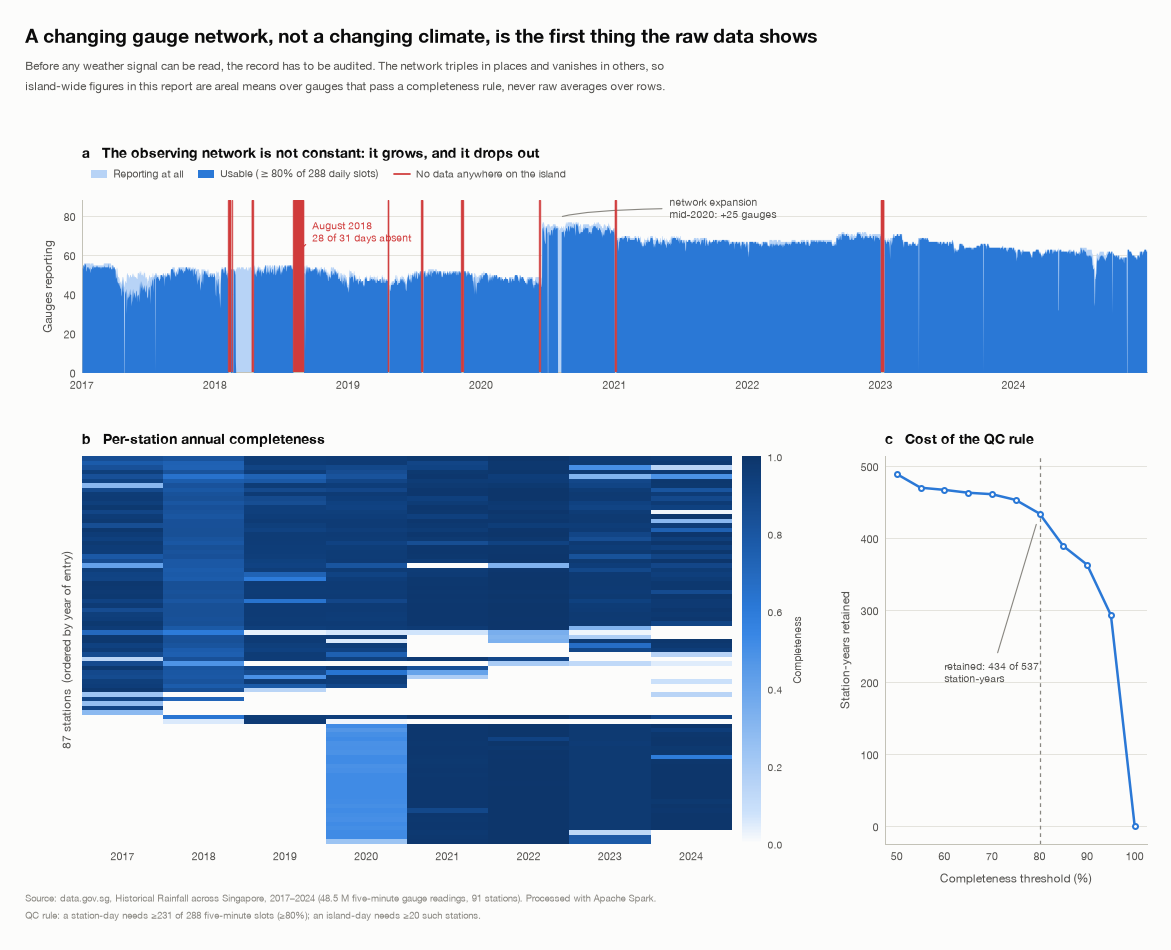

  [figure] outputs/figures/fig01_data_foundation.png


In [18]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
SRC = ("Source: data.gov.sg, Historical Rainfall across Singapore, 2017–2024 "
       "(48.5 M five-minute gauge readings, 91 stations). Processed with Apache Spark.")

def hhmm(minutes: int) -> str:
    return f"{int(minutes) // 60:02d}:{int(minutes) % 60:02d}"


def pad_ylim(ax, below: float = 0.13, above: float = 0.09) -> None:
    """Open up room under a trough and over a peak so that a value label sits
    inside the plot instead of running into the tick labels above or below."""
    lo, hi = ax.get_ylim()
    span = hi - lo
    ax.set_ylim(lo - below * span, hi + above * span)


def fig01_coverage() -> None:
    cov = T("t03_station_year_coverage")
    net = T("t04_daily_network")
    net["date"] = pd.to_datetime(net["date"])

    mat = cov.pivot(index="station_id", columns="year", values="coverage")
    # order stations by first year of service, then by how long they served
    first = mat.apply(lambda r: r.first_valid_index(), axis=1)
    mat = mat.loc[sorted(mat.index, key=lambda s: (first[s], -mat.loc[s].count()))]

    fig = plt.figure(figsize=(13.2, 10.3))
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 2.25], width_ratios=[2.6, 1.0],
                          hspace=0.30, wspace=0.26)

    # -- (a) daily network size -------------------------------------------
    ax = fig.add_subplot(gs[0, :])
    ax.fill_between(net["date"], 0, net["stations_reporting"], color=BLUE_RAMP[1],
                    lw=0, zorder=2, label="Reporting at all")
    ax.fill_between(net["date"], 0, net["stations_usable"], color=BLUE,
                    lw=0, zorder=3, label="Usable ($\\geq$80% of 288 daily slots)")
    gaps = net[net["stations_reporting"] == 0]
    for d in gaps["date"]:
        ax.axvline(d, color=RED, lw=1.1, alpha=0.85, zorder=4)
    ax.set_ylim(0, 88)
    ax.set_ylabel("Gauges reporting")
    ax.set_title("a   The observing network is not constant: it grows, and it drops out",
                 pad=34)
    ax.set_xlim(net["date"].min(), net["date"].max())
    ax.grid(axis="x", visible=False)
    despine(ax)
    ax.annotate("August 2018\n28 of 31 days absent", xy=(pd.Timestamp("2018-08-15"), 58),
                xytext=(pd.Timestamp("2018-09-25"), 72), fontsize=8.2, color=RED,
                ha="left", va="center",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=RED, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=80"))
    ax.annotate("network expansion\nmid-2020: +25 gauges",
                xy=(pd.Timestamp("2020-07-15"), 77), xytext=(pd.Timestamp("2021-06-01"), 84),
                fontsize=8.2, color=INK_2, ha="left", va="center",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    handles = ax.get_legend_handles_labels()[0] + [
        Line2D([0], [0], color=RED, lw=1.4, label="No data anywhere on the island")]
    ax.legend(handles=handles, loc="lower left", ncol=3,
              bbox_to_anchor=(0, 1.06), fontsize=8.4)

    # -- (b) station x year coverage heatmap -------------------------------
    ax = fig.add_subplot(gs[1, 0])
    im = ax.imshow(mat.values, aspect="auto", cmap=CMAP_RAIN, vmin=0, vmax=1,
                   interpolation="nearest")
    ax.set_xticks(range(mat.shape[1]), mat.columns)
    ax.set_yticks([])
    ax.set_ylabel(f"{mat.shape[0]} stations  (ordered by year of entry)")
    ax.set_title("b   Per-station annual completeness")
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.03)
    cb.set_label("Completeness", fontsize=8.2)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)

    # -- (c) how many station-years survive each threshold -----------------
    ax = fig.add_subplot(gs[1, 1])
    ths = np.arange(0.5, 1.001, 0.05)
    counts = [(cov["coverage"] >= t).sum() for t in ths]
    ax.plot(ths * 100, counts, color=BLUE, marker="o", markersize=4,
            markerfacecolor=SURFACE, markeredgewidth=1.6, zorder=3)
    ax.axvline(80, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.annotate(f"retained: {(cov['coverage'] >= 0.8).sum()} of {len(cov)}\nstation-years",
                xy=(80, (cov["coverage"] >= 0.8).sum()), xytext=(60, 200),
                fontsize=8.2, color=INK_2,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9))
    ax.set_xlabel("Completeness threshold (%)")
    ax.set_ylabel("Station-years retained")
    ax.set_title("c   Cost of the QC rule")
    despine(ax)
    ax.grid(axis="x", visible=False)

    layout(fig, header=2.15, footer=1.00, left=1.05)
    titleblock(fig,
                 "A changing gauge network, not a changing climate, is the first thing the raw data shows",
                 "Before any weather signal can be read, the record has to be audited. The network triples in places and vanishes in others, so\n"
                 "island-wide figures in this report are areal means over gauges that pass a completeness rule, never raw averages over rows.")
    sourcenote(fig, SRC + "\nQC rule: a station-day needs ≥231 of 288 five-minute slots (≥80%); an island-day needs ≥20 such stations.")
    save_figure(fig, FIGURES / "fig01_data_foundation.png")


open_pdf(FIGURES / "task1_all_figures.pdf",
         title="DSA5208 Project 2, Task 1: rainfall patterns across Singapore 2017-2024",
         subject="Figures 1-10")
fig01_coverage()

### 4.1 Island-wide daily series and gap filling

In [19]:
def island_series(station_day, min_stations, stations=None):
    """Unweighted mean of usable station-day totals -> one row per island-day."""
    sd = station_day.filter(F.col("usable"))
    if stations is not None:
        sd = sd.filter(F.col("station_id").isin(list(stations)))
    out = (
        sd.groupBy("date", "year", "month", "doy", "season")
        .agg(
            F.count(F.lit(1)).alias("n_stations"),
            F.avg("day_mm").alias("island_mm"),
            F.max("day_mm").alias("wettest_station_mm"),
            F.avg((F.col("day_mm") >= WET_DAY_MM).cast("double")).alias("frac_stations_wet"),
            F.max("max_5min_mm").alias("peak_5min_mm"),
        )
        .filter(F.col("n_stations") >= min_stations)
        .toPandas()
    )
    out["date"] = pd.to_datetime(out["date"])
    out = out.sort_values("date").reset_index(drop=True)
    out["is_wet_day"] = (out["island_mm"] >= WET_DAY_MM).astype(int)
    return out


def gapfill(island_day, calendar):
    """Calendar-complete series; missing days take the (month, day) climatology."""
    full = calendar.merge(island_day[["date", "island_mm"]], on="date", how="left")
    full["year"] = full["date"].dt.year
    full["doy"] = full["date"].dt.dayofyear
    full["md"] = full["date"].dt.month * 100 + full["date"].dt.day
    full["observed"] = full["island_mm"].notna().astype(int)
    clim = full.groupby("md")["island_mm"].mean()
    clim = clim.reindex(sorted(full["md"].unique())).ffill().bfill()   # 29 Feb with no donor
    full["filled_mm"] = full["island_mm"].fillna(full["md"].map(clim))
    return full


with timed("4b. island daily series + gap fill"):
    island_day = island_series(station_day, MIN_STATIONS)
write_table(island_day, "t05_island_daily")
full = gapfill(island_day, calendar)
write_table(full, "t06_island_daily_gapfilled")
island_day.head()

[4b. island daily series + gap fill] 1.1 s
  [table] outputs/tables/t05_island_daily.csv  (2775 rows)
  [table] outputs/tables/t06_island_daily_gapfilled.csv  (2922 rows)


,date,year,month,doy,season,n_stations,island_mm,wettest_station_mm,frac_stations_wet,peak_5min_mm,is_wet_day
0,2017-01-02,2017,1,2,NE Monsoon (Dec-Mar),54,12.359259,63.2,0.833333,8.2,1
1,2017-01-03,2017,1,3,NE Monsoon (Dec-Mar),53,2.358491,17.6,0.377358,3.6,1
2,2017-01-04,2017,1,4,NE Monsoon (Dec-Mar),55,2.407273,11.6,0.763636,3.8,1
3,2017-01-05,2017,1,5,NE Monsoon (Dec-Mar),55,1.821818,8.0,0.854545,5.6,1
4,2017-01-06,2017,1,6,NE Monsoon (Dec-Mar),54,0.133333,5.6,0.018519,2.6,0


### 4.2 Fixed gauge network (for robustness checks)

Because the gauge mix changes, the main temporal results are re-derived in Section 5.3 from a **fixed network**:
the stations with ≥ 80 % coverage in every one of the eight years.

In [20]:
ok_years = (cov.assign(ok=cov["coverage"] >= MIN_SLOT_FRAC)
            .groupby("station_id").agg(n=("year", "size"), ok=("ok", "sum")))
cohort = sorted(ok_years[(ok_years["n"] == len(YEARS)) & (ok_years["ok"] == len(YEARS))].index)
min_fixed = math.ceil(MIN_SLOT_FRAC * len(cohort))
print(f"fixed network: {len(cohort)} stations, an island-day needs >= {min_fixed} of them\n{cohort}")

fixed network: 21 stations, an island-day needs >= 17 of them
['S08', 'S107', 'S113', 'S114', 'S115', 'S116', 'S119', 'S121', 'S24', 'S33', 'S40', 'S43', 'S77', 'S78', 'S79', 'S81', 'S88', 'S89', 'S90', 'S900', 'S94']


### 4.3 Time-window building blocks (shared by Task 1 and Task 2)

Rolling accumulations are Spark window functions over each station's time series. All windows are **time-based**
(`rangeBetween` on epoch seconds) with an explicit count of the slots present, so a gap in the data shortens or
invalidates a window instead of silently pulling in older readings.

**Timestamp convention.** Following the publication delays in Section 2, a row stamped `ts` is taken to cover
[`ts`, `ts`+5 min), complete at clock time `t = ts + 5 min`. For a prediction at `t`, the latest usable reading is
stamped `ts = t − 5 min`, and "the next 30 minutes" are the six slots stamped `ts`+5 … `ts`+30 min. The choice is
conservative: if a stamp instead marked the *end* of its interval, the features (stamps ≤ `ts`) would still end
strictly before the target window (stamps > `ts`), so no future information can leak either way; at worst the
prediction time is labelled 5 minutes later than necessary.

* `add_trailing_features`: rain known at `t` (latest slot, last 15/30/60/180 minutes, 60-minute peak and wet-slot
  count). A window is valid only if every slot in it is present.
* `add_future_target`: rain in the next 30 minutes, valid only if all six future slots exist (never read as dry).
* `add_time_features`: calendar terms at the clock time `t`, with sine/cosine so 23:55 sits next to 00:00.

In [21]:
# definitions
SLOT_SEC = 300


PRED_LAG_SEC = 300


HORIZON_SLOTS = 6


def _w(back_sec: int, fwd_sec: int):
    """Per-station window over epoch seconds, [ts - back, ts + fwd]."""
    return (Window.partitionBy("station_id").orderBy(F.col("ts_s"))
            .rangeBetween(-back_sec, fwd_sec))


def add_future_target(df):
    """Add `future_30min_mm` and `n_future` (slots found in ts+5..ts+30 min).

    `future_30min_mm` is NULL unless all six future slots exist, so an
    incomplete window can never be mistaken for a dry one. Expects columns
    station_id, ts, rain_mm.
    """
    if "ts_s" not in df.columns:
        df = df.withColumn("ts_s", F.col("ts").cast("long"))
    w = (Window.partitionBy("station_id").orderBy("ts_s")
         .rangeBetween(SLOT_SEC, HORIZON_SLOTS * SLOT_SEC))
    return (df.withColumn("n_future", F.count("rain_mm").over(w))
              .withColumn("_fsum", F.sum("rain_mm").over(w))
              .withColumn("future_30min_mm",
                          F.when(F.col("n_future") == HORIZON_SLOTS, F.col("_fsum")))
              .drop("_fsum"))


def add_trailing_features(df):
    """Rainfall known at prediction time: windows END at the anchor slot.

    A window is valid only if every slot in it is present; otherwise the
    feature is NULL and the row is dropped by `complete_rows`.
    """
    if "ts_s" not in df.columns:
        df = df.withColumn("ts_s", F.col("ts").cast("long"))
    out = df.withColumn("r5", F.col("rain_mm"))
    for name, slots in [("acc15", 3), ("acc30", 6), ("acc60", 12), ("acc180", 36)]:
        w = _w((slots - 1) * SLOT_SEC, 0)
        out = (out.withColumn(f"_n{name}", F.count("rain_mm").over(w))
                  .withColumn(name, F.when(F.col(f"_n{name}") == slots,
                                           F.sum("rain_mm").over(w)))
                  .drop(f"_n{name}"))
    w60 = _w(11 * SLOT_SEC, 0)
    out = (out.withColumn("max5_60", F.max("rain_mm").over(w60))
              .withColumn("wet_slots_60",
                          F.sum((F.col("rain_mm") >= WET_5MIN_MM).cast("int")).over(w60))
              .withColumn("is_wet", (F.col("rain_mm") >= WET_5MIN_MM).cast("double")))
    return out


TRAILING_COLS = ["r5", "acc15", "acc30", "acc60", "acc180", "max5_60", "wet_slots_60", "is_wet"]


def add_time_features(df):
    """Calendar features at the CLOCK prediction time t = ts + 5 min (SGT)."""
    t = F.col("ts") + F.expr("INTERVAL 5 MINUTES")
    mod = F.hour(t) * 60 + F.minute(t)
    doy = F.dayofyear(t)
    return (df.withColumn("pred_time", t)
              .withColumn("hour", F.hour(t))
              .withColumn("minute_of_day", mod)
              .withColumn("tod_sin", F.sin(2 * math.pi * mod / 1440.0))
              .withColumn("tod_cos", F.cos(2 * math.pi * mod / 1440.0))
              .withColumn("month", F.month(t))
              .withColumn("doy_sin", F.sin(2 * math.pi * doy / 365.25))
              .withColumn("doy_cos", F.cos(2 * math.pi * doy / 365.25))
              .withColumn("season", season_col(F.month(t))))

---
# Part B — Task 1: weather patterns, within a year and across 2017–2024

Each subsection computes its tables with Spark (written to `outputs/tables/`), draws one figure from them, and
states what it shows.

### 5.1 Annual totals: how much, how often, how hard

  [table] outputs/tables/t07_annual_summary.csv  (8 rows)


,year,days_observed,observed_total_mm,mean_daily_mm,wet_days,p95_daily_mm,max_daily_mm,days_in_year,gapfilled_total_mm,days_missing,wet_days_scaled,stations_active
0,2017,361,2416.0,6.7,236,24.6,71.9,365,2454.3,4,238.6,58
1,2018,273,2051.6,7.5,183,25.9,50.9,365,2655.7,92,244.7,56
2,2019,349,1654.6,4.7,164,24.8,55.2,365,1787.0,16,171.5,54
3,2020,350,2574.5,7.4,220,31.1,68.4,366,2631.0,16,230.1,80
4,2021,360,2850.6,7.9,211,33.6,109.2,365,2899.7,5,213.9,74
5,2022,365,2892.8,7.9,241,29.2,66.0,365,2892.8,0,241.0,72
6,2023,353,2750.8,7.8,221,31.0,152.3,365,2879.2,12,228.5,73
7,2024,364,2681.1,7.4,232,28.9,71.6,366,2708.0,2,233.3,70


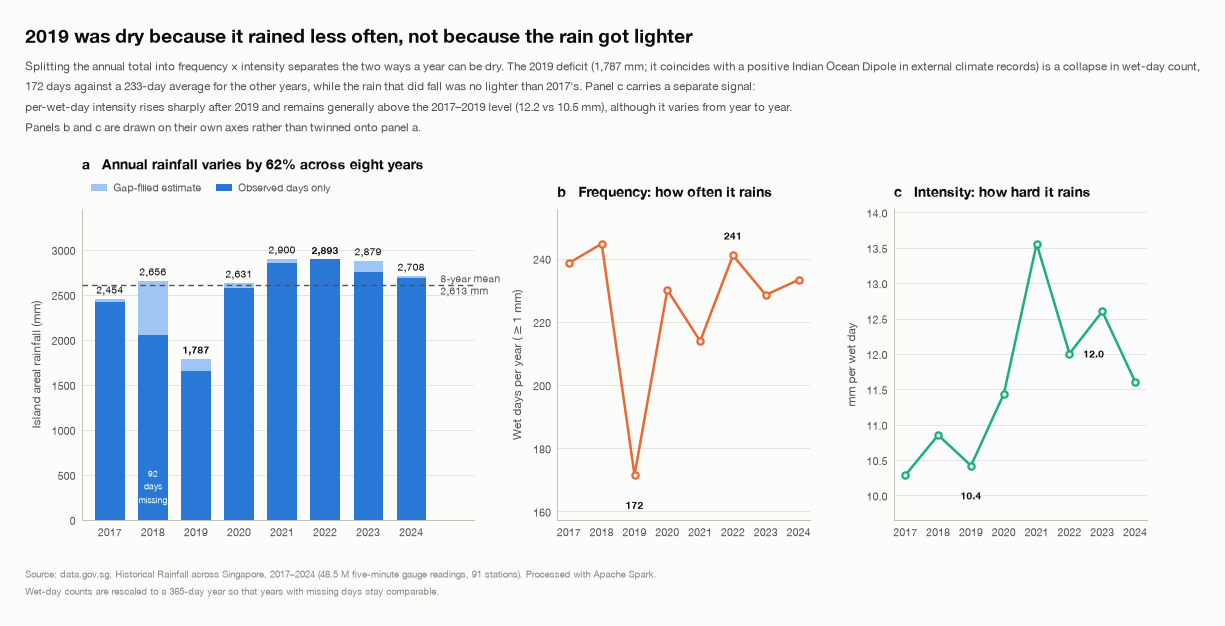

  [figure] outputs/figures/fig02_annual_totals.png


In [22]:
def annual_table(full, cov):
    obs = full[full["observed"] == 1]
    annual = pd.DataFrame({"year": sorted(full["year"].unique())})
    annual = annual.merge(
        obs.groupby("year").agg(
            days_observed=("island_mm", "size"),
            observed_total_mm=("island_mm", "sum"),
            mean_daily_mm=("island_mm", "mean"),
            wet_days=("island_mm", lambda s: int((s >= WET_DAY_MM).sum())),
            p95_daily_mm=("island_mm", lambda s: float(np.percentile(s, 95))),
            max_daily_mm=("island_mm", "max"),
        ).reset_index(), on="year", how="left")
    annual = annual.merge(
        full.groupby("year").agg(
            days_in_year=("island_mm", "size"),
            gapfilled_total_mm=("filled_mm", "sum"),
        ).reset_index(), on="year", how="left")
    annual["days_missing"] = annual["days_in_year"] - annual["days_observed"]
    # scale wet-day count to a full year so the count is comparable across years
    annual["wet_days_scaled"] = (
        annual["wet_days"] * annual["days_in_year"] / annual["days_observed"]
    ).round(1)
    annual = annual.merge(
        cov.groupby("year").agg(stations_active=("station_id", "size")).reset_index(),
        on="year", how="left")
    return annual


annual = annual_table(full, cov)
write_table(annual, "t07_annual_summary")
display(annual.round(1))

def fig02_annual() -> None:
    a = T("t07_annual_summary")
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 6.7),
                             gridspec_kw=dict(width_ratios=[1.55, 1, 1], wspace=0.28))
    x = np.arange(len(a))

    ax = axes[0]
    ax.bar(x, a["gapfilled_total_mm"], color=BLUE_RAMP[2], width=0.68,
           zorder=2, label="Gap-filled estimate")
    ax.bar(x, a["observed_total_mm"], color=BLUE, width=0.68, zorder=3,
           label="Observed days only")
    mean = a["gapfilled_total_mm"].mean()
    ax.axhline(mean, color=INK_2, lw=1.1, ls=(0, (4, 3)), zorder=4)
    ax.text(len(a) - 0.32, mean, f"8-year mean\n{mean:,.0f} mm", ha="left",
            va="center", fontsize=8.2, color=INK_2)
    for i, r in a.iterrows():
        ax.text(i, r["gapfilled_total_mm"] + 60, f"{r['gapfilled_total_mm']:,.0f}",
                ha="center", fontsize=8.2, color=INK,
                fontweight="semibold" if r["year"] in (2019, 2022) else "normal")
        if r["days_missing"] > 20:
            ax.text(i, 130, f"{int(r['days_missing'])}\ndays\nmissing", ha="center",
                    va="bottom", fontsize=7.0, color="white", zorder=5,
                    linespacing=1.35)
    ax.set_xticks(x, a["year"])
    ax.set_ylim(0, 3450)
    ax.set_xlim(-0.65, len(a) + 0.45)
    ax.set_ylabel("Island areal rainfall (mm)")
    ax.set_title(f"a   Annual rainfall varies by {100 * (a['gapfilled_total_mm'].max() / a['gapfilled_total_mm'].min() - 1):.0f}% across eight years", pad=32)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    ax.plot(x, a["wet_days_scaled"], color=ORANGE, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for i, v in enumerate(a["wet_days_scaled"]):
        if a["year"][i] in (2019, 2022):
            high = a["year"][i] == 2022          # 2022 is a peak, 2019 a trough
            ax.annotate(f"{v:.0f}", (i, v), textcoords="offset points",
                        xytext=(0, 11 if high else -19), ha="center",
                        va="bottom" if high else "top", fontsize=8.2,
                        color=INK, fontweight="semibold")
    ax.set_xticks(x, a["year"])
    ax.set_ylabel("Wet days per year ($\\geq$1 mm)")
    ax.set_title("b   Frequency: how often it rains")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    ax = axes[2]
    intensity = a["gapfilled_total_mm"] / a["wet_days_scaled"]
    ax.plot(x, intensity, color=AQUA, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for i, v in enumerate(intensity):
        if a["year"][i] in (2019, 2022):
            # 2019 is a trough; 2022 sits mid-slope, so its label goes out to
            # the right where the line has already passed
            below = a["year"][i] == 2019
            ax.annotate(f"{v:.1f}", (i, v), textcoords="offset points",
                        xytext=(0 if below else 11, -19 if below else 0),
                        ha="center" if below else "left",
                        va="top" if below else "center", fontsize=8.2,
                        color=INK, fontweight="semibold")
    ax.set_xticks(x, a["year"])
    ax.set_ylabel("mm per wet day")
    ax.set_title("c   Intensity: how hard it rains")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    y19, y17 = a[a["year"] == 2019].iloc[0], a[a["year"] == 2017].iloc[0]
    norm_wet = a.loc[a["year"] != 2019, "wet_days_scaled"].mean()
    post = intensity[a["year"] >= 2020]
    pre = intensity[a["year"] <= 2019]
    layout(fig, header=2.25, footer=1.00, left=1.05)
    titleblock(fig,
                 "2019 was dry because it rained less often, not because the rain got lighter",
                 f"Splitting the annual total into frequency \u00d7 intensity separates the two ways a year can be dry. The 2019 deficit "
                 f"({y19['gapfilled_total_mm']:,.0f} mm; it coincides with a positive Indian Ocean Dipole in external climate records) is a collapse in wet-day count,\n"
                 f"{y19['wet_days_scaled']:.0f} days against a {norm_wet:.0f}-day average for the other years, while the rain that did fall was no lighter than 2017's. "
                 f"Panel c carries a separate signal:\nper-wet-day intensity rises sharply after 2019 and remains generally above the 2017\u20132019 level "
                 f"({post.mean():.1f} vs {pre.mean():.1f} mm), although it varies from year to year.\n"
                 "Panels b and c are drawn on their own axes rather than twinned onto panel a.")
    sourcenote(fig, SRC + "\nWet-day counts are rescaled to a 365-day year so that years with missing days stay comparable.")
    save_figure(fig, FIGURES / "fig02_annual_totals.png")


fig02_annual()

**Observations.** Annual island rainfall ranges from **1,787 mm (2019) to 2,900 mm (2021)**, a 62 % spread around a
2,613 mm mean; 2022 is a near-tie at 2,893 mm. 2018 has 92 unusable days (August 2018 is almost absent from the source),
so its observed total understates the year and only the gap-filled value is comparable. Splitting the total into
frequency × intensity shows that **2019 was dry because it rained less often** (172 wet days against a 233-day average
for the other years), not because the rain was lighter: its 10.4 mm per wet day matches 2017's 10.3 mm.

### 5.2 The seasonal cycle

  [table] outputs/tables/t08_monthly.csv  (96 rows)
  [table] outputs/tables/t09_seasonal.csv  (32 rows)


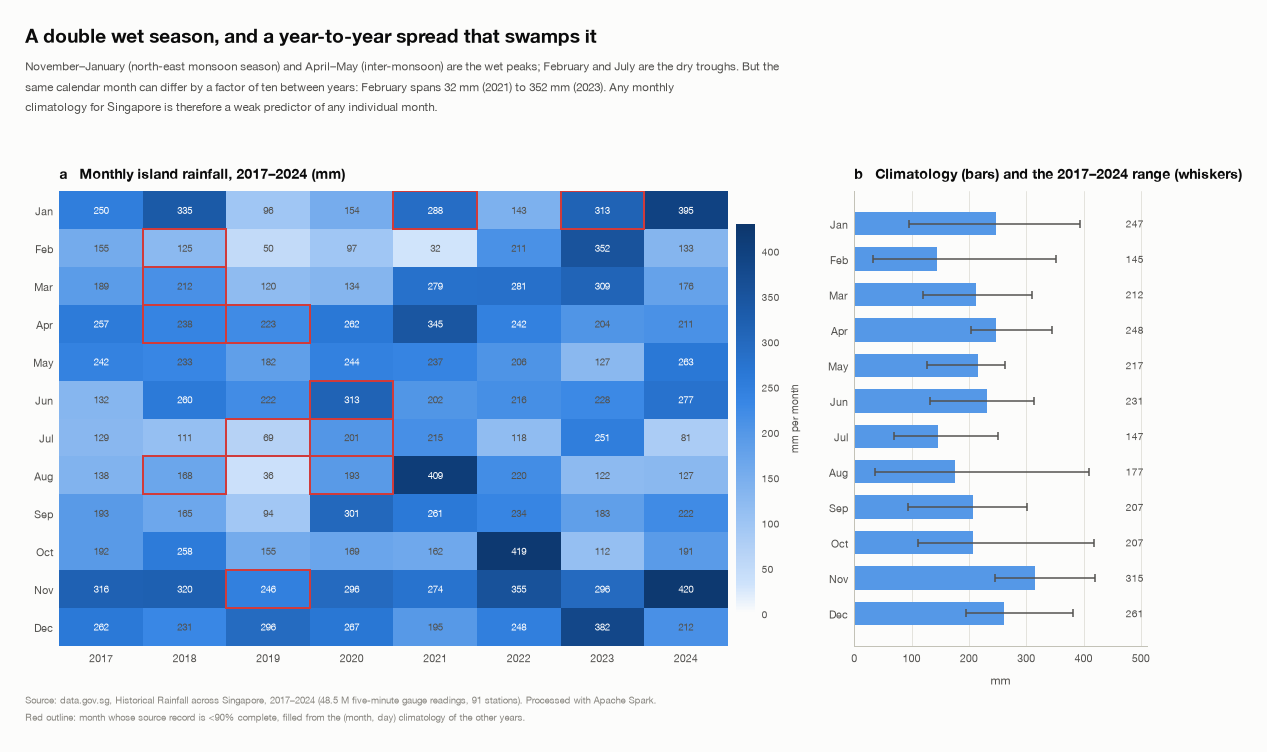

  [figure] outputs/figures/fig03_seasonal_cycle.png


In [23]:
def monthly_table(full):
    mon = full.copy()
    mon["month"] = mon["date"].dt.month
    monthly = mon.groupby(["year", "month"]).agg(
        total_mm=("filled_mm", "sum"),
        observed_total_mm=("island_mm", "sum"),
        days_observed=("observed", "sum"),
        days=("observed", "size"),
    ).reset_index()
    monthly["complete"] = (monthly["days_observed"] >= 0.9 * monthly["days"]).astype(int)
    clim_m = monthly.groupby("month")["total_mm"].mean().rename("clim_mm")
    monthly = monthly.merge(clim_m, on="month")
    monthly["anomaly_mm"] = monthly["total_mm"] - monthly["clim_mm"]
    monthly["anomaly_pct"] = 100 * monthly["anomaly_mm"] / monthly["clim_mm"]
    return monthly


monthly = monthly_table(full)
write_table(monthly.sort_values(["year", "month"]), "t08_monthly")
seasonal = (island_day.groupby(["year", "season"])
            .agg(observed_mm=("island_mm", "sum"), days=("island_mm", "size"), mean_daily_mm=("island_mm", "mean"))
            .reset_index())
write_table(seasonal, "t09_seasonal")

def fig03_seasonal() -> None:
    m = T("t08_monthly")
    grid = m.pivot(index="month", columns="year", values="total_mm")
    clim = m.groupby("month")["total_mm"].mean()

    fig = plt.figure(figsize=(13.2, 8.1))
    gs = fig.add_gridspec(1, 2, width_ratios=[2.5, 1.05], wspace=0.2)

    ax = fig.add_subplot(gs[0, 0])
    im = ax.imshow(grid.values, aspect="auto", cmap=CMAP_RAIN, vmin=0, vmax=430,
                   interpolation="nearest")
    ax.set_xticks(range(grid.shape[1]), grid.columns)
    ax.set_yticks(range(12), MONTHS)
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    for i in range(12):
        for j in range(grid.shape[1]):
            v = grid.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7.9,
                    color="white" if v > 240 else INK_2)
    # mark months whose source record is incomplete
    inc = m[m["complete"] == 0]
    for _, r in inc.iterrows():
        ax.add_patch(Rectangle((list(grid.columns).index(r["year"]) - 0.5,
                                r["month"] - 1.5), 1, 1, fill=False,
                               edgecolor=RED, lw=1.6, zorder=5))
    ax.set_title("a   Monthly island rainfall, 2017–2024 (mm)")
    cb = fig.colorbar(im, ax=ax, pad=0.012, fraction=0.028)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("mm per month", fontsize=8.2)

    ax = fig.add_subplot(gs[0, 1])
    y = np.arange(12)
    ax.barh(y, clim.values, color=BLUE_RAMP[5], height=0.66, zorder=2)
    lo = grid.min(axis=1).values
    hi = grid.max(axis=1).values
    ax.hlines(y, lo, hi, color=INK_2, lw=1.2, zorder=3)
    ax.plot(lo, y, "|", color=INK_2, markersize=7, markeredgewidth=1.2, zorder=3)
    ax.plot(hi, y, "|", color=INK_2, markersize=7, markeredgewidth=1.2, zorder=3)
    # values as a right-hand column so the range whiskers never cross them
    for i, v in enumerate(clim.values):
        ax.text(505, i, f"{v:.0f}", va="center", ha="right", fontsize=8.2,
                color=INK_2, zorder=4)
    ax.set_yticks(y, MONTHS)
    ax.invert_yaxis()
    ax.set_xlim(0, 510)
    ax.set_xlabel("mm")
    ax.set_title("b   Climatology (bars) and the 2017\u20132024 range (whiskers)")
    despine(ax)
    ax.grid(axis="y", visible=False)

    layout(fig, header=2.05, footer=1.00, left=0.8)
    titleblock(fig,
                 "A double wet season, and a year-to-year spread that swamps it",
                 "November–January (north-east monsoon season) and April–May (inter-monsoon) are the wet peaks; February and July are the dry "
                 "troughs. But the\nsame calendar month can differ by a factor of ten between years: "
                 f"February spans {grid.loc[2].min():.0f} mm ({grid.loc[2].idxmin()}) to {grid.loc[2].max():.0f} mm ({grid.loc[2].idxmax()}). "
                 "Any monthly\nclimatology for Singapore is therefore a weak predictor of any individual month.")
    sourcenote(fig, SRC + "\nRed outline: month whose source record is <90% complete, filled from the (month, day) climatology of the other years.")
    save_figure(fig, FIGURES / "fig03_seasonal_cycle.png")


fig03_seasonal()

**Observations.** Two wet seasons: **November–January** (north-east monsoon) and **April–May** (inter-monsoon);
February and July are the driest months. The same calendar month varies by up to a factor of ten between years,
so a monthly climatology alone is a weak predictor of any particular month.

### 5.3 Robustness: does the changing network distort the results?

The annual and monthly products are recomputed on the fixed 21-gauge network (Section 4.2) and compared with
pre-declared pass/fail checks. Figure 4 then shows the monthly anomalies.

In [24]:
def spearman(a, b):
    """Rank correlation without a SciPy dependency."""
    return a.rank().corr(b.rank())


def mann_kendall(years, values):
    """Mann-Kendall trend test with Sen's slope, without a SciPy dependency.

    The two-sided p-value is exact: Kendall's S is recomputed for every
    ordering of the values (8! = 40,320 for 2017-2024). With eight points the
    test has little power, so p > 0.05 means "not shown", not "no change".
    """
    x = np.asarray(years, float)
    y = np.asarray(values, float)
    i, j = np.triu_indices(len(y), 1)
    s_obs = np.sign(y[j] - y[i]).sum()
    perms = np.array(list(itertools.permutations(y)))
    s_null = np.sign(perms[:, j] - perms[:, i]).sum(axis=1)
    return {"kendall_tau": s_obs / len(i),
            "p_value_exact": float(np.mean(np.abs(s_null) >= abs(s_obs) - 1e-9)),
            "sen_slope_per_year": float(np.median((y[j] - y[i]) / (x[j] - x[i])))}


def longest_below_run(monthly):
    """Longest unbroken run of below-average months (anomaly < 0)."""
    best = run = 0
    for v in monthly.sort_values(["year", "month"])["anomaly_mm"]:
        run = run + 1 if v < 0 else 0
        best = max(best, run)
    return best


def sensitivity_annual(full_a, fx_a, n_cohort):
    """Side-by-side annual results. Absolute levels differ between networks
    (different gauges), so shape is compared via an index to each network's own
    8-year mean."""
    out = pd.DataFrame({"year": full_a["year"]})
    for tag, a in [("full", full_a), ("fixed", fx_a)]:
        out[f"total_mm_{tag}"] = a["gapfilled_total_mm"].round(1)
        out[f"index_{tag}"] = (100 * a["gapfilled_total_mm"] / a["gapfilled_total_mm"].mean()).round(1)
        out[f"rank_{tag}"] = a["gapfilled_total_mm"].rank(ascending=False).astype(int)
        out[f"wet_days_{tag}"] = a["wet_days_scaled"]
        out[f"mm_per_wet_day_{tag}"] = (a["gapfilled_total_mm"] / a["wet_days_scaled"]).round(2)
        out[f"days_missing_{tag}"] = a["days_missing"]
    out["index_diff_pp"] = (out["index_fixed"] - out["index_full"]).round(1)
    out["n_stations_fixed"] = n_cohort
    return out


def sensitivity_monthly(full_m, fx_m):
    out = pd.DataFrame({"month": range(1, 13)})
    for tag, m in [("full", full_m), ("fixed", fx_m)]:
        c = m.groupby("month")["total_mm"].mean()
        out[f"clim_mm_{tag}"] = out["month"].map(c).round(1)
        out[f"share_pct_{tag}"] = (100 * out[f"clim_mm_{tag}"] / out[f"clim_mm_{tag}"].sum()).round(2)
        out[f"rank_{tag}"] = out[f"clim_mm_{tag}"].rank(ascending=False).astype(int)
    out["share_diff_pp"] = (out["share_pct_fixed"] - out["share_pct_full"]).round(2)
    return out


def sensitivity_summary(full_a, fx_a, full_m, fx_m, cohort, min_fixed):
    rows = []

    def add(metric, value, note=""):
        rows.append({"metric": metric, "value": value, "note": note})

    ta, tf = full_a["gapfilled_total_mm"], fx_a["gapfilled_total_mm"]
    ia, i_f = ta / ta.mean(), tf / tf.mean()
    add("fixed_network_stations", len(cohort), ",".join(cohort))
    add("fixed_island_day_min_stations", min_fixed, "80% of the cohort")
    add("annual_total_spearman", round(float(spearman(ta, tf)), 3), "rank agreement")
    add("annual_total_pearson", round(float(ta.corr(tf)), 3), "")
    add("wettest_year_full/fixed", f"{int(full_a.loc[ta.idxmax(), 'year'])}/{int(fx_a.loc[tf.idxmax(), 'year'])}", "")
    add("driest_year_full/fixed", f"{int(full_a.loc[ta.idxmin(), 'year'])}/{int(fx_a.loc[tf.idxmin(), 'year'])}", "")
    add("max_abs_annual_index_diff_pp", round(float((100 * (i_f - ia)).abs().max()), 1),
        "index to own 8-yr mean, percentage points")
    add("annual_range_pct_full/fixed",
        f"{100 * (ta.max() / ta.min() - 1):.0f}/{100 * (tf.max() / tf.min() - 1):.0f}", "(max/min - 1)")
    wa, wf = full_a["wet_days_scaled"], fx_a["wet_days_scaled"]
    add("wet_days_spearman", round(float(spearman(wa, wf)), 3), "")
    inta, intf = ta / wa, tf / wf
    pre = full_a["year"] <= 2019
    add("intensity_every_year_2020-24_above_2017-19_mean_full/fixed",
        f"{bool((inta[~pre] > inta[pre].mean()).all())}/{bool((intf[~pre] > intf[pre].mean()).all())}",
        "mm per wet day")
    add("intensity_2020-24_mean_vs_2017-19_mean_pct_full/fixed",
        f"{100 * (inta[~pre].mean() / inta[pre].mean() - 1):.0f}/{100 * (intf[~pre].mean() / intf[pre].mean() - 1):.0f}", "")
    ca = full_m.groupby("month")["total_mm"].mean()
    cf = fx_m.groupby("month")["total_mm"].mean()
    add("monthly_climatology_spearman", round(float(spearman(ca, cf)), 3), "")
    add("wettest_month_full/fixed", f"{int(ca.idxmax())}/{int(cf.idxmax())}", "")
    add("driest_month_full/fixed", f"{int(ca.idxmin())}/{int(cf.idxmin())}", "")
    fm = full_m.sort_values(["year", "month"]).reset_index(drop=True)
    xm = fx_m.sort_values(["year", "month"]).reset_index(drop=True)
    add("monthly_anomaly_pct_pearson", round(float(fm["anomaly_pct"].corr(xm["anomaly_pct"])), 3), "96 months")
    add("monthly_anomaly_sign_agreement_pct",
        round(float(100 * (np.sign(fm["anomaly_mm"]) == np.sign(xm["anomaly_mm"])).mean()), 1), "")
    add("longest_below_average_run_months_full/fixed",
        f"{longest_below_run(full_m)}/{longest_below_run(fx_m)}", "")
    # how many months of the full network's longest run are also below average
    # in the fixed network? (distinguishes a flipped marginal month from a
    # genuinely different drought)
    neg = (fm["anomaly_mm"] < 0).to_numpy()
    best = run = end = 0
    for i, flag in enumerate(neg):
        run = run + 1 if flag else 0
        if run > best:
            best, end = run, i
    win = slice(end - best + 1, end + 1)
    add("below_average_months_in_full_longest_run_full/fixed",
        f"{int(neg[win].sum())}/{int((xm['anomaly_mm'].to_numpy()[win] < 0).sum())}",
        f"{fm['year'][end - best + 1]}-{fm['month'][end - best + 1]:02d} to {fm['year'][end]}-{fm['month'][end]:02d}")
    changed = [f"{int(y)} (full #{rf_}, fixed #{rx_}, index {a_:.1f}/{b_:.1f})"
               for y, rf_, rx_, a_, b_ in zip(
                   full_a["year"], ta.rank(ascending=False), tf.rank(ascending=False),
                   100 * ia, 100 * i_f) if rf_ != rx_]
    add("years_whose_rank_changes", "; ".join(changed) or "none",
        "all swaps are between years whose index differs by only a few percentage points")
    # pre-declared headline checks (not tuned after seeing the result)
    checks = {
        "driest year identical": full_a.loc[ta.idxmin(), "year"] == fx_a.loc[tf.idxmin(), "year"],
        "annual totals Pearson >= 0.95": ta.corr(tf) >= 0.95,
        "max annual index difference <= 5 pp": float((100 * (i_f - ia)).abs().max()) <= 5.0,
        "annual range within 5 pp": abs(100 * ((ta.max() / ta.min()) - (tf.max() / tf.min()))) <= 5.0,
        "monthly climatology Spearman >= 0.9, wettest & driest month identical":
            spearman(ca, cf) >= 0.9 and ca.idxmax() == cf.idxmax() and ca.idxmin() == cf.idxmin(),
        "monthly anomaly r >= 0.9": fm["anomaly_pct"].corr(xm["anomaly_pct"]) >= 0.9,
        "post-2019 intensity above 2017-19 level in both":
            bool((inta[~pre] > inta[pre].mean()).all() and (intf[~pre] > intf[pre].mean()).all()),
    }
    for k, v in checks.items():
        add(f"check: {k}", "PASS" if v else "FAIL")
    add("verdict", "HEADLINE CONCLUSIONS ROBUST" if all(checks.values()) else "MATERIAL CHANGE - REVIEW",
        "see years_whose_rank_changes and longest_below_average_run for the fragile details")
    return pd.DataFrame(rows)


with timed("5.3 fixed-network sensitivity"):
    fx_day = island_series(station_day, min_fixed, cohort)
fx_full = gapfill(fx_day, calendar)
fx_annual = annual_table(fx_full, cov[cov["station_id"].isin(cohort)])
fx_monthly = monthly_table(fx_full)
write_table(sensitivity_annual(annual, fx_annual, len(cohort)), "t22_sensitivity_annual")
write_table(sensitivity_monthly(monthly, fx_monthly), "t23_sensitivity_monthly")
sens = write_table(sensitivity_summary(annual, fx_annual, monthly, fx_monthly, cohort, min_fixed),
                   "t24_sensitivity_summary")
sens[sens["metric"] != "fixed_network_stations"]

[5.3 fixed-network sensitivity] 1.1 s
  [table] outputs/tables/t22_sensitivity_annual.csv  (8 rows)
  [table] outputs/tables/t23_sensitivity_monthly.csv  (12 rows)
  [table] outputs/tables/t24_sensitivity_summary.csv  (27 rows)


,metric,value,note
1,fixed_island_day_min_stations,17,80% of the cohort
2,annual_total_spearman,0.881,rank agreement
3,annual_total_pearson,0.986,
4,wettest_year_full/fixed,2021/2021,
5,driest_year_full/fixed,2019/2019,
6,max_abs_annual_index_diff_pp,3.2,"index to own 8-yr mean, percentage points"
7,annual_range_pct_full/fixed,62/61,(max/min - 1)
8,wet_days_spearman,0.952,
9,intensity_every_year_2020-24_above_2017-19_mea...,True/True,mm per wet day
10,intensity_2020-24_mean_vs_2017-19_mean_pct_ful...,16/14,


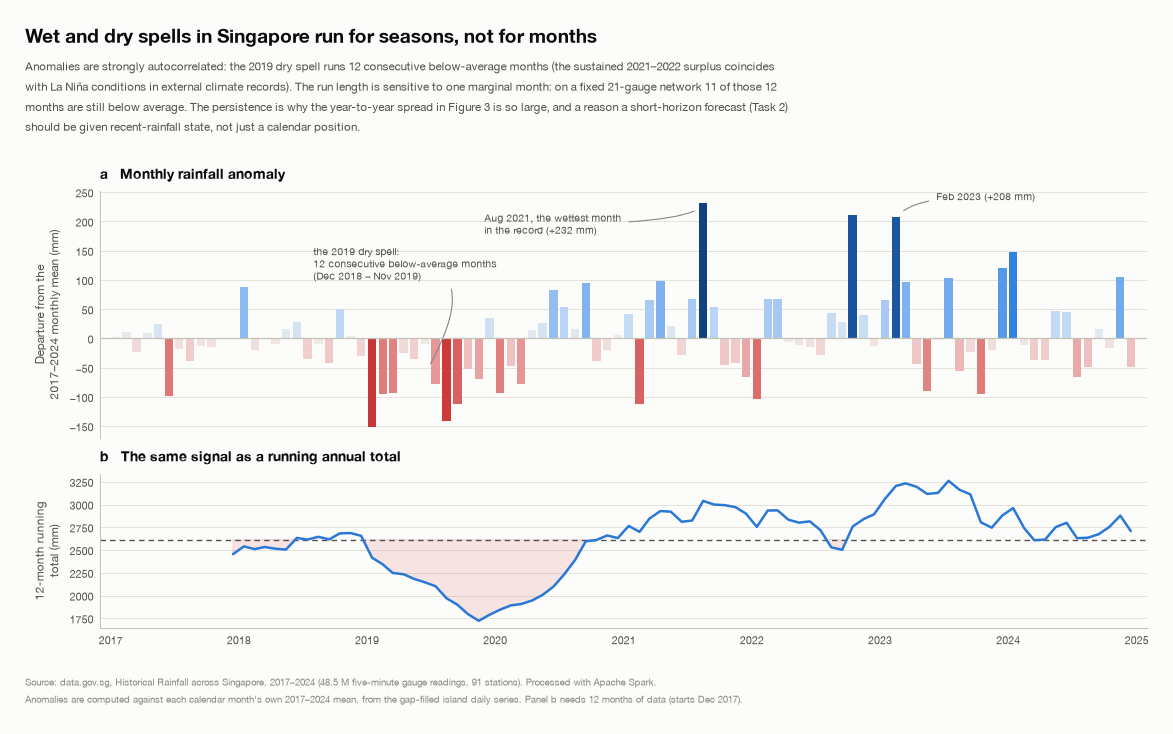

  [figure] outputs/figures/fig04_monthly_anomaly.png


In [25]:
def fig04_anomaly() -> None:
    m = T("t08_monthly").sort_values(["year", "month"]).reset_index(drop=True)
    m["t"] = pd.to_datetime(dict(year=m["year"], month=m["month"], day=15))
    v = m["anomaly_mm"].to_numpy()
    lim = np.abs(v).max()
    colors = CMAP_ANOM((v / (2 * lim)) + 0.5)

    fig, axes = plt.subplots(2, 1, figsize=(13.2, 7.9), sharex=True,
                             gridspec_kw=dict(height_ratios=[1.6, 1], hspace=0.18))

    ax = axes[0]
    ax.bar(m["t"], v, width=24, color=colors, zorder=3)
    ax.axhline(0, color=AXIS, lw=1, zorder=4)
    ax.set_ylabel("Departure from the\n2017–2024 monthly mean (mm)")
    ax.set_title("a   Monthly rainfall anomaly")
    despine(ax, bottom=True)
    ax.grid(axis="x", visible=False)
    ax.set_xlim(m["t"].min() - pd.Timedelta(days=45),
                m["t"].max() + pd.Timedelta(days=45))

    # measure the longest unbroken run of below-average months rather than
    # asserting a round number in the caption
    neg = (v < 0).astype(int)
    best = run = 0
    best_end = 0
    for i, flag in enumerate(neg):
        run = run + 1 if flag else 0
        if run > best:
            best, best_end = run, i
    run_start, run_end = m["t"].iloc[best_end - best + 1], m["t"].iloc[best_end]
    sens = T("t24_sensitivity_summary").set_index("metric")["value"]
    n_fixed = int(sens["fixed_network_stations"])
    fixed_neg = sens["below_average_months_in_full_longest_run_full/fixed"].split("/")[1]
    top = m.nlargest(3, "anomaly_mm")
    wet1, wet3 = top.iloc[0], m[(m["year"] == 2023) & (m["month"] == 2)].iloc[0]
    for lbl, xy, xytext in [
        (f"the 2019 dry spell:\n{best} consecutive below-average months\n"
         f"({run_start:%b %Y} \u2013 {run_end:%b %Y})",
         (pd.Timestamp("2019-06-15"), -60), (pd.Timestamp("2018-08-01"), 128)),
        (f"{wet1['t']:%b %Y}, the wettest month\nin the record (+{wet1['anomaly_mm']:.0f} mm)",
         (wet1["t"], wet1["anomaly_mm"] - 3), (pd.Timestamp("2019-12-01"), 196)),
        (f"{wet3['t']:%b %Y} (+{wet3['anomaly_mm']:.0f} mm)",
         (wet3["t"], wet3["anomaly_mm"] - 3), (pd.Timestamp("2023-06-10"), 243)),
    ]:
        ax.annotate(lbl, xy=xy, xytext=xytext, fontsize=8.2, color=INK_2,
                    ha="left", va="center",
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=MUTED, lw=0.9,
                                    connectionstyle="angle3,angleA=0,angleB=60"))

    ax = axes[1]
    roll = m.set_index("t")["total_mm"].rolling(12, min_periods=12).sum()   # genuine 12-month window
    ax.plot(roll.index, roll.values, color=BLUE, zorder=3)
    ax.axhline(T("t07_annual_summary")["gapfilled_total_mm"].mean(), color=INK_2,
               lw=1.1, ls=(0, (4, 3)), zorder=2)
    ax.fill_between(roll.index, roll.values,
                    T("t07_annual_summary")["gapfilled_total_mm"].mean(),
                    where=roll.values < T("t07_annual_summary")["gapfilled_total_mm"].mean(),
                    color=RED, alpha=0.13, zorder=1, interpolate=True)
    ax.set_ylabel("12-month running\ntotal (mm)")
    ax.set_title("b   The same signal as a running annual total")
    despine(ax)
    ax.grid(axis="x", visible=False)

    layout(fig, header=2.05, footer=1.00, left=1.25)
    titleblock(fig,
                 "Wet and dry spells in Singapore run for seasons, not for months",
                 f"Anomalies are strongly autocorrelated: the 2019 dry spell runs {best} consecutive below-average months (the sustained 2021–2022 "
                 "surplus coincides\nwith La Niña conditions in external climate records). The run length is sensitive to one marginal month: on a fixed "
                 f"{n_fixed}-gauge network {fixed_neg} of those {best}\nmonths are still below average. The persistence is why the year-to-year spread in Figure 3 is so large, and a reason "
                 "a short-horizon forecast (Task 2)\nshould be given recent-rainfall state, not just a calendar position.")
    sourcenote(fig, SRC + "\nAnomalies are computed against each calendar month's own 2017–2024 mean, from the gap-filled island daily series. Panel b needs 12 months of data (starts Dec 2017).")
    save_figure(fig, FIGURES / "fig04_monthly_anomaly.png")


fig04_anomaly()

**Observations.** Every pre-declared check passes: annual totals on the two networks correlate at r = 0.99, the
driest year (2019) and the wettest and driest months are identical, and monthly anomalies agree in sign 98 % of the
time. Only close calls change: 2022/2023 and 2020/2024 swap places (each pair within a few percentage points), and the 2019 dry spell is 12 consecutive below-average
months on the full network but 11 of those 12 on the fixed network. Wet and dry spells persist for whole seasons,
which is one reason Task 2 needs the recent-rainfall state and not just the calendar.

### 5.4 The diurnal cycle: when during the day it rains

[5.4 diurnal cycle] 1.6 s
  [table] outputs/tables/t10_diurnal_month_year.csv  (4608 rows)
  [table] outputs/tables/t11_diurnal_station_season.csv  (16416 rows)


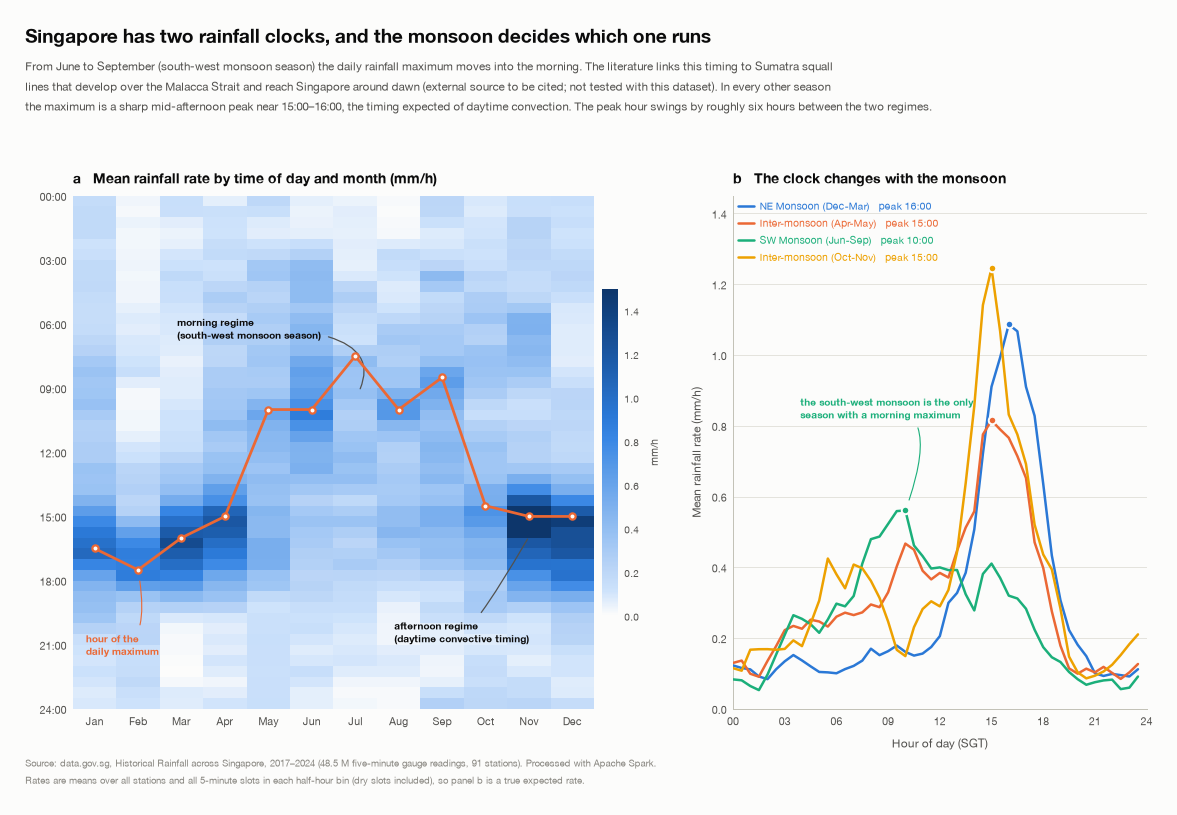

  [figure] outputs/figures/fig05_diurnal_cycle.png


In [26]:
halfhour = (F.floor(F.col("minute_of_day") / F.lit(30)) * F.lit(30)).alias("hh_min")
with timed("5.4 diurnal cycle"):
    diurnal = (df.withColumn("hh_min", halfhour)
               .groupBy("year", "month", "season", "hh_min")
               .agg(F.avg("rain_mm").alias("mean_mm_per_5min"),
                    F.avg((F.col("rain_mm") >= WET_5MIN_MM).cast("double")).alias("wet_frac"),
                    F.count(F.lit(1)).alias("n"))
               .withColumn("mm_per_hour", F.col("mean_mm_per_5min") * F.lit(12))
               .toPandas())
    diurnal_station = (df.withColumn("hh_min", halfhour)
                       .groupBy("station_id", "season", "hh_min")
                       .agg(F.avg("rain_mm").alias("mean_mm_per_5min"))
                       .withColumn("mm_per_hour", F.col("mean_mm_per_5min") * F.lit(12))
                       .toPandas())
write_table(diurnal, "t10_diurnal_month_year")
write_table(diurnal_station, "t11_diurnal_station_season")

def fig05_diurnal() -> None:
    d = T("t10_diurnal_month_year")
    grid = (d.groupby(["hh_min", "month"])["mm_per_hour"].mean()
            .unstack("month").sort_index())

    fig = plt.figure(figsize=(13.2, 8.8))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.45, 1.1], wspace=0.24)

    # -- (a) hour x month heatmap -----------------------------------------
    ax = fig.add_subplot(gs[0, 0])
    im = ax.pcolormesh(np.arange(13), np.arange(49) * 0.5, grid.values,
                       cmap=CMAP_RAIN, vmin=0, vmax=1.5, shading="flat")
    ax.set_xticks(np.arange(12) + 0.5, MONTHS)
    ax.set_yticks(np.arange(0, 25, 3), [f"{h:02d}:00" for h in range(0, 25, 3)])
    ax.set_ylim(0, 24)
    ax.invert_yaxis()
    ax.grid(visible=False)
    for s in ax.spines.values():
        s.set_visible(False)
    # trace the daily maximum
    peak = grid.idxmax(axis=0) / 60.0
    ax.plot(np.arange(12) + 0.5, peak.values, color=ORANGE, lw=2.2,
            marker="o", markersize=5, markerfacecolor=SURFACE,
            markeredgewidth=1.8, zorder=5)
    ax.annotate("hour of the\ndaily maximum", xy=(1.5, peak.values[1]),
                xytext=(0.30, 21.0), fontsize=8.2, color=ORANGE,
                ha="left", va="center", fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=ORANGE, lw=0.9,
                                connectionstyle="angle3,angleA=10,angleB=-80"))
    ax.set_title("a   Mean rainfall rate by time of day and month (mm/h)")
    ax.annotate("morning regime\n(south-west monsoon season)", xy=(6.5, 9.5), xytext=(2.4, 6.2),
                fontsize=8.4, color=INK, ha="left", va="center", fontweight="semibold",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=1.0,
                                connectionstyle="angle3,angleA=0,angleB=60"))
    ax.annotate("afternoon regime\n(daytime convective timing)", xy=(10.6, 15.6), xytext=(7.4, 20.4),
                fontsize=8.4, color=INK, ha="left", va="center", fontweight="semibold",
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=1.0,
                                connectionstyle="angle3,angleA=0,angleB=60"))
    cb = fig.colorbar(im, ax=ax, pad=0.014, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("mm/h", fontsize=8.2)

    # -- (b) seasonal diurnal profiles ------------------------------------
    ax = fig.add_subplot(gs[0, 1])
    ds = d.groupby(["season", "hh_min"])["mm_per_hour"].mean().reset_index()
    for name in SEASON_ORDER:
        s = ds[ds["season"] == name].sort_values("hh_min")
        pk = s.loc[s["mm_per_hour"].idxmax()]
        ax.plot(s["hh_min"] / 60.0, s["mm_per_hour"], color=SEASON_COLOR[name],
                zorder=3, label=f"{name}   peak {hhmm(pk['hh_min'])}")
        ax.plot(pk["hh_min"] / 60, pk["mm_per_hour"], "o", color=SEASON_COLOR[name],
                markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.6, zorder=4)
    ax.legend(loc="upper left", fontsize=8.2, bbox_to_anchor=(-0.01, 1.01),
              labelcolor="linecolor")
    ax.annotate("the south-west monsoon is the only\nseason with a morning maximum",
                xy=(10.0, 0.56), xytext=(3.9, 0.85), fontsize=8.3, color=AQUA,
                ha="left", va="center", fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=AQUA, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    ax.set_xlim(0, 24)
    ax.set_xticks(range(0, 25, 3), [f"{h:02d}" for h in range(0, 25, 3)])
    ax.set_xlabel("Hour of day (SGT)")
    ax.set_ylabel("Mean rainfall rate (mm/h)")
    ax.set_title("b   The clock changes with the monsoon")
    despine(ax)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 1.45)

    layout(fig, header=2.1, footer=1.00, left=0.95)
    titleblock(fig,
                 "Singapore has two rainfall clocks, and the monsoon decides which one runs",
                 "From June to September (south-west monsoon season) the daily rainfall maximum moves into the morning. The literature links this "
                 "timing to Sumatra squall\nlines that develop over the Malacca Strait and reach Singapore around dawn (external source to be cited; not tested with this dataset). "
                 "In every other season\nthe maximum is a sharp mid-afternoon peak near 15:00\u201316:00, the timing expected of daytime convection. The peak hour swings by "
                 "roughly six hours between the two regimes.")
    sourcenote(fig, SRC + "\nRates are means over all stations and all 5-minute slots in each half-hour bin (dry slots included), so panel b is a true expected rate.")
    save_figure(fig, FIGURES / "fig05_diurnal_cycle.png")


fig05_diurnal()

**Observations.** Singapore has **two rainfall clocks**. From June to September (south-west monsoon) the daily
maximum is at about **10:00**, a timing the literature links to Sumatra squall lines crossing the Malacca Strait
overnight (external interpretation, to be cited; not tested here). In every other season the maximum is a sharp
**15:00–16:00** peak, the timing of daytime convection. The hour of peak rain therefore swings by about six hours
through the year, so time of day and season are both needed in Task 2.

### 5.5 Intensity: how heavy-tailed and how concentrated

  [table] outputs/tables/t12_intensity_exceedance.csv  (152 rows)


  [table] outputs/tables/t13_rain_concentration.csv  (1608 rows)
[5.5 intensity + concentration] 1.5 s


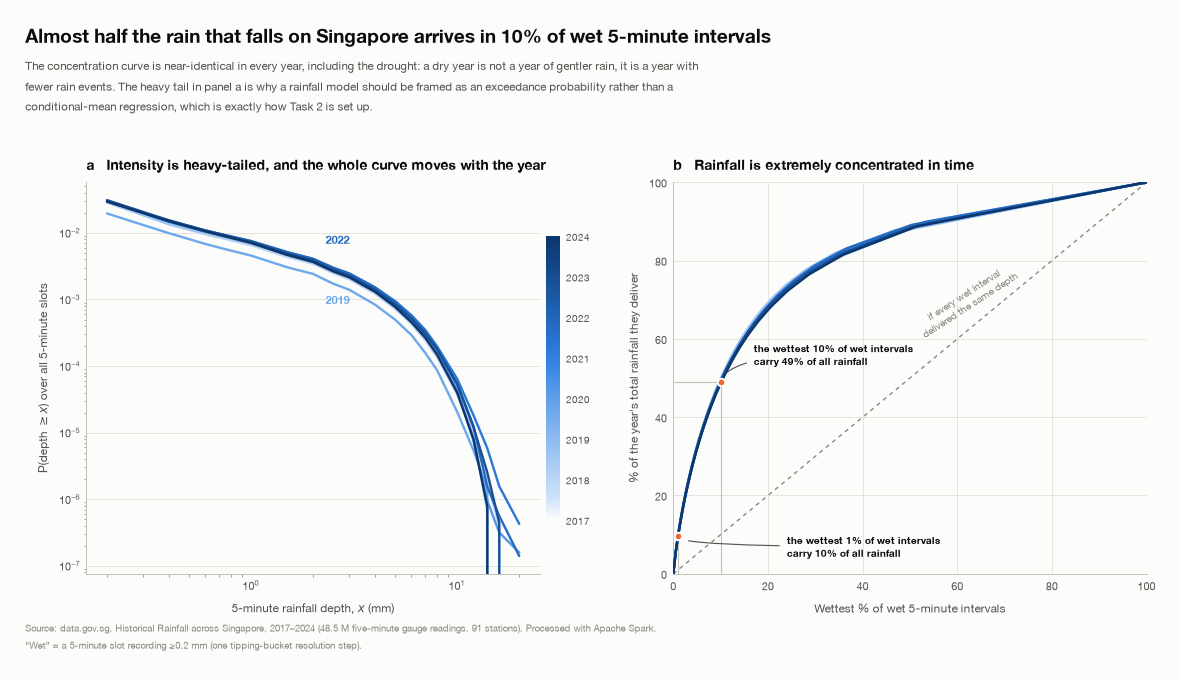

  [figure] outputs/figures/fig06_intensity.png


In [27]:
wet = df.filter(F.col("rain_mm") >= WET_5MIN_MM)
grid = [0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0, 14.0, 16.0, 20.0]
with timed("5.5 intensity + concentration"):
    totals = {r["year"]: r["n"] for r in df.groupBy("year").agg(F.count(F.lit(1)).alias("n")).collect()}
    exc_raw = wet.groupBy("year").agg(*[F.sum((F.col("rain_mm") >= g).cast("long")).alias(f"ge_{i}")
                                        for i, g in enumerate(grid)]).toPandas()
    rows = []
    for _, r in exc_raw.iterrows():
        for i, g in enumerate(grid):
            rows.append({"year": int(r["year"]), "threshold_mm": g, "n_exceed": int(r[f"ge_{i}"]),
                         "n_slots": totals[int(r["year"])], "exceed_prob": r[f"ge_{i}"] / totals[int(r["year"])]})
    write_table(pd.DataFrame(rows), "t12_intensity_exceedance")

    # concentration (a Lorenz curve for rainfall): share of the year's rain in the wettest x % of wet slots
    qs = [i / 200 for i in range(201)]
    lorenz_rows = []
    for yr in sorted(totals):
        vals = np.sort(wet.filter(F.col("year") == yr).select("rain_mm").toPandas()["rain_mm"].to_numpy(float))
        cum = np.cumsum(vals)
        cum = cum / cum[-1]
        idx = (np.array(qs) * (len(vals) - 1)).astype(int)
        lorenz_rows += [{"year": yr, "frac_of_wet_intervals": q, "frac_of_rainfall": float(c)}
                        for q, c in zip(qs, cum[idx])]
    write_table(pd.DataFrame(lorenz_rows), "t13_rain_concentration")

def fig06_intensity() -> None:
    e = T("t12_intensity_exceedance")
    c = T("t13_rain_concentration")
    years = sorted(e["year"].unique())
    ramp = [BLUE_RAMP[i] for i in np.linspace(1, 12, len(years)).astype(int)]

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.3),
                             gridspec_kw=dict(wspace=0.24))

    ax = axes[0]
    for yr, col in zip(years, ramp):
        s = e[e["year"] == yr].sort_values("threshold_mm")
        ax.plot(s["threshold_mm"], s["exceed_prob"], color=col, lw=1.9, zorder=3)
    for yr, dy in [(2019, -0.3), (2022, 0.4)]:
        s = e[e["year"] == yr].sort_values("threshold_mm")
        col = ramp[years.index(yr)]
        ax.annotate(str(yr), xy=(s["threshold_mm"].iloc[6], s["exceed_prob"].iloc[6]),
                    xytext=(10, 12 * (1 if dy > 0 else -2)), textcoords="offset points",
                    fontsize=8.6, color=col, fontweight="semibold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("5-minute rainfall depth, $x$ (mm)")
    ax.set_ylabel("P(depth $\\geq x$) over all 5-minute slots")
    ax.set_title("a   Intensity is heavy-tailed, and the whole curve moves with the year")
    despine(ax)
    ax.grid(which="both", axis="x", visible=False)
    sm = plt.cm.ScalarMappable(cmap=CMAP_RAIN,
                               norm=plt.Normalize(years[0], years[-1]))
    cb = fig.colorbar(sm, ax=ax, pad=0.012, fraction=0.03, ticks=years)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)

    ax = axes[1]
    for yr, col in zip(years, ramp):
        s = c[c["year"] == yr].sort_values("frac_of_wet_intervals")
        ax.plot(100 * (1 - s["frac_of_wet_intervals"]),
                100 * (1 - s["frac_of_rainfall"]), color=col, lw=1.9, zorder=3)
    ax.plot([0, 100], [0, 100], color=MUTED, lw=1.1, ls=(0, (3, 3)), zorder=2)
    ax.text(62, 70, "if every wet interval\ndelivered the same depth", fontsize=8,
            color=MUTED, rotation=33, ha="center", va="center", rotation_mode="anchor")
    s = c[c["year"] == 2022].set_index("frac_of_wet_intervals")["frac_of_rainfall"]
    # the two call-outs are placed by hand: the 1 % point sits on the diagonal
    # reference line, so its label goes into the empty region beneath it
    for q, lab, tx, ty in [(0.99, "1%", 24, 7), (0.90, "10%", 17, 56)]:
        xx, yy = 100 * (1 - q), 100 * (1 - s.loc[q])
        ax.plot([xx, xx], [0, yy], color=AXIS, lw=0.9, zorder=1)
        ax.plot([0, xx], [yy, yy], color=AXIS, lw=0.9, zorder=1)
        ax.plot(xx, yy, "o", color=ORANGE, markersize=6,
                markeredgecolor=SURFACE, markeredgewidth=1.6, zorder=5)
        ax.annotate(f"the wettest {lab} of wet intervals\ncarry {yy:.0f}% of all rainfall",
                    xy=(xx, yy), xytext=(tx, ty), fontsize=8.4, color=INK,
                    fontweight="semibold", ha="left", va="center", zorder=6,
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.9,
                                    connectionstyle="angle3,angleA=0,angleB=75"))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Wettest % of wet 5-minute intervals")
    ax.set_ylabel("% of the year's total rainfall they deliver")
    ax.set_title("b   Rainfall is extremely concentrated in time")
    despine(ax)

    layout(fig, header=1.95, footer=1.00, left=1.1)
    titleblock(fig,
                 "Almost half the rain that falls on Singapore arrives in 10% of wet 5-minute intervals",
                 "The concentration curve is near-identical in every year, including the drought: a dry year is not a year of gentler rain, it is "
                 "a year with\nfewer rain events. The heavy tail in panel a is why a rainfall model should be framed as an exceedance probability "
                 "rather than a\nconditional-mean regression, which is exactly how Task 2 is set up.")
    sourcenote(fig, SRC + "\n“Wet” = a 5-minute slot recording ≥0.2 mm (one tipping-bucket resolution step).")
    save_figure(fig, FIGURES / "fig06_intensity.png")


fig06_intensity()

**Observations.** Five-minute intensity is heavy-tailed, and rain is extremely concentrated in time: **the wettest
10 % of wet 5-minute slots deliver 49 % of a year's rain, and the wettest 1 % deliver 10 %**. The curve is almost
identical every year, the 2019 drought included. A dry year is a year with fewer rain events, not gentler ones. The
heavy tail is also why Task 2 predicts an exceedance probability rather than an expected amount.

### 5.6 Spatial pattern: where it rains more

[5.6 station climatology] 1.0 s
  [table] outputs/tables/t16_station_climatology.csv  (83 rows)
  [table] outputs/tables/t17_station_year_totals.csv  (390 rows)


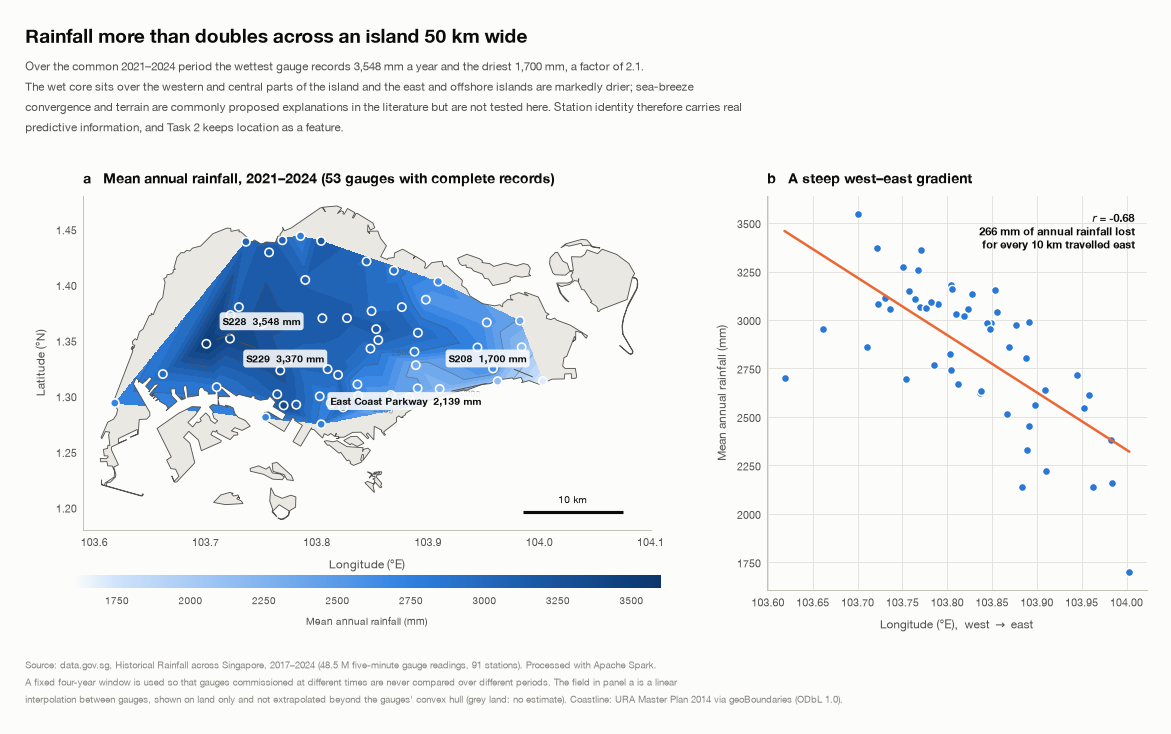

  [figure] outputs/figures/fig07_spatial_climatology.png


In [28]:
with timed("5.6 station climatology"):
    st_year = (station_day.filter(F.col("usable"))
               .groupBy("station_id", "year")
               .agg(F.count(F.lit(1)).alias("days"), F.sum("day_mm").alias("total_mm"),
                    F.avg("day_mm").alias("mean_daily_mm"))
               .filter(F.col("days") >= 300)
               .toPandas())
st_clim = st_year.groupby("station_id").agg(n_years=("year", "size"), mean_daily_mm=("mean_daily_mm", "mean")).reset_index()
st_clim["mean_annual_mm"] = st_clim["mean_daily_mm"] * 365.25
st_clim = st_clim.merge(stations, on="station_id", how="left")
write_table(st_clim.sort_values("mean_annual_mm", ascending=False), "t16_station_climatology")
write_table(st_year, "t17_station_year_totals")

COMMON = [2021, 2022, 2023, 2024]     # a fixed window, so gauges are compared over the same years

# Singapore coastline for the map (reference/SOURCES.md); no analysis depends on it
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath

BOUNDARY_FILE = ROOT / "reference" / "singapore_boundary.geojson"


def load_land(path):
    # Singapore's land polygons (main island and offshore islands) as one matplotlib Path
    verts, codes = [], []
    for f in json.loads(Path(path).read_text())["features"]:
        geom = f["geometry"]
        for poly in (geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]):
            for ring in poly:
                r = np.asarray(ring)[:, :2]
                verts += list(r)
                codes += [MPath.MOVETO] + [MPath.LINETO] * (len(r) - 2) + [MPath.CLOSEPOLY]
    return MPath(verts, codes)


LAND = load_land(BOUNDARY_FILE)
LAND_GREY = "#e9e8e2"
MAP_X, MAP_Y = (103.59, 104.10), (1.18, 1.48)

def common_period_stations() -> pd.DataFrame:
    sy = T("t17_station_year_totals")
    st = T("t02_stations")
    sub = sy[sy["year"].isin(COMMON)]
    ok = sub.groupby("station_id").size()
    ok = ok[ok == len(COMMON)].index
    out = (sub[sub["station_id"].isin(ok)]
           .groupby("station_id")["mean_daily_mm"].mean()
           .mul(365.25).rename("mean_annual_mm").reset_index()
           .merge(st, on="station_id"))
    return out


def fig07_spatial() -> None:
    s = common_period_stations()
    fig = plt.figure(figsize=(13.2, 7.9))
    gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1], wspace=0.22)

    # -- (a) interpolated rainfall surface + gauges ------------------------
    ax = fig.add_subplot(gs[0, 0])
    lon, lat, val = (s["lon"].to_numpy(), s["lat"].to_numpy(),
                     s["mean_annual_mm"].to_numpy())
    tri = mtri.Triangulation(lon, lat)
    interp = mtri.LinearTriInterpolator(tri, val)
    gx, gy = np.meshgrid(np.linspace(*MAP_X, 700), np.linspace(*MAP_Y, 450))
    gz = interp(gx, gy)                       # masked outside the gauges' convex hull: no extrapolation
    ax.add_patch(PathPatch(LAND, fc=LAND_GREY, ec="none", zorder=0.6))
    land_clip = PathPatch(LAND, fc="none", ec="none")
    ax.add_patch(land_clip)
    cf = ax.contourf(gx, gy, gz, levels=np.arange(1600, 3700, 100), cmap=CMAP_RAIN,
                     extend="both", zorder=1)
    cf.set_clip_path(land_clip)               # the field is shown on land only
    cs = ax.contour(gx, gy, gz, levels=np.arange(2000, 3600, 400),
                    colors=[INK_2], linewidths=0.6, alpha=0.45, zorder=2)
    cs.set_clip_path(land_clip)
    ax.clabel(cs, fmt="%.0f", fontsize=7, colors=INK_2)
    ax.add_patch(PathPatch(LAND, fc="none", ec=INK_2, lw=0.7, zorder=3))      # coastline
    sc = ax.scatter(lon, lat, c=val, cmap=CMAP_RAIN, vmin=1600, vmax=3600,
                    s=44, edgecolor=SURFACE, linewidth=1.3, zorder=4)

    # label the extremes, pushing each label away from the plot edge it sits on
    marks = pd.concat([s.nlargest(2, "mean_annual_mm"), s.nsmallest(2, "mean_annual_mm")])
    for k, (_, r) in enumerate(marks.iterrows()):
        east = r["lon"] > np.median(lon)
        dy = 15 if k % 2 == 0 else -19          # stagger so adjacent gauges never overlap
        ax.annotate(f"{r['station_name']}  {r['mean_annual_mm']:,.0f} mm",
                    xy=(r["lon"], r["lat"]),
                    xytext=(-13 if east else 13, dy), textcoords="offset points",
                    ha="right" if east else "left", fontsize=8,
                    color=INK, fontweight="semibold", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.3", fc=SURFACE, ec="none",
                              alpha=0.88),
                    arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.8))
    ax.set_xlim(*MAP_X)
    ax.set_ylim(*MAP_Y)
    km_deg = 10 / (111.320 * np.cos(np.radians(1.35)))      # 10 km in degrees of longitude
    x0, y0 = MAP_X[1] - 0.025 - km_deg, MAP_Y[0] + 0.016       # bottom-right, open sea
    ax.plot([x0, x0 + km_deg], [y0, y0], color=INK, lw=2.5, solid_capstyle="butt", zorder=6)
    ax.text(x0 + km_deg / 2, y0 + 0.006, "10 km", ha="center", va="bottom", fontsize=8, color=INK, zorder=6)
    ax.set_aspect(1 / np.cos(np.radians(1.35)))
    ax.set_xlabel("Longitude (\u00b0E)")
    ax.set_ylabel("Latitude (\u00b0N)")
    ax.set_title(f"a   Mean annual rainfall, {COMMON[0]}\u2013{COMMON[-1]} "
                 f"({len(s)} gauges with complete records)")
    ax.grid(False)
    cb = fig.colorbar(sc, ax=ax, orientation="horizontal", pad=0.115,
                      fraction=0.038, aspect=44)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("Mean annual rainfall (mm)", fontsize=8.2)

    # -- (b) the west-east gradient ---------------------------------------
    ax = fig.add_subplot(gs[0, 1])
    ax.scatter(lon, val, s=42, color=BLUE, edgecolor=SURFACE, linewidth=1.2,
               zorder=3)
    slope, intercept = np.polyfit(lon, val, 1)
    xs = np.linspace(lon.min(), lon.max(), 50)
    ax.plot(xs, intercept + slope * xs, color=ORANGE, lw=2, zorder=4)
    r = np.corrcoef(lon, val)[0, 1]
    km_per_deg = 111.32 * np.cos(np.radians(float(np.mean(lat))))
    per_10km = slope * 10.0 / km_per_deg          # mm per 10 km of easting
    ax.annotate(f"$r$ = {r:.2f}\n{-per_10km:,.0f} mm of annual rainfall lost\n"
                f"for every 10 km travelled east",
                xy=(0.97, 0.96), xycoords="axes fraction", ha="right", va="top",
                fontsize=8.6, color=INK, fontweight="semibold")
    ax.set_xlabel("Longitude (\u00b0E),  west $\\rightarrow$ east")
    ax.set_ylabel("Mean annual rainfall (mm)")
    ax.set_title("b   A steep west\u2013east gradient")
    despine(ax)

    layout(fig, header=2.10, footer=1.42, left=0.95)
    titleblock(fig,
                 "Rainfall more than doubles across an island 50 km wide",
                 f"Over the common {COMMON[0]}\u2013{COMMON[-1]} period the wettest gauge records {val.max():,.0f} mm a year "
                 f"and the driest {val.min():,.0f} mm, a factor of {val.max() / val.min():.1f}.\n"
                 "The wet core sits over the western and central parts of the island and the east and offshore islands are markedly drier; sea-breeze\n"
                 "convergence and terrain are commonly proposed explanations in the literature but are not tested here. Station identity therefore carries "
                 "real\npredictive information, and Task 2 keeps location as a feature.")
    sourcenote(fig, SRC + "\nA fixed four-year window is used so that gauges commissioned at different times are never compared over different periods. "
                            "The field in panel a is a linear\ninterpolation between gauges, shown on land only and not extrapolated beyond the gauges' convex hull (grey land: no estimate). "
                            "Coastline: URA Master Plan 2014 via geoBoundaries (ODbL 1.0).")
    save_figure(fig, FIGURES / "fig07_spatial_climatology.png")


fig07_spatial()

**Observations.** Over the common 2021–24 window (53 gauges with complete records) the wettest gauge averages
**3,548 mm a year and the driest 1,700 mm**, a factor of 2.1 across an island about 50 km wide. Rainfall falls by
about **266 mm per 10 km travelled east** (r = −0.68). Location therefore carries real information, and Task 2 uses
station coordinates as features.

### 5.7 Spatial coherence: how far a storm reaches

Pearson correlation of concurrent 30-minute totals for every pair of gauges with at least four complete years,
computed from a Spark pivot (half-hour × station).

[5.7 spatial coherence] 4.1 s
half-hour x station matrix: (135886, 66)


  [table] outputs/tables/t18_pair_correlation.csv  (2145 rows)


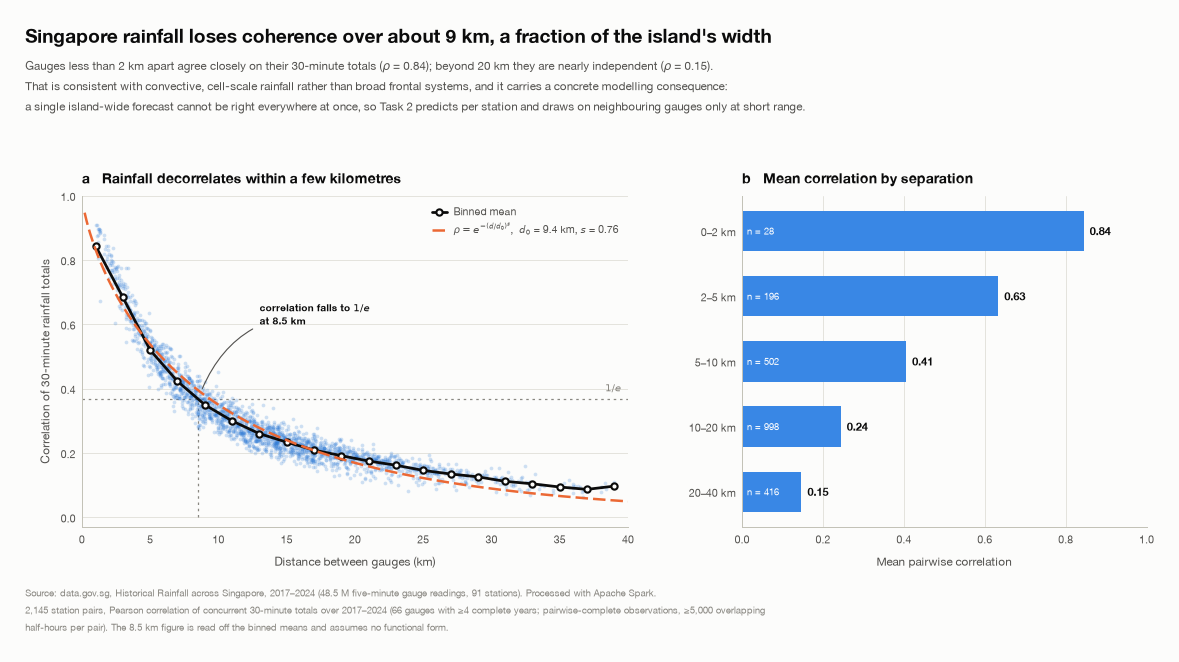

  [figure] outputs/figures/fig08_spatial_coherence.png


In [29]:
hh = (df.withColumn("slot", (F.unix_timestamp("ts") / F.lit(1800)).cast("long"))
      .groupBy("slot", "station_id").agg(F.sum("rain_mm").alias("mm30")))
keep_ids = st_clim[st_clim["n_years"] >= 4]["station_id"].tolist()
with timed("5.7 spatial coherence"):
    wide = (hh.filter(F.col("station_id").isin(keep_ids))
            .groupBy("slot").pivot("station_id", keep_ids).agg(F.first("mm30"))
            .toPandas().set_index("slot").sort_index())
print(f"half-hour x station matrix: {wide.shape}")
corr = wide.corr(min_periods=5000)
st_meta = st_clim.set_index("station_id")
pair_rows = []
ids = list(corr.columns)
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        a, b = ids[i], ids[j]
        dlat = (st_meta.loc[b, "lat"] - st_meta.loc[a, "lat"]) * 110.574          # equirectangular is fine at this scale
        dlon = (st_meta.loc[b, "lon"] - st_meta.loc[a, "lon"]) * 111.320 * np.cos(np.radians(st_meta.loc[a, "lat"]))
        pair_rows.append({"a": a, "b": b, "distance_km": float(np.hypot(dlat, dlon)), "corr": float(corr.loc[a, b])})
write_table(pd.DataFrame(pair_rows).dropna(), "t18_pair_correlation")

def fig08_coherence() -> None:
    p = T("t18_pair_correlation").dropna()
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 7.1),
                             gridspec_kw=dict(width_ratios=[1.35, 1], wspace=0.24))

    bins = np.arange(0, 42, 2)
    p["bin"] = pd.cut(p["distance_km"], bins)
    binned = p.groupby("bin", observed=True)["corr"].mean()
    centres = np.array([iv.mid for iv in binned.index])

    # A plain exponential fits this correlogram badly (it is dominated by the
    # many long-range pairs and sits above the data from 3 to 30 km). A
    # stretched exponential, the standard form for convective rainfall fields,
    # reduces the RMSE against the binned means by a factor of five.
    d, r = p["distance_km"].to_numpy(), p["corr"].to_numpy()
    m = (r > 0.01) & (r < 0.999) & (d > 0)
    shape, c = np.polyfit(np.log(d[m]), np.log(-np.log(r[m])), 1)
    d0 = np.exp(-c / shape)
    # model-free decorrelation distance: where the binned mean crosses 1/e
    d_emp = float(np.interp(np.exp(-1), binned.values[::-1], centres[::-1]))

    ax = axes[0]
    ax.scatter(d, r, s=9, color=BLUE, alpha=0.22, linewidth=0, zorder=2)
    ax.plot(centres, binned.values, color=INK, lw=2.2, marker="o", markersize=5,
            markerfacecolor=SURFACE, markeredgewidth=1.7, zorder=4,
            label="Binned mean")
    xs = np.linspace(0.2, 40, 300)
    ax.plot(xs, np.exp(-(xs / d0) ** shape), color=ORANGE, lw=2, ls=(0, (5, 2)),
            zorder=5,
            label=f"$\\rho = e^{{-(d/d_0)^s}}$,  $d_0$ = {d0:.1f} km, $s$ = {shape:.2f}")
    ax.axhline(np.exp(-1), color=MUTED, lw=1, ls=(0, (2, 3)), zorder=1)
    ax.text(39.5, np.exp(-1) + 0.022, "$1/e$", ha="right", fontsize=8, color=MUTED)
    ax.plot([d_emp, d_emp], [0, np.exp(-1)], color=MUTED, lw=1, ls=(0, (2, 3)),
            zorder=1)
    ax.annotate(f"correlation falls to $1/e$\nat {d_emp:.1f} km",
                xy=(d_emp, np.exp(-1)), xytext=(d_emp + 4.5, 0.60),
                fontsize=8.4, color=INK, fontweight="semibold", zorder=6,
                arrowprops=dict(arrowstyle="-", shrinkA=4, shrinkB=9, color=INK_2, lw=0.9,
                                connectionstyle="angle3,angleA=0,angleB=70"))
    ax.set_xlim(0, 40)
    ax.set_ylim(-0.03, 1.0)
    ax.set_xlabel("Distance between gauges (km)")
    ax.set_ylabel("Correlation of 30-minute rainfall totals")
    ax.set_title("a   Rainfall decorrelates within a few kilometres")
    ax.legend(loc="upper right", fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    rows = []
    for lo, hi in [(0, 2), (2, 5), (5, 10), (10, 20), (20, 40)]:
        sel = p[(p["distance_km"] >= lo) & (p["distance_km"] < hi)]
        rows.append((f"{lo}\u2013{hi} km", sel["corr"].mean(), len(sel)))
    ypos = np.arange(len(rows))
    val = [x[1] for x in rows]
    ax.barh(ypos, val, color=BLUE_RAMP[6], height=0.62, zorder=2)
    for i, (v, n) in enumerate(zip(val, [x[2] for x in rows])):
        ax.text(v + 0.015, i, f"{v:.2f}", va="center", fontsize=8.6,
                color=INK, fontweight="semibold")
        ax.text(0.012, i, f"n = {n:,}", va="center", fontsize=7.6, color="white")
    ax.set_yticks(ypos, [x[0] for x in rows])
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Mean pairwise correlation")
    ax.set_title("b   Mean correlation by separation")
    despine(ax)
    ax.grid(axis="y", visible=False)

    layout(fig, header=2.10, footer=1.32, left=1.05)
    titleblock(fig,
                 f"Singapore rainfall loses coherence over about {d_emp:.0f} km, a fraction of the island's width",
                 "Gauges less than 2 km apart agree closely on their 30-minute totals ($\\rho$ = 0.84); beyond 20 km they are nearly independent "
                 "($\\rho$ = 0.15).\nThat is consistent with convective, cell-scale rainfall rather than broad frontal systems, and it carries a "
                 "concrete modelling consequence:\na single island-wide forecast cannot be right everywhere at once, so Task 2 predicts per station "
                 "and draws on neighbouring gauges only at short range.")
    sourcenote(fig, SRC + f"\n{len(p):,} station pairs, Pearson correlation of concurrent 30-minute totals over 2017\u20132024 "
                            f"(66 gauges with \u22654 complete years; pairwise-complete observations, \u22655,000 overlapping\nhalf-hours per pair). "
                            f"The {d_emp:.1f} km figure is read off the binned means and assumes no functional form.")
    save_figure(fig, FIGURES / "fig08_spatial_coherence.png")


fig08_coherence()

**Observations.** Gauges less than 2 km apart agree closely on 30-minute totals (ρ = 0.84); beyond 20 km they are nearly
independent (ρ = 0.15). **Correlation falls to 1/e at about 8.5 km**, a fraction of the island's width, consistent with
small convective cells rather than broad rain systems. For Task 2 this means a single island-wide forecast cannot be
right everywhere: the model predicts per station and uses neighbouring gauges only within 10 km.

### 5.8 Rain events: duration, depth and start time

An event is a maximal run of wet slots at one gauge with no dry gap longer than 30 minutes (a `lag` window and a
running sum assign event ids).

[5.8 rain events] 2.2 s
  [table] outputs/tables/t19_event_summary_annual.csv  (8 rows)
  [table] outputs/tables/t20_event_sample.csv  (24476 rows)
  [table] outputs/tables/t21_event_by_hour_season.csv  (96 rows)


,year,n_events,stations,mean_depth_mm,median_depth_mm,mean_duration_min,median_duration_min,mean_rate_mm_h,p99_depth_mm,events_per_station
5,2017,23350,58,5.3,0.8,45.0,20.0,5.7,53.8,402.6
7,2018,20963,56,5.4,0.8,44.6,20.0,5.7,57.4,374.3
6,2019,14087,53,5.8,1.0,46.2,20.0,6.1,54.0,265.8
3,2020,29169,80,5.7,0.8,44.4,20.0,5.9,55.4,364.6
2,2021,28223,74,6.9,1.0,49.2,20.0,6.5,71.6,381.4
4,2022,31440,72,6.2,1.0,46.4,20.0,6.1,62.5,436.7
0,2023,30051,73,6.0,0.8,47.8,20.0,6.0,60.2,411.7
1,2024,27762,70,5.9,1.0,46.1,20.0,6.2,58.3,396.6


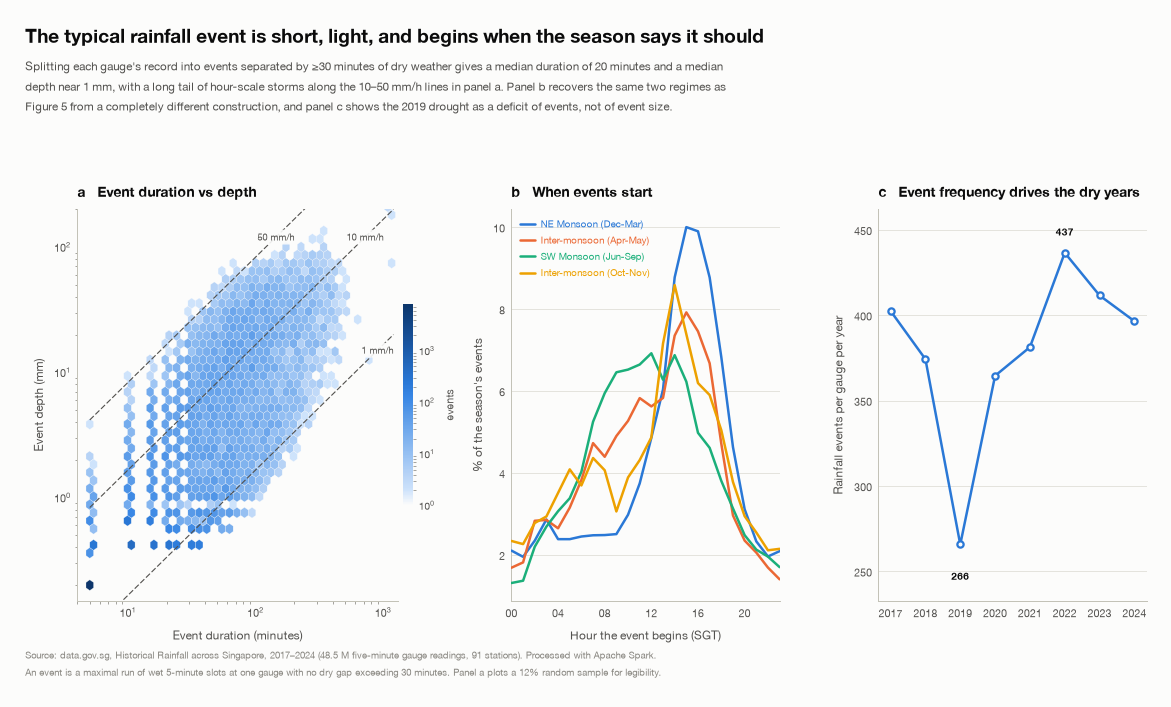

  [figure] outputs/figures/fig09_events.png


In [30]:
wv = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long"))
ev = (df.filter(F.col("rain_mm") >= WET_5MIN_MM).select("station_id", "ts", "year", "season", "rain_mm")
      .withColumn("prev_ts", F.lag("ts").over(wv))
      .withColumn("gap_min", (F.unix_timestamp("ts") - F.unix_timestamp("prev_ts")) / 60)
      .withColumn("new_event", ((F.col("gap_min") > EVENT_GAP_MIN) | F.col("gap_min").isNull()).cast("int"))
      .withColumn("event_id", F.sum("new_event").over(wv.rowsBetween(Window.unboundedPreceding, Window.currentRow))))
events = (ev.groupBy("station_id", "event_id")
          .agg(F.min("ts").alias("start_ts"), F.max("ts").alias("end_ts"), F.sum("rain_mm").alias("depth_mm"),
               F.max("rain_mm").alias("peak_5min_mm"), F.count(F.lit(1)).alias("wet_slots"),
               F.first("year").alias("year"), F.first("season").alias("season"))
          .withColumn("duration_min", (F.unix_timestamp("end_ts") - F.unix_timestamp("start_ts")) / 60 + 5)
          .withColumn("mean_rate_mm_h", F.col("depth_mm") / (F.col("duration_min") / 60))
          .withColumn("start_hour", F.hour("start_ts")))
events.cache()
with timed("5.8 rain events"):
    ev_summary = (events.groupBy("year")
                  .agg(F.count(F.lit(1)).alias("n_events"), F.countDistinct("station_id").alias("stations"),
                       F.avg("depth_mm").alias("mean_depth_mm"),
                       F.expr("percentile_approx(depth_mm, 0.5)").alias("median_depth_mm"),
                       F.avg("duration_min").alias("mean_duration_min"),
                       F.expr("percentile_approx(duration_min, 0.5)").alias("median_duration_min"),
                       F.avg("mean_rate_mm_h").alias("mean_rate_mm_h"),
                       F.expr("percentile_approx(depth_mm, 0.99)").alias("p99_depth_mm"))
                  .toPandas().sort_values("year"))
    ev_summary["events_per_station"] = ev_summary["n_events"] / ev_summary["stations"]
    ev_sample = (events.select("duration_min", "depth_mm", "peak_5min_mm", "season", "start_hour", "year")
                 .sample(False, 0.12, seed=5208).toPandas())
    ev_hour = (events.groupBy("season", "start_hour")
               .agg(F.count(F.lit(1)).alias("n_events"), F.avg("depth_mm").alias("mean_depth_mm"),
                    F.avg("duration_min").alias("mean_duration_min"))
               .toPandas())
write_table(ev_summary, "t19_event_summary_annual")
write_table(ev_sample, "t20_event_sample")
write_table(ev_hour, "t21_event_by_hour_season")
display(ev_summary.round(1))

def fig09_events() -> None:
    ev = T("t20_event_sample")
    eh = T("t21_event_by_hour_season")
    ea = T("t19_event_summary_annual")

    fig = plt.figure(figsize=(13.2, 7.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.25, 1, 1], wspace=0.34)

    ax = fig.add_subplot(gs[0, 0])
    hb = ax.hexbin(ev["duration_min"], ev["depth_mm"], gridsize=42, bins="log",
                   xscale="log", yscale="log", cmap=CMAP_RAIN, mincnt=1,
                   linewidths=0.2, edgecolors=SURFACE)
    xs = np.array([5, 1200])
    for rate in (1, 10, 50):
        ax.plot(xs, rate * xs / 60, color=INK_2, lw=0.9, ls=(0, (5, 2)), zorder=4)
        # anchor each label where its line is still inside the visible box
        x_lab = min(900.0, 120.0 * 60.0 / rate)
        ax.text(x_lab, rate * x_lab / 60, f"{rate} mm/h", fontsize=7.4,
                color=INK_2, va="center", ha="center", zorder=5, rotation=0,
                bbox=dict(boxstyle="round,pad=0.22", fc=SURFACE, ec="none", alpha=0.9))
    ax.set_xlim(4, 1300)
    ax.set_ylim(0.15, 200)
    ax.set_xlabel("Event duration (minutes)")
    ax.set_ylabel("Event depth (mm)")
    ax.set_title("a   Event duration vs depth")
    despine(ax)
    ax.grid(which="both", visible=False)
    cb = fig.colorbar(hb, ax=ax, pad=0.014, fraction=0.03)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    cb.set_label("events", fontsize=8.2)

    ax = fig.add_subplot(gs[0, 1])
    for name in SEASON_ORDER:
        s = eh[eh["season"] == name].sort_values("start_hour")
        share = 100 * s["n_events"] / s["n_events"].sum()
        ax.plot(s["start_hour"], share, color=SEASON_COLOR[name], zorder=3,
                label=name.split(" (")[0] + name[name.find(" ("):])
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 4), [f"{h:02d}" for h in range(0, 24, 4)])
    ax.set_xlabel("Hour the event begins (SGT)")
    ax.set_ylabel("% of the season's events")
    ax.set_title("b   When events start")
    ax.legend(loc="upper left", fontsize=7.8, ncol=1, labelcolor="linecolor")
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = fig.add_subplot(gs[0, 2])
    ax.plot(ea["year"], ea["events_per_station"], color=BLUE, marker="o",
            markersize=5, markerfacecolor=SURFACE, markeredgewidth=1.8, zorder=3)
    for _, r in ea.iterrows():
        if r["year"] in (2019, 2022):
            high = r["year"] == 2022
            ax.annotate(f"{r['events_per_station']:.0f}",
                        (r["year"], r["events_per_station"]),
                        textcoords="offset points",
                        xytext=(0, 12 if high else -20), ha="center",
                        va="bottom" if high else "top",
                        fontsize=8.4, color=INK, fontweight="semibold")
    ax.set_ylabel("Rainfall events per gauge per year")
    ax.set_xticks(ea["year"])
    ax.set_title("c   Event frequency drives the dry years")
    despine(ax)
    ax.grid(axis="x", visible=False)
    pad_ylim(ax)

    med_d = ea["median_duration_min"].median()
    layout(fig, header=2.25, footer=1.00, left=1.0)
    titleblock(fig,
                 "The typical rainfall event is short, light, and begins when the season says it should",
                 f"Splitting each gauge's record into events separated by ≥30 minutes of dry weather gives a median duration of "
                 f"{med_d:.0f} minutes and a median\ndepth near 1 mm, with a long tail of hour-scale storms along the 10–50 mm/h lines in panel a. "
                 "Panel b recovers the same two regimes as\nFigure 5 from a completely different construction, and panel c shows the 2019 drought as a "
                 "deficit of events, not of event size.")
    sourcenote(fig, SRC + "\nAn event is a maximal run of wet 5-minute slots at one gauge with no dry gap exceeding 30 minutes. Panel a plots a 12% random sample for legibility.")
    save_figure(fig, FIGURES / "fig09_events.png")


fig09_events()

**Observations.** The typical event is short and light (median 20 minutes, about 1 mm), with a long tail of hour-scale
storms. Event start times recover the same two diurnal regimes as Figure 5 from an independent construction, and the
2019 drought is a deficit of events (266 per gauge against about 400 in other years), not of event size.

### 5.9 Extremes, heavy half-hours and the Task 2 base rate

* **Trailing** 30- and 60-minute accumulations per gauge give annual maxima and how often 30-minute totals cross
  5, 10 and 20 mm, on all gauges and on the fixed network.
* The **forward** 30-minute window (Section 4.3) gives the quantity Task 2 predicts, P(next 30 min > h), as a base
  rate by hour and season.

In [31]:
w30 = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long")).rangeBetween(-1500, 0)   # 6 slots
w60 = Window.partitionBy("station_id").orderBy(F.col("ts").cast("long")).rangeBetween(-3300, 0)   # 12 slots
roll = (df.select("station_id", "ts", "year", "rain_mm", "season")
        .withColumn("acc30", F.sum("rain_mm").over(w30))
        .withColumn("acc60", F.sum("rain_mm").over(w60)))
roll.cache()
with timed("5.9 extremes + base rates"):
    extremes = (roll.groupBy("year")
                .agg(F.max("acc30").alias("max_30min_mm"), F.max("acc60").alias("max_60min_mm"),
                     F.sum((F.col("acc30") >= 5).cast("long")).alias("n_acc30_ge5"),
                     F.sum((F.col("acc30") >= 10).cast("long")).alias("n_acc30_ge10"),
                     F.sum((F.col("acc30") >= 20).cast("long")).alias("n_acc30_ge20"),
                     F.count(F.lit(1)).alias("n_slots"),
                     F.expr("percentile_approx(acc30, 0.9999, 1000000)").alias("p9999_30min_mm"))
                .toPandas().sort_values("year"))
    extremes_fixed = (roll.filter(F.col("station_id").isin(cohort)).groupBy("year")
                      .agg(F.sum((F.col("acc30") >= 5).cast("long")).alias("n_acc30_ge5_fixed"),
                           F.sum((F.col("acc30") >= 10).cast("long")).alias("n_acc30_ge10_fixed"),
                           F.sum((F.col("acc30") >= 20).cast("long")).alias("n_acc30_ge20_fixed"),
                           F.count(F.lit(1)).alias("n_slots_fixed"))
                      .toPandas())
    extremes = extremes.merge(extremes_fixed, on="year", how="left")
    for c in ["n_acc30_ge5", "n_acc30_ge10", "n_acc30_ge20"]:
        extremes[c.replace("n_", "rate_")] = extremes[c] / extremes["n_slots"]
        extremes[c.replace("n_", "rate_") + "_fixed"] = extremes[c + "_fixed"] / extremes["n_slots_fixed"]
    write_table(extremes, "t14_extremes_annual")

    # forward window: P(rain in the NEXT 30 min > h) by hour of the prediction time and season (strict ">")
    fwd = add_time_features(add_future_target(df.select("station_id", "ts", "rain_mm")))
    fwd = fwd.filter(F.col("future_30min_mm").isNotNull())
    base_rates = (fwd.groupBy("season", "hour")
                  .agg(*[F.avg((F.col("future_30min_mm") > h).cast("double")).alias(name)
                         for name, h in [("p_gt_0p2", 0.2), ("p_gt_1", 1.0), ("p_gt_5", 5.0),
                                         ("p_gt_10", 10.0), ("p_gt_20", 20.0)]],
                       F.count(F.lit(1)).alias("n"))
                  .toPandas())
write_table(base_rates, "t15_base_rates_30min")
extremes[["year", "max_30min_mm", "max_60min_mm", "rate_acc30_ge5", "rate_acc30_ge5_fixed"]].round(5)

  [table] outputs/tables/t14_extremes_annual.csv  (8 rows)


[5.9 extremes + base rates] 22.0 s
  [table] outputs/tables/t15_base_rates_30min.csv  (96 rows)


,year,max_30min_mm,max_60min_mm,rate_acc30_ge5,rate_acc30_ge5_fixed
0,2017,71.60001,92.00000,0.00783,0.00791
1,2018,71.80000,102.39999,0.00829,0.00815
2,2019,63.80000,90.20000,0.00560,0.00558
3,2020,67.80000,107.00000,0.00872,0.00857
4,2021,67.60000,98.59999,0.00911,0.00895
5,2022,65.93400,101.79600,0.00927,0.00877
6,2023,70.23800,100.89100,0.00895,0.00865
7,2024,65.00000,103.01999,0.00853,0.00820


### 5.10 Trend tests

With eight annual values, visual "trends" are easy to over-read. Each annual series gets a **Mann–Kendall** test
(an exact two-sided p-value from all 8! = 40,320 orderings) and **Sen's slope** (median of pairwise slopes).

In [32]:
ext, evs, yr = extremes.set_index("year"), ev_summary.set_index("year"), annual.set_index("year")
series = {
    "annual rainfall, gap-filled (mm)": yr["gapfilled_total_mm"],
    "wet days per year (>= 1 mm, scaled)": yr["wet_days_scaled"],
    "intensity (mm per wet day)": yr["gapfilled_total_mm"] / yr["wet_days_scaled"],
    "rain events per gauge": evs["events_per_station"],
    "30-min totals >= 5 mm, rate (all gauges)": ext["rate_acc30_ge5"],
    "30-min totals >= 5 mm, rate (fixed network)": ext["rate_acc30_ge5_fixed"],
    "annual max 30-min depth (mm, any gauge)": ext["max_30min_mm"],
    "annual max 60-min depth (mm, any gauge)": ext["max_60min_mm"],
}
trend_rows = []
for name, s in series.items():
    s = s.sort_index()
    r = mann_kendall(s.index, s.to_numpy())
    r["sen_slope_pct_of_mean_per_year"] = 100 * r["sen_slope_per_year"] / s.mean()
    trend_rows.append({"metric": name, "n_years": len(s), **r})
trends = write_table(pd.DataFrame(trend_rows), "t39_trend_tests")
trends.round(4)

  [table] outputs/tables/t39_trend_tests.csv  (8 rows)


,metric,n_years,kendall_tau,p_value_exact,sen_slope_per_year,sen_slope_pct_of_mean_per_year
0,"annual rainfall, gap-filled (mm)",8,0.3571,0.2751,59.0867,2.2609
1,"wet days per year (>= 1 mm, scaled)",8,-0.0714,0.9049,-0.6452,-0.2865
2,intensity (mm per wet day),8,0.5714,0.0610,0.3171,2.7344
3,rain events per gauge,8,0.2857,0.3988,5.9427,1.5672
4,"30-min totals >= 5 mm, rate (all gauges)",8,0.4286,0.1789,0.0002,2.4295
5,"30-min totals >= 5 mm, rate (fixed network)",8,0.3571,0.2751,0.0001,1.3942
6,"annual max 30-min depth (mm, any gauge)",8,-0.3571,0.2751,-0.7833,-1.1524
7,"annual max 60-min depth (mm, any gauge)",8,0.2857,0.3988,1.4776,1.4852


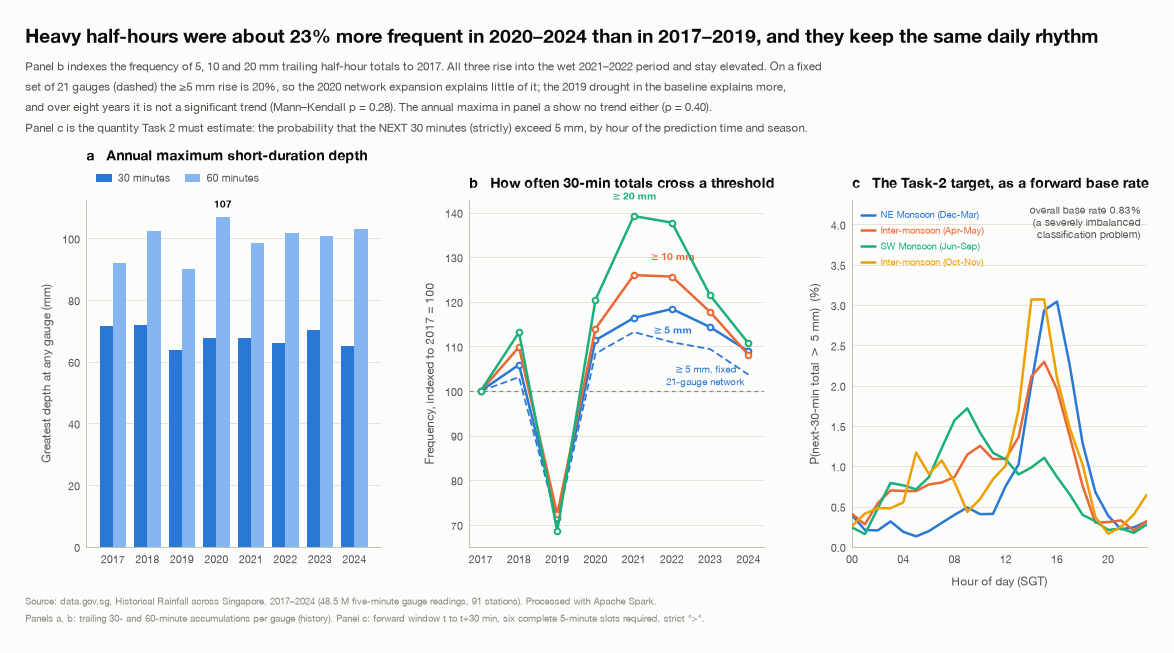

  [figure] outputs/figures/fig10_extremes.png


Task 1 figures collected in outputs/figures/task1_all_figures.pdf


In [33]:
def fig10_extremes() -> None:
    x = T("t14_extremes_annual").sort_values("year")
    b = T("t15_base_rates_30min")
    tr = T("t39_trend_tests").set_index("metric")
    n_fixed = int(T("t24_sensitivity_summary").set_index("metric")["value"]["fixed_network_stations"])

    def gain(col):
        r = x.set_index("year")[col]
        return 100 * (r.loc[2020:2024].mean() / r.loc[2017:2019].mean() - 1)

    heavy_gain, heavy_gain_fixed = gain("rate_acc30_ge5"), gain("rate_acc30_ge5_fixed")
    p_fixed = tr.loc["30-min totals >= 5 mm, rate (fixed network)", "p_value_exact"]
    p_max60 = tr.loc["annual max 60-min depth (mm, any gauge)", "p_value_exact"]

    fig, axes = plt.subplots(1, 3, figsize=(13.2, 7.0),
                             gridspec_kw=dict(wspace=0.3))

    ax = axes[0]
    w = 0.38
    idx = np.arange(len(x))
    ax.bar(idx - w / 2, x["max_30min_mm"], width=w, color=BLUE, zorder=3,
           label="30 minutes")
    ax.bar(idx + w / 2, x["max_60min_mm"], width=w, color=BLUE_RAMP[3], zorder=3,
           label="60 minutes")
    top60 = x["max_60min_mm"].idxmax()
    for i, r in enumerate(x.itertuples()):
        if r.Index == top60:
            ax.text(i + w / 2, r.max_60min_mm + 3, f"{r.max_60min_mm:.0f}",
                    ha="center", fontsize=8.4, color=INK, fontweight="semibold")
    ax.set_xticks(idx, x["year"])
    ax.set_ylabel("Greatest depth at any gauge (mm)")
    ax.set_title("a   Annual maximum short-duration depth", pad=32)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02), ncol=2, fontsize=8.4)
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[1]
    # each series is labelled at its own year and on its own side, so no label
    # ever lands on a neighbouring line
    label_at = {"rate_acc30_ge5": (5, -12, "top"),
                "rate_acc30_ge10": (5, 11, "bottom"),
                "rate_acc30_ge20": (4, 11, "bottom")}
    for col, lab, colr in [("rate_acc30_ge5", "$\\geq$5 mm", BLUE),
                           ("rate_acc30_ge10", "$\\geq$10 mm", ORANGE),
                           ("rate_acc30_ge20", "$\\geq$20 mm", AQUA)]:
        v = 100 * x[col] / x[col].iloc[0]
        ax.plot(x["year"], v, color=colr, marker="o", markersize=4.5,
                markerfacecolor=SURFACE, markeredgewidth=1.6, zorder=3)
        # label at 2021, where the three series are furthest apart, rather than
        # at the right edge where they converge
        idx, dy, va = label_at[col]
        ax.annotate(lab, (x["year"].iloc[idx], v.iloc[idx]), xytext=(0, dy),
                    textcoords="offset points", fontsize=8.4, color=colr,
                    fontweight="semibold", va=va, ha="center")
    # the same >= 5 mm series on the fixed network, to separate weather from
    # the 2020 network expansion
    vf = 100 * x["rate_acc30_ge5_fixed"] / x["rate_acc30_ge5_fixed"].iloc[0]
    ax.plot(x["year"], vf, color=BLUE, lw=1.4, ls=(0, (4, 2)), zorder=2)
    # labelled under the line at 2023, the only stretch with no series below it
    ax.annotate(f"$\\geq$5 mm, fixed\n{n_fixed}-gauge network", (x["year"].iloc[6], vf.iloc[6]),
                xytext=(-4, -12), textcoords="offset points", fontsize=7.8, color=BLUE,
                va="top", ha="center")
    ax.axhline(100, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.set_xticks(x["year"])
    ax.set_xlim(2016.7, 2024.4)
    ax.set_ylabel("Frequency, indexed to 2017 = 100")
    ax.set_title("b   How often 30-min totals cross a threshold")
    despine(ax)
    ax.grid(axis="x", visible=False)

    ax = axes[2]
    for name in SEASON_ORDER:
        s = b[b["season"] == name].sort_values("hour")
        ax.plot(s["hour"], 100 * s["p_gt_5"], color=SEASON_COLOR[name], zorder=3,
                label=name)
    ax.set_xlim(0, 23)
    ax.set_xticks(range(0, 24, 4), [f"{h:02d}" for h in range(0, 24, 4)])
    ax.set_xlabel("Hour of day (SGT)")
    ax.set_ylabel("P(next-30-min total $>$ 5 mm)  (%)")
    ax.set_title("c   The Task-2 target, as a forward base rate")
    ax.set_ylim(0, 4.3)
    ax.legend(loc="upper left", fontsize=7.6, labelcolor="linecolor")
    despine(ax)
    ax.grid(axis="x", visible=False)
    ax.annotate(f"overall base rate {100 * np.average(b['p_gt_5'], weights=b['n']):.2f}%\n(a severely imbalanced\nclassification problem)",
                xy=(0.98, 0.99), xycoords="axes fraction", ha="right", va="top",
                fontsize=8.2, color=INK_2)

    layout(fig, header=2.15, footer=1.00, left=1.1)
    titleblock(fig,
                 f"Heavy half-hours were about {heavy_gain:.0f}% more frequent in 2020\u20132024 than in 2017\u20132019, and they keep the same daily rhythm",
                 "Panel b indexes the frequency of 5, 10 and 20 mm trailing half-hour totals to 2017. All three rise into the wet 2021\u20132022 period and stay elevated. "
                 f"On a fixed\nset of {n_fixed} gauges (dashed) the \u22655 mm rise is {heavy_gain_fixed:.0f}%, so the 2020 network expansion explains little of it; the 2019 "
                 f"drought in the baseline explains more,\nand over eight years it is not a significant trend (Mann\u2013Kendall p = {p_fixed:.2f}). "
                 f"The annual maxima in panel a show no trend either (p = {p_max60:.2f}).\nPanel c is the quantity Task 2 must estimate: the probability that the NEXT 30 minutes (strictly) exceed 5 mm, by hour of the "
                 "prediction time and season.")
    sourcenote(fig, SRC + "\nPanels a, b: trailing 30- and 60-minute accumulations per gauge (history). Panel c: forward window t to t+30 min, six complete 5-minute slots required, strict \">\".")
    save_figure(fig, FIGURES / "fig10_extremes.png")


fig10_extremes()
close_pdf()
print("Task 1 figures collected in outputs/figures/task1_all_figures.pdf")

**Observations.**
* Heavy half-hours were **about 23 % more frequent in 2020–24 than in 2017–19 (20 % on the fixed network)**, so the 2020
  network expansion explains little of the rise; the 2019 drought in the low baseline explains more.
* **No annual series has a statistically significant trend over 2017–2024.** Rain per wet day comes closest
  (τ = 0.57, p = 0.06, +0.32 mm per wet day per year). The heavy-half-hour rate (p = 0.28) and the annual maxima
  (p = 0.40) show no significant trend. With eight points the test has little power, so "not significant" means
  "not shown", not "no change".
* The forward base rate P(next 30 min > 5 mm) is **0.83 %** overall but varies more than tenfold with hour and season:
  Task 2 is a heavily imbalanced problem with strong structure.

### 5.11 Task 1 summary and what it means for Task 2

| Finding | Evidence | Consequence for Task 2 |
|---|---|---|
| Large year-to-year variability; 2019 dry through fewer events | Figs 2, 4, 9 | recent rainfall state, not only the calendar |
| Two diurnal regimes switched by the monsoon | Figs 5, 9 | hour of day **and** day of year as features |
| Heavy-tailed, concentrated intensity | Fig 6 | predict an **exceedance probability**, not an amount |
| 2.1× west–east gradient | Fig 7 | station location as a feature |
| Correlation falls to 1/e at ~8.5 km | Fig 8 | per-station model; neighbours within 10 km only |
| Base rate 0.83 % at 5 mm, tenfold structure | Fig 10c | imbalance-aware evaluation (PR-AUC, log loss, calibration) |

In [34]:
spark.catalog.clearCache()     # free executor memory before Task 2

---
# Part C — Task 2: probability of more than *h* mm of rain in the next 30 minutes

## 6. Problem definition

**Inputs:** a station *s*, a prediction time *t* and a rainfall threshold *h* (mm).
**Output:** P( rain at *s* during [*t*, *t* + 30 min) > *h* ).

* **Target.** With the convention from Section 4.3, the latest reading available at *t* is stamped `ts = t − 5 min`,
  and the next 30 minutes are the six slots stamped `ts`+5 … `ts`+30 min. Their sum is `future_30min_mm`; it exists
  only if all six slots exist, and the label is `future_30min_mm > h` (strictly more than).
* **One model for every threshold.** The threshold is an **input feature** of a single binary classifier. Each
  training example (station, time) is paired with several thresholds, each with its own label, so the model learns
  how the probability falls as *h* rises and can answer for any *h* in 0.2–30 mm.
* **What the model may use.** Only information available at *t*: the station's coordinates, the clock, and rain
  stamped at or before `ts` at the station and at up to four neighbouring gauges within 10 km. Nothing is learned
  from rain after *t* or from outside the training years.
* **Chronological split.** Train 2017–2022, validate (model selection) on 2023, test once on 2024. A random split
  would leak: neighbouring 5-minute examples share five of their six future slots. Examples whose 30-minute window
  crosses a split boundary are dropped.

**How performance is measured.** The event is rare (0.83 % of half-hours exceed 5 mm), so accuracy is meaningless
(always predicting "no" scores 99 %). Instead:

| Metric | Question it answers | Good |
|---|---|---|
| PR-AUC (average precision) | when the model flags rain, how often is it right, across all cut-offs? Compare with the event rate. | high |
| ROC-AUC | how well does it rank wet half-hours above dry ones? | high |
| Brier score | mean squared error of the probability | low |
| Log loss | penalty for confident wrong probabilities (a proper scoring rule) | low |
| Skill vs climatology | 1 − score(model) / score(baseline): the share of the baseline's error removed | high |
| Reliability | do events forecast at 20 % happen 20 % of the time? | on the diagonal |
| Monotonicity | P(> 10 mm) must never exceed P(> 5 mm) | 0 violations |

In [35]:
# definitions
TRAIN_END = "2023-01-01 00:00:00"


VAL_END = "2024-01-01 00:00:00"


NBR_K = 4


NBR_MAX_KM = 10.0


def split_col(pred_time_col="pred_time"):
    """train / validation / test, purged so no label window crosses a boundary."""
    t = F.col(pred_time_col)
    end = t + F.expr("INTERVAL 30 MINUTES")
    return (F.when(end <= F.to_timestamp(F.lit(TRAIN_END)), "train")
             .when((t >= F.to_timestamp(F.lit(TRAIN_END))) & (end <= F.to_timestamp(F.lit(VAL_END))), "validation")
             .when(t >= F.to_timestamp(F.lit(VAL_END)), "test"))

## 7. Feature engineering (pre-processing for the model)

One row per (station, prediction time) over all 48 M readings, built with Spark window functions:

| Group | Features | Why (Task 1 evidence) |
|---|---|---|
| Location | `lat`, `lon` | 2.1× west–east gradient (Fig 7) |
| Calendar | sin/cos of time of day, sin/cos of day of year, season | two diurnal regimes, monsoon seasons (Fig 5) |
| Recent rain at the station | latest 5-min rain; last 15/30/60/180-min totals; 60-min peak and wet-slot count; wet flag | events last ~20 min; persistence (Figs 4, 9) |
| Neighbouring gauges (≤ 4 within 10 km) | mean and max of their last 30 min, mean of their last 60 min, max of their latest 5 min, availability flag | correlation length ~8.5 km (Fig 8) |
| Threshold | log(1 + *h*), and *h* × recent-rain interactions (logistic model only) | the task's own input |

**Neighbours without a cross join.** The neighbour map is a small static table from coordinates only (no rainfall,
so no leakage). It is broadcast and joined to the readings, then grouped by (target station, slot), so the 48 M-row
table is never joined station-by-station. A missing neighbour is encoded as 0 with an explicit flag, never as a
fake "dry neighbour".

Rows are kept only if the full 3-hour history and all six future slots exist.

In [36]:
# definitions
def neighbour_map(stations_pdf, k: int = NBR_K, max_km: float = NBR_MAX_KM):
    """Static nearest-K neighbour map (station_id, nbr_id, dist_km).

    Uses only station coordinates, never rainfall, so it carries no target
    information. Equirectangular distance is accurate to <0.1% at this scale.
    """
    ids = stations_pdf["station_id"].tolist()
    lat = stations_pdf["lat"].to_numpy(float)
    lon = stations_pdf["lon"].to_numpy(float)
    rows = []
    for i, s in enumerate(ids):
        dy = (lat - lat[i]) * 110.574
        dx = (lon - lon[i]) * 111.320 * np.cos(np.radians(lat[i]))
        d = np.hypot(dx, dy)
        order = [j for j in np.argsort(d) if j != i and d[j] <= max_km][:k]
        rows += [(s, ids[j], float(d[j])) for j in order]
    return rows


def add_neighbour_features(spark, feats, lookup, nbr_rows):
    """Neighbour summaries at the same anchor slot.

    `lookup` = (station_id, ts, r5, acc30, acc60) for the neighbours' own
    trailing windows (already restricted to <= ts, so no future leakage).
    Strategy: join the lookup table to the small reversed edge map (broadcast,
    no shuffle), then group by (target station, ts). The 48 M-row table is
    never cross-joined station-by-station.
    """
    edges = spark.createDataFrame(nbr_rows, ["station_id", "nbr_id", "dist_km"])
    rev = edges.select(F.col("nbr_id").alias("station_id"),
                       F.col("station_id").alias("target_id"))
    agg = (lookup.join(F.broadcast(rev), "station_id")
           .groupBy("target_id", "ts")
           .agg(F.avg("acc30").alias("nbr_acc30_mean"),
                F.max("acc30").alias("nbr_acc30_max"),
                F.avg("acc60").alias("nbr_acc60_mean"),
                F.max("r5").alias("nbr_r5_max"),
                F.count("acc30").alias("n_nbr"))
           .withColumnRenamed("target_id", "station_id"))
    out = feats.join(agg, ["station_id", "ts"], "left")
    out = out.withColumn("n_nbr", F.coalesce(F.col("n_nbr"), F.lit(0)))
    # no neighbour reporting -> neighbour signal is *absent*, encoded as 0 with
    # an explicit n_nbr == 0 indicator, never as a fake "dry neighbours" fact
    for c in ["nbr_acc30_mean", "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max"]:
        out = out.withColumn(c, F.coalesce(F.col(c), F.lit(0.0)))
    return out.withColumn("has_nbr", (F.col("n_nbr") > 0).cast("double"))

In [37]:
FEATURES_PATH = GOLD / "task2_features"
nbr = neighbour_map(stations)
print(f"neighbour map: {len(nbr)} edges for {len(stations)} stations (mean {len(nbr) / len(stations):.2f} per station)")

t2 = (spark.read.parquet(str(SILVER / "readings")).select("station_id", "ts", "rain_mm")
      .withColumn("ts_s", F.col("ts").cast("long")))
t2 = add_future_target(add_trailing_features(t2))
t2 = t2.join(F.broadcast(spark.createDataFrame(stations[["station_id", "lat", "lon"]])), "station_id")
t2.cache()
with timed("7a. feature table (windows, neighbours, calendar, split)"):
    n_all = t2.count()
    n_fut = t2.filter(F.col("future_30min_mm").isNotNull()).count()
    ok = t2.filter(F.col("future_30min_mm").isNotNull() & F.col("acc180").isNotNull())
    n_ok = ok.count()
    # neighbour lookup: every row whose own trailing windows are complete to 1 h (all values are <= ts)
    lookup = t2.filter(F.col("acc60").isNotNull()).select("station_id", "ts", "r5", "acc30", "acc60")
    feats = add_neighbour_features(spark, ok, lookup, nbr)
    feats = add_time_features(feats).withColumn("split", split_col())
    feats = feats.filter(F.col("split").isNotNull())
    cols = (["station_id", "ts", "pred_time", "split", "lat", "lon", "season", "hour", "minute_of_day",
             "tod_sin", "tod_cos", "month", "doy_sin", "doy_cos"] + TRAILING_COLS
            + ["nbr_acc30_mean", "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max", "n_nbr", "has_nbr",
               "future_30min_mm"])
    feats.select(*cols).repartition("split").write.mode("overwrite").partitionBy("split").parquet(str(FEATURES_PATH))
t2.unpersist()
print(f"readings {n_all:,}; with all six future slots {n_fut:,}; with complete 3 h history and future {n_ok:,}")

neighbour map: 361 edges for 91 stations (mean 3.97 per station)


[7a. feature table (windows, neighbours, calendar, split)] 97.2 s
readings 48,338,938; with all six future slots 47,448,263; with complete 3 h history and future 45,856,886


In [38]:
feats = spark.read.parquet(str(FEATURES_PATH))
feats.cache()
with timed("7b. feature table audit"):
    row_audit = (feats.groupBy("split")
                 .agg(F.count(F.lit(1)).alias("rows"), F.countDistinct("station_id").alias("stations"),
                      F.min("pred_time").alias("first_pred_time"), F.max("pred_time").alias("last_pred_time"),
                      F.avg("has_nbr").alias("frac_with_neighbour"),
                      *[F.avg((F.col("future_30min_mm") > h).cast("double")).alias(f"pos_rate_gt_{h}")
                        for h in (0.2, 1.0, 5.0, 10.0, 20.0)],
                      *[F.sum((F.col("future_30min_mm") > h).cast("long")).alias(f"n_pos_gt_{h}")
                        for h in (0.2, 1.0, 5.0, 10.0, 20.0)])
                 .toPandas().sort_values("split"))
    row_audit["rows_all_raw"] = n_all
    row_audit["rows_incomplete_future"] = n_all - n_fut
    row_audit["rows_incomplete_history_or_future"] = n_all - n_ok
    q = feats.approxQuantile("future_30min_mm", [0.5, 0.9, 0.99, 0.999, 0.9999], 1e-5)
write_table(row_audit, "t25_task2_row_audit")
write_table(pd.DataFrame({"quantile": [0.5, 0.9, 0.99, 0.999, 0.9999], "future_30min_mm": q}), "t26_future30_quantiles")
display(row_audit.set_index("split").T)
print("an example of rows during rain:")
feats.filter((F.col("split") == "train") & (F.col("acc30") > 2)).select(
    "station_id", "pred_time", "r5", "acc30", "acc180", "nbr_acc30_mean", "nbr_acc30_max", "n_nbr",
    "tod_sin", "tod_cos", "future_30min_mm").limit(5).toPandas()

[7b. feature table audit] 16.8 s
  [table] outputs/tables/t25_task2_row_audit.csv  (3 rows)
  [table] outputs/tables/t26_future30_quantiles.csv  (5 rows)


split,test,train,validation
rows,6277148,32962257,6616826
stations,70,87,73
first_pred_time,2024-01-01 00:00:00,2017-01-01 11:05:00,2023-01-01 00:00:00
last_pred_time,2024-12-31 23:30:00,2022-12-31 23:30:00,2023-12-31 23:30:00
frac_with_neighbour,0.99634,0.964877,0.997497
pos_rate_gt_0.2,0.048633,0.044268,0.05075
pos_rate_gt_1.0,0.025695,0.023489,0.026321
pos_rate_gt_5.0,0.008365,0.008201,0.008753
pos_rate_gt_10.0,0.003823,0.003928,0.004132
pos_rate_gt_20.0,0.00103,0.001096,0.001113


an example of rows during rain:


,station_id,pred_time,r5,acc30,acc180,nbr_acc30_mean,nbr_acc30_max,n_nbr,tod_sin,tod_cos,future_30min_mm
0,S06,2017-01-02 16:30:00,1.000,10.800,10.800,1.80000,3.600,2,-0.923880,-0.382683,2.800
1,S226,2020-07-23 03:55:00,0.203,2.030,2.233,0.95950,2.233,4,0.854912,0.518773,0.609
2,S226,2020-07-25 12:25:00,0.000,4.263,7.511,2.75025,10.200,4,-0.108867,-0.994056,0.609
3,S226,2020-07-27 15:10:00,0.000,3.451,8.932,2.25925,5.628,4,-0.737277,-0.675590,1.624
4,S06,2017-01-10 16:50:00,6.400,20.400,20.400,27.30000,33.000,2,-0.953717,-0.300706,5.800


### 7.1 Leakage and label check

An independent recomputation in plain pandas, from the raw cleaned readings, for 300 random rows: the future target
and every trailing feature must match the Spark values, with the trailing features recomputed from data truncated at
the anchor slot (so a match proves they use nothing after *t*). Then Spark joins prove that no anchor with a missing
future slot entered the table (it was never labelled dry), and that the split boundaries are purged.

In [39]:
FIVE = pd.Timedelta(minutes=5)
readings = spark.read.parquet(str(SILVER / "readings")).select("station_id", "ts", "rain_mm")
with timed("7c. leakage / label check"):
    smdf = feats.withColumn("k", F.rand(5208)).orderBy("k").limit(300).drop("k").cache()
    sm = smdf.withColumn("ts_str", F.date_format("ts", "yyyy-MM-dd HH:mm:ss")).toPandas()
    sm["ts"] = pd.to_datetime(sm["ts_str"])
    win = (smdf.select("station_id", F.col("ts").alias("a_ts")).join(readings, "station_id")
           .filter((F.col("ts") >= F.col("a_ts") - F.expr("INTERVAL 185 MINUTES"))
                   & (F.col("ts") <= F.col("a_ts") + F.expr("INTERVAL 35 MINUTES")))
           .select("station_id", "ts", "rain_mm").distinct()
           .withColumn("ts_str", F.date_format("ts", "yyyy-MM-dd HH:mm:ss")))
    r = win.toPandas()
    r["ts"] = pd.to_datetime(r["ts_str"])
    by = {s_: g.set_index("ts")["rain_mm"].sort_index() for s_, g in r.groupby("station_id")}
    shown = 0
    for x in sm.itertuples():
        series = by[x.station_id]
        slots = lambda a, b: series.reindex(pd.date_range(a, b, freq="5min"))
        fut = slots(x.ts + FIVE, x.ts + 6 * FIVE)
        assert fut.notna().all(), "label built over a missing slot"
        assert np.isclose(fut.sum(), x.future_30min_mm, atol=1e-6), (x, fut.sum())
        hist = series[series.index <= x.ts]               # nothing after the anchor is visible
        assert np.isclose(hist.iloc[-1], x.r5)
        for name, n in [("acc15", 3), ("acc30", 6), ("acc60", 12), ("acc180", 36)]:
            w_ = hist.reindex(pd.date_range(x.ts - (n - 1) * FIVE, x.ts, freq="5min"))
            assert w_.notna().all() and np.isclose(w_.sum(), getattr(x, name), atol=1e-6), (name, x)
        w60 = hist.reindex(pd.date_range(x.ts - 11 * FIVE, x.ts, freq="5min"))
        assert np.isclose(w60.max(), x.max5_60) and x.wet_slots_60 == int((w60 >= 0.2).sum())
        if shown < 4 and (fut.sum() > 1 or shown < 1):
            h6 = hist.reindex(pd.date_range(x.ts - 5 * FIVE, x.ts, freq="5min")).round(2).tolist()
            print(f"example: {x.station_id}, last observed slot {x.ts} -> prediction time t = {x.ts + FIVE}")
            print(f"  last 6 observed slots : {h6}  (acc30 = {x.acc30:.2f})")
            print(f"  next 6 slots (t..t+30): {fut.round(2).tolist()}  (future_30min_mm = {x.future_30min_mm:.2f})")
            print(f"  labels  >0.2: {int(x.future_30min_mm > 0.2)}  >1: {int(x.future_30min_mm > 1)}  "
                  f">5: {int(x.future_30min_mm > 5)}  (strict '>')\n")
            shown += 1
    print("[ok] 300 random rows: target and trailing features match an independent pandas recomputation")

    nxt = readings.select("station_id", (F.col("ts").cast("long") - 900).alias("k"), F.lit(1).alias("has15"))
    a = (readings.select("station_id", F.col("ts").cast("long").alias("k"), "ts")
         .join(nxt, ["station_id", "k"], "left_anti"))          # anchors whose slot at ts+15 min is missing
    n_missing = a.count()
    kept = a.join(feats.select("station_id", "ts"), ["station_id", "ts"]).count()
    print(f"[{'ok' if kept == 0 else 'FAIL'}] {n_missing:,} anchors lack the ts+15 min slot; {kept} of them are in the feature table")
    assert kept == 0
smdf.unpersist()
row_audit[["split", "first_pred_time", "last_pred_time"]]

example: S109, last observed slot 2021-08-17 23:10:00 -> prediction time t = 2021-08-17 23:15:00
  last 6 observed slots : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (acc30 = 0.00)
  next 6 slots (t..t+30): [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (future_30min_mm = 0.00)
  labels  >0.2: 0  >1: 0  >5: 0  (strict '>')

example: S40, last observed slot 2018-06-29 11:05:00 -> prediction time t = 2018-06-29 11:10:00
  last 6 observed slots : [0.4, 0.4, 0.2, 0.2, 0.2, 0.2]  (acc30 = 1.60)
  next 6 slots (t..t+30): [0.0, 0.4, 0.2, 0.2, 0.2, 0.2]  (future_30min_mm = 1.20)
  labels  >0.2: 1  >1: 1  >5: 0  (strict '>')

example: S203, last observed slot 2022-04-17 14:10:00 -> prediction time t = 2022-04-17 14:15:00
  last 6 observed slots : [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]  (acc30 = 0.00)
  next 6 slots (t..t+30): [0.0, 0.0, 0.0, 0.0, 1.0, 0.8]  (future_30min_mm = 1.81)
  labels  >0.2: 1  >1: 1  >5: 0  (strict '>')

example: S90, last observed slot 2022-07-08 06:20:00 -> prediction time t = 2022-07-08 06:25:00
  las

[ok] 309,735 anchors lack the ts+15 min slot; 0 of them are in the feature table
[7c. leakage / label check] 24.4 s


,split,first_pred_time,last_pred_time
0,test,2024-01-01 00:00:00,2024-12-31 23:30:00
1,train,2017-01-01 11:05:00,2022-12-31 23:30:00
2,validation,2023-01-01 00:00:00,2023-12-31 23:30:00


## 8. Training and evaluation sets: the threshold as an input

**Training (2017–2022).** Every (station, time) row is a candidate for each threshold on the grid
0.2, 0.5, 1, 2, 3, 5, 7.5, 10, 15, 20, 30 mm. For threshold *h*, a row is kept if
`hash(station, time, h) < rate[h]`, with `rate[h] = min(6 %, 8000 / positives[h])`: about 8,000 positives per threshold
up to 7.5 mm and a 6 % sample above. The rate depends **only on the threshold, never on the label**, so within each
threshold the kept rows are an unbiased sample, the positive rate is unchanged and the probabilities need no
re-weighting. The hash makes the sample deterministic and reproducible.

**Evaluation (2023 validation, 2024 test).** A fixed, hash-selected 20 % of prediction times, each paired with
**every** threshold, so all models and thresholds are scored on the same examples at the true class balance.

In [40]:
def hash_frac(*cols, seed: int = 5208):
    """Deterministic uniform [0,1) per key (xxhash64 is stable across runs)."""
    h = F.xxhash64(*cols, F.lit(seed))
    return (F.abs(h % F.lit(1_000_000)).cast("double")) / 1_000_000.0


THR_TRAIN = [0.2, 0.5, 1.0, 2.0, 3.0, 5.0, 7.5, 10.0, 15.0, 20.0, 30.0]


THR_EVAL = [0.2, 1.0, 2.0, 5.0, 10.0, 20.0]


def with_label(df):
    return df.withColumn("label", (F.col("future_30min_mm") > F.col("threshold_mm")).cast("double"))


TARGET_POS = 8000


R_CAP = 0.06


EVAL_FRAC = 0.20


RAW_COLS = ["station_id", "ts", "pred_time", "lat", "lon", "season", "hour", "minute_of_day",
            "tod_sin", "tod_cos", "month", "doy_sin", "doy_cos", "r5", "acc15", "acc30",
            "acc60", "acc180", "max5_60", "wet_slots_60", "is_wet", "nbr_acc30_mean",
            "nbr_acc30_max", "nbr_acc60_mean", "nbr_r5_max", "n_nbr", "has_nbr",
            "future_30min_mm"]


def thr_frame(spark, thresholds, extra=None):
    rows = [(float(h),) + ((extra[h],) if extra else ()) for h in thresholds]
    return spark.createDataFrame(rows, ["threshold_mm"] + (["rate"] if extra else []))


SETS = GOLD / "task2_sets"
spark.conf.set("spark.sql.shuffle.partitions", "64")
with timed("8. training + evaluation sets"):
    shutil.rmtree(SETS, ignore_errors=True)
    tr = feats.filter(F.col("split") == "train").select(*RAW_COLS)
    stats_ = tr.agg(*[F.sum((F.col("future_30min_mm") > h).cast("long")).alias(f"p{i}") for i, h in enumerate(THR_TRAIN)],
                    F.count(F.lit(1)).alias("n")).first()
    n_tr = stats_["n"]
    rates = {h: min(R_CAP, TARGET_POS / max(stats_[f"p{i}"], 1)) for i, h in enumerate(THR_TRAIN)}
    design = pd.DataFrame({"threshold_mm": THR_TRAIN,
                           "n_pos_population": [stats_[f"p{i}"] for i in range(len(THR_TRAIN))],
                           "population_pos_rate": [stats_[f"p{i}"] / n_tr for i in range(len(THR_TRAIN))],
                           "sample_rate": [rates[h] for h in THR_TRAIN]})
    s = (tr.crossJoin(F.broadcast(thr_frame(spark, THR_TRAIN, rates)))
         .filter(hash_frac("station_id", F.col("ts").cast("long"), "threshold_mm", seed=5208) < F.col("rate"))
         .drop("rate"))
    with_label(s).repartition(48).write.mode("overwrite").parquet(str(SETS / "train"))
    agg_ = (spark.read.parquet(str(SETS / "train")).groupBy("threshold_mm")
            .agg(F.count(F.lit(1)).alias("rows"), F.sum("label").alias("positives")).toPandas())
    design = design.merge(agg_, on="threshold_mm")
    design["sample_pos_rate"] = design["positives"] / design["rows"]
    allthr = thr_frame(spark, THR_TRAIN)
    for split in ("validation", "test"):
        ev_ = (feats.filter(F.col("split") == split).select(*RAW_COLS)
               .filter(hash_frac("station_id", F.col("ts").cast("long"), seed=2023) < EVAL_FRAC))
        with_label(ev_.crossJoin(F.broadcast(allthr))).repartition(24).write.mode("overwrite").parquet(str(SETS / split))
write_table(design, "t27_task2_training_design")
design.round(5)

[8. training + evaluation sets] 53.9 s
  [table] outputs/tables/t27_task2_training_design.csv  (11 rows)


,threshold_mm,n_pos_population,population_pos_rate,sample_rate,rows,positives,sample_pos_rate
0,0.2,1459172,0.04427,0.00548,180217,7927.0,0.04399
1,0.5,1115443,0.03384,0.00717,236199,7972.0,0.03375
2,1.0,774234,0.02349,0.01033,339799,7826.0,0.02303
3,2.0,516534,0.01567,0.01549,509909,7923.0,0.01554
4,3.0,397740,0.01207,0.02011,663159,7931.0,0.01196
5,5.0,270313,0.00820,0.02960,974468,8106.0,0.00832
6,7.5,185085,0.00562,0.04322,1425776,8274.0,0.00580
7,10.0,129461,0.00393,0.06000,1975312,7735.0,0.00392
8,15.0,67816,0.00206,0.06000,1978686,4082.0,0.00206
9,20.0,36140,0.00110,0.06000,1977159,2179.0,0.00110


The sample's positive rate equals the population rate at every threshold (columns `population_pos_rate` and
`sample_pos_rate`), which confirms the sampling did not distort the class balance.

## 9. Baseline models

Any useful model must beat two baselines estimated from the training years only:

* **Climatology:** P(next 30 min > *h*) for each season × hour of day × threshold, smoothed towards the threshold's
  overall rate with 20 pseudo-observations. This is what one can say from the calendar alone.
* **Base rate:** one probability per threshold. It cannot rank examples at all (ROC-AUC = 0.5).

**Evaluation toolkit.** Each prediction frame is reduced in Spark to counts per probability bin (600 bins uniform in
logit *p*). PR and ROC curves, average precision, reliability, the F1-optimal cut-off, Brier score and log loss are
then derived from that small table, so one pass over the 14.5 M-row evaluation set serves every metric and every
subgroup. Average precision is cross-checked against MLlib's `BinaryClassificationEvaluator` in Section 11.

In [41]:
NB = 600


ZMAX = 16.2


EPS = 1e-7


def prob_col(df, col="probability", out="p"):
    return df.withColumn(out, vector_to_array(F.col(col))[1])


def bin_aggregate(pred, keys):
    """pred needs p, label, plus the key columns. Returns a pandas frame."""
    p = F.least(F.greatest(F.col("p"), F.lit(EPS)), F.lit(1 - EPS))
    z = F.log(p / (1 - p))
    b = F.least(F.greatest(F.floor((z + ZMAX) / (2 * ZMAX) * NB), F.lit(0)), F.lit(NB - 1)).cast("int")
    y = F.col("label")
    out = (pred.withColumn("bin", b).withColumn("pc", p)
           .groupBy(*keys, "bin")
           .agg(F.count(F.lit(1)).alias("n"), F.sum(y).alias("pos"), F.sum("pc").alias("sum_p"),
                F.sum((F.col("pc") - y) ** 2).alias("sum_se"),
                F.sum(-(y * F.log("pc") + (1 - y) * F.log(1 - F.col("pc")))).alias("sum_ll"))
           .toPandas())
    return out


def bin_to_p(b):
    return 1.0 / (1.0 + np.exp(-(-ZMAX + (np.asarray(b) + 0.0) * 2 * ZMAX / NB)))


def _curve(g):
    """PR / ROC points, one per bin, scanning from the highest probability."""
    g = g.sort_values("bin", ascending=False)
    n, pos = g["n"].to_numpy(float), g["pos"].to_numpy(float)
    tp, fp = np.cumsum(pos), np.cumsum(n - pos)
    P, N = pos.sum(), (n - pos).sum()
    return g["bin"].to_numpy(), tp, fp, P, N


def metrics(g, cutoff_bin=None, fixed_f1_floor=1):
    """Metrics for one group (a frame of bin aggregates)."""
    n, pos = g["n"].sum(), g["pos"].sum()
    out = {"n": int(n), "n_pos": int(pos), "prevalence": pos / n,
           "mean_pred": g["sum_p"].sum() / n, "brier": g["sum_se"].sum() / n,
           "logloss": g["sum_ll"].sum() / n}
    brier_ref = (pos / n) * (1 - pos / n)
    out["brier_skill_vs_prevalence"] = 1 - out["brier"] / brier_ref if brier_ref > 0 else np.nan
    if pos == 0 or pos == n:
        return {**out, "pr_auc": np.nan, "roc_auc": np.nan}
    bins, tp, fp, P, N = _curve(g)
    rec, prec = tp / P, tp / (tp + fp)
    out["pr_auc"] = float(np.sum(np.diff(np.r_[0.0, rec]) * prec))          # average precision
    out["roc_auc"] = float(np.trapz(np.r_[0, tp / P], np.r_[0, fp / N]))
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    if cutoff_bin is None:
        cutoff_bin = int(bins[np.argmax(np.where(tp >= fixed_f1_floor, f1, -1))])
    k = int(np.sum(bins >= cutoff_bin))           # bins predicted positive (p >= cutoff)
    tp_k, fp_k = (tp[k - 1], fp[k - 1]) if k > 0 else (0.0, 0.0)
    pr_k = tp_k / (tp_k + fp_k) if tp_k + fp_k > 0 else 0.0
    rc_k = tp_k / P
    out.update(cutoff_bin=int(cutoff_bin), cutoff_p=float(bin_to_p(cutoff_bin)),
               precision=float(pr_k), recall=float(rc_k),
               f1=float(2 * pr_k * rc_k / (pr_k + rc_k)) if pr_k + rc_k > 0 else 0.0,
               tp=int(tp_k), fp=int(fp_k), fn=int(P - tp_k), tn=int(N - fp_k))
    return out


def group_metrics(binned, keys, cutoffs=None):
    """cutoffs: dict {key tuple -> cutoff bin} carried over from validation."""
    rows = []
    for k, g in binned.groupby(keys):
        k = k if isinstance(k, tuple) else (k,)
        cb = None if cutoffs is None else cutoffs.get(k)
        r = dict(zip(keys, k))
        r.update(metrics(g, cutoff_bin=cb))
        rows.append(r)
    return pd.DataFrame(rows)


def pr_points(g, max_pts=120):
    bins, tp, fp, P, N = _curve(g)
    rec, prec = tp / P, tp / (tp + fp)
    idx = np.unique(np.linspace(0, len(bins) - 1, max_pts).astype(int))
    return pd.DataFrame({"recall": rec[idx], "precision": prec[idx], "cutoff_p": bin_to_p(bins[idx])})


def reliability(g, edges=None):
    """Reliability points: bins merged until each holds >= 1 % of the rows or 30
    positives, so tail points are not noise."""
    g = g.sort_values("bin")
    rows, cn, cp, cs = [], 0, 0, 0
    tot = g["n"].sum()
    for r in g.itertuples():
        cn += r.n
        cp += r.pos
        cs += r.sum_p
        if cp >= 30 and cn >= 0.005 * tot:
            rows.append((cs / cn, cp / cn, cn, cp))
            cn = cp = cs = 0
    if cn > 0:
        if rows:
            m, o, n0, p0 = rows[-1]
            rows[-1] = ((m * n0 + cs) / (n0 + cn), (p0 + cp) / (n0 + cn), n0 + cn, p0 + cp)
        else:
            rows.append((cs / cn, cp / cn, cn, cp))
    return pd.DataFrame(rows, columns=["mean_pred", "obs_freq", "n", "n_pos"])


BASELINE_PSEUDO = 20


def climatology(spark, feats):
    tr = feats.filter(F.col("split") == "train")
    parts = []
    for h in THR_TRAIN:
        y = (F.col("future_30min_mm") > h).cast("double")
        parts.append(tr.groupBy("season", "hour").agg(F.count(F.lit(1)).alias("n"), F.sum(y).alias("pos"))
                     .withColumn("threshold_mm", F.lit(float(h))))
    cell = parts[0]
    for q in parts[1:]:
        cell = cell.unionByName(q)
    cell = cell.toPandas()
    glob = cell.groupby("threshold_mm")[["n", "pos"]].sum()
    glob["p_h"] = glob["pos"] / glob["n"]
    cell = cell.merge(glob["p_h"].reset_index(), on="threshold_mm")
    cell["p_clim"] = (cell["pos"] + BASELINE_PSEUDO * cell["p_h"]) / (cell["n"] + BASELINE_PSEUDO)
    return (spark.createDataFrame(cell[["threshold_mm", "season", "hour", "p_clim"]]),
            spark.createDataFrame(glob.reset_index()[["threshold_mm", "p_h"]]))


def macro(df, base):
    m = df.merge(base[["threshold_mm", "logloss", "brier"]].rename(
        columns={"logloss": "ll0", "brier": "br0"}), on="threshold_mm")
    return {"macro_pr_auc": m["pr_auc"].mean(), "macro_roc_auc": m["roc_auc"].mean(),
            "macro_logloss": m["logloss"].mean(), "macro_brier": m["brier"].mean(),
            "macro_logloss_skill": (1 - m["logloss"] / m["ll0"]).mean(),
            "macro_brier_skill": (1 - m["brier"] / m["br0"]).mean()}


def log(msg):
    print(f"[{datetime.now():%H:%M:%S}] {msg}", flush=True)

In [42]:
train = spark.read.parquet(str(SETS / "train"))
val = spark.read.parquet(str(SETS / "validation")).cache()
test = spark.read.parquet(str(SETS / "test"))
split_rows = {s_: feats.filter(F.col("split") == s_).count() for s_ in ("train", "validation", "test")}
print(f"prediction times per split: {split_rows}")
print(f"training sample rows: {train.count():,}; validation evaluation rows: {val.count():,}")

clim_cell, clim_thr = climatology(spark, feats)
lon_cuts = np.quantile(stations["lon"], [1 / 3, 2 / 3])
region = (F.when(F.col("lon") < float(lon_cuts[0]), "West")
          .when(F.col("lon") < float(lon_cuts[1]), "Central").otherwise("East"))
band = F.concat(F.lpad((F.floor(F.col("hour") / 4) * 4).cast("string"), 2, "0"), F.lit("-"),
                F.lpad((F.floor(F.col("hour") / 4) * 4 + 3).cast("string"), 2, "0"))


def score(name, model, df):
    """Probability p for every row of an evaluation set, for a baseline or a fitted pipeline."""
    base_cols = ["station_id", "ts", "threshold_mm", "label", "season", "hour", "lon"]
    if name == "Climatology":
        out = df.join(F.broadcast(clim_cell), ["threshold_mm", "season", "hour"], "left").withColumnRenamed("p_clim", "p")
    elif name == "BaseRate_by_threshold":
        out = df.join(F.broadcast(clim_thr), "threshold_mm", "left").withColumnRenamed("p_h", "p")
    else:
        out = prob_col(model.transform(add_model_inputs(df)))
    return out.select(*base_cols, "p").withColumn("region", region).withColumn("hour_band", band)


results, mono_rows = {}, {}
with timed("9. baselines on 2023"):
    for nm in ("Climatology", "BaseRate_by_threshold"):
        b_ = bin_aggregate(score(nm, None, val).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        results[nm] = group_metrics(b_, ["threshold_mm"])
base = results["Climatology"]
pd.concat([r.assign(model=m) for m, r in results.items()])[
    ["model", "threshold_mm", "n", "prevalence", "pr_auc", "roc_auc", "brier", "logloss"]].round(4)

prediction times per split: {'train': 32962257, 'validation': 6616826, 'test': 6277148}


training sample rows: 12,238,797; validation evaluation rows: 14,543,232


[9. baselines on 2023] 1.8 s


,model,threshold_mm,n,prevalence,pr_auc,roc_auc,brier,logloss
0,Climatology,0.2,1322112,0.0507,0.1113,0.6835,0.0470,0.1904
1,Climatology,1.0,1322112,0.0264,0.0645,0.7034,0.0252,0.1150
2,Climatology,2.0,1322112,0.0174,0.0427,0.7038,0.0169,0.0833
3,Climatology,5.0,1322112,0.0088,0.0236,0.7254,0.0086,0.0474
4,Climatology,10.0,1322112,0.0041,0.0122,0.7338,0.0041,0.0253
5,Climatology,20.0,1322112,0.0011,0.0037,0.7709,0.0011,0.0081
0,BaseRate_by_threshold,0.2,1322112,0.0507,0.0507,0.5000,0.0482,0.2011
1,BaseRate_by_threshold,1.0,1322112,0.0264,0.0264,0.5000,0.0257,0.1220
2,BaseRate_by_threshold,2.0,1322112,0.0174,0.0174,0.5000,0.0171,0.0879
3,BaseRate_by_threshold,5.0,1322112,0.0088,0.0088,0.5000,0.0087,0.0503


Climatology ranks somewhat better than chance (ROC-AUC about 0.7), but its PR-AUC stays close to the event rate:
knowing the hour and season alone cannot pick out which half-hours will be wet.

## 10. Candidate models (Spark MLlib) and model selection

All candidates are Spark ML `Pipeline`s (`StringIndexer` → `OneHotEncoder` → `VectorAssembler` → classifier), fitted
on the 2017–2022 training sample:

| Candidate | Classifier | Features |
|---|---|---|
| `LR_local` | `LogisticRegression` | location, calendar, the station's own recent rain, threshold, station and season one-hot |
| `LR_spatial` | `LogisticRegression` | + neighbouring gauges |
| `LR_spatial_ix` | `LogisticRegression` | + threshold × recent-rain interactions (lets the effect of *h* depend on the rain state) |
| `LR_spatial_ix_reg` | `LogisticRegression` | as above with 100× stronger L2 regularisation |
| `GBT_spatial_d5`, `_d7` | `GBTClassifier`, 80 trees, depth 5 / 7 | location, calendar, own and neighbour rain, threshold (trees learn interactions themselves; trained on a 35 % subset for time) |

Rain amounts enter as log(1 + mm). **Selection rule, fixed in advance:** the highest macro-average log-loss skill
over the six headline thresholds on 2023. Log loss is a proper scoring rule, so it rewards probabilities that are
both sharp and calibrated, which is what the task asks for.

In [43]:
# definitions
LOG_COLS = {"l_r5": "r5", "l_acc15": "acc15", "l_acc30": "acc30", "l_acc60": "acc60",
            "l_acc180": "acc180", "l_max5_60": "max5_60",
            "l_nbr30_mean": "nbr_acc30_mean", "l_nbr30_max": "nbr_acc30_max",
            "l_nbr60_mean": "nbr_acc60_mean", "l_nbr_r5_max": "nbr_r5_max"}


LOCAL_NUM = ["lat", "lon", "tod_sin", "tod_cos", "doy_sin", "doy_cos",
             "l_r5", "l_acc15", "l_acc30", "l_acc60", "l_acc180", "l_max5_60",
             "wet_slots_60", "is_wet", "lh"]


NBR_NUM = ["l_nbr30_mean", "l_nbr30_max", "l_nbr60_mean", "l_nbr_r5_max", "has_nbr"]


INTERACT = ["l_r5", "l_acc15", "l_acc30", "l_acc60", "l_acc180", "l_nbr30_mean",
            "l_nbr30_max", "l_nbr_r5_max", "is_wet"]


def add_model_inputs(df):
    """log1p transforms, the threshold input and its interactions.

    Requires `threshold_mm` (a real numeric input of the model) in `df`.
    """
    for new, old in LOG_COLS.items():
        df = df.withColumn(new, F.log1p(F.col(old)))
    df = df.withColumn("lh", F.log1p(F.col("threshold_mm")))
    for c in INTERACT:
        df = df.withColumn(f"ix_{c}", F.col("lh") * F.col(c))
    return df


def feature_names(spatial: bool = True, interactions: bool = False):
    num = list(LOCAL_NUM) + (list(NBR_NUM) if spatial else [])
    if interactions:
        num += [f"ix_{c}" for c in INTERACT if spatial or "nbr" not in c]
    return num


def build_pipeline(kind: str, spatial: bool = True, interactions: bool = False, **hp):
    """kind = 'lr' | 'gbt'.

    LR: station and season one-hot encoded (handleInvalid='keep' so a gauge
    absent from training maps to an extra 'unknown' slot instead of failing).
    GBT: location enters through lat/lon, season as an indexed categorical.
    """
    from pyspark.ml import Pipeline
    from pyspark.ml.classification import GBTClassifier, LogisticRegression
    from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler

    num = feature_names(spatial, interactions)
    stages = [StringIndexer(inputCol="season", outputCol="season_idx", handleInvalid="keep")]
    if kind == "lr":
        stages += [
            StringIndexer(inputCol="station_id", outputCol="station_idx", handleInvalid="keep"),
            OneHotEncoder(inputCols=["station_idx", "season_idx"],
                          outputCols=["station_ohe", "season_ohe"], handleInvalid="keep"),
            VectorAssembler(inputCols=num + ["station_ohe", "season_ohe"], outputCol="features"),
            LogisticRegression(featuresCol="features", labelCol="label", maxIter=hp.get("maxIter", 60),
                               regParam=hp.get("regParam", 1e-5), elasticNetParam=0.0, tol=1e-6),
        ]
    else:
        stages += [
            VectorAssembler(inputCols=num + ["season_idx"], outputCol="features"),
            GBTClassifier(featuresCol="features", labelCol="label", maxIter=hp.get("maxIter", 60),
                          maxDepth=hp.get("maxDepth", 5), stepSize=hp.get("stepSize", 0.1),
                          maxBins=32, subsamplingRate=hp.get("subsamplingRate", 0.7), seed=5208),
        ]
    return Pipeline(stages=stages)


GBT_FRAC = 0.35


MONO_TOL = 0.01


CANDIDATES = {
    "LR_local":          dict(kind="lr", spatial=False, interactions=False, regParam=1e-5),
    "LR_spatial":        dict(kind="lr", spatial=True, interactions=False, regParam=1e-5),
    "LR_spatial_ix":     dict(kind="lr", spatial=True, interactions=True, regParam=1e-5),
    "LR_spatial_ix_reg": dict(kind="lr", spatial=True, interactions=True, regParam=1e-3),
    "GBT_spatial_d5":    dict(kind="gbt", spatial=True, maxDepth=5, maxIter=80),
    "GBT_spatial_d7":    dict(kind="gbt", spatial=True, maxDepth=7, maxIter=80),
}


def with_cummin(pred):
    w = (Window.partitionBy("station_id", "ts").orderBy("threshold_mm")
         .rowsBetween(Window.unboundedPreceding, Window.currentRow))
    return pred.withColumn("p", F.min("p").over(w))


def monotonic_stats(pred):
    w = Window.partitionBy("station_id", "ts").orderBy("threshold_mm")
    d = pred.withColumn("dp", F.col("p") - F.lag("p").over(w)).filter(F.col("dp").isNotNull())
    d = d.withColumn("viol", (F.col("dp") > 1e-9).cast("int")).withColumn("mag", F.when(F.col("dp") > 1e-9, F.col("dp")))
    a = d.agg(F.count(F.lit(1)).alias("pairs"), F.sum("viol").alias("viol_pairs"),
              F.avg("mag").alias("mean_violation"), F.max("mag").alias("max_violation"),
              F.expr("percentile_approx(mag, 0.95, 100000)").alias("p95_violation")).first()
    seq = d.groupBy("station_id", "ts").agg(F.max("viol").alias("any")).agg(
        F.count(F.lit(1)).alias("sequences"), F.sum("any").alias("seq_viol")).first()
    return {"sequences": seq["sequences"], "pct_sequences_with_violation": 100 * seq["seq_viol"] / seq["sequences"],
            "adjacent_pairs": a["pairs"], "pct_pairs_violating": 100 * a["viol_pairs"] / a["pairs"],
            "mean_violation_prob": a["mean_violation"], "p95_violation_prob": a["p95_violation"],
            "max_violation_prob": a["max_violation"]}

In [44]:
models, fit_time = {}, {}
for nm, spec in CANDIDATES.items():
    spec = dict(spec)
    kind = spec.pop("kind")
    tdf = train
    if kind == "gbt":
        tdf = tdf.filter(hash_frac("station_id", F.col("ts").cast("long"), "threshold_mm", seed=77) < GBT_FRAC)
    tdf = add_model_inputs(tdf).cache()
    n_fit = tdf.count()
    t1 = time.time()
    with timed(f"10. fit {nm} ({n_fit:,} rows)"):
        models[nm] = build_pipeline(kind, **spec).fit(tdf)
    fit_time[nm] = time.time() - t1
    tdf.unpersist()
    pred = score(nm, models[nm], val)
    b_ = bin_aggregate(pred.filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
    results[nm] = group_metrics(b_, ["threshold_mm"])
    mono_rows[nm] = monotonic_stats(pred)
    ms = macro(results[nm], base)
    log(f"  {nm}: 2023 macro PR-AUC {ms['macro_pr_auc']:.4f}  log-loss skill {ms['macro_logloss_skill']:.4f}  "
        f"threshold-violating pairs {mono_rows[nm]['pct_pairs_violating']:.2f}%")

[10. fit LR_local (12,238,797 rows)] 10.6 s


[15:10:45]   LR_local: 2023 macro PR-AUC 0.4029  log-loss skill 0.3248  threshold-violating pairs 0.00%


[10. fit LR_spatial (12,238,797 rows)] 9.7 s


[15:11:10]   LR_spatial: 2023 macro PR-AUC 0.4449  log-loss skill 0.3729  threshold-violating pairs 0.00%


[10. fit LR_spatial_ix (12,238,797 rows)] 11.1 s


...

[15:12:02]   LR_spatial_ix_reg: 2023 macro PR-AUC 0.4630  log-loss skill 0.3833  threshold-violating pairs 0.00%


[10. fit GBT_spatial_d5 (4,282,780 rows)] 57.4 s


[15:13:25]   GBT_spatial_d5: 2023 macro PR-AUC 0.4489  log-loss skill 0.0287  threshold-violating pairs 0.03%


[10. fit GBT_spatial_d7 (4,282,780 rows)] 83.3 s


[15:15:22]   GBT_spatial_d7: 2023 macro PR-AUC 0.4491  log-loss skill 0.0313  threshold-violating pairs 0.16%


In [45]:
long = pd.concat([r.assign(model=m) for m, r in results.items()])
write_table(long[["model", "threshold_mm"] + [c for c in long.columns if c not in ("model", "threshold_mm")]],
            "t28_task2_validation_metrics")
summ = []
for m, r in results.items():
    row = {"model": m, "split": "validation", **macro(r, base)}
    row.update({f"mono_{k}": v for k, v in mono_rows.get(m, {}).items()})
    row["fit_seconds"] = fit_time.get(m, np.nan)
    summ.append(row)
summ = pd.DataFrame(summ)
names = list(CANDIDATES)
cands = summ[summ["model"].isin(names)].sort_values("macro_logloss_skill", ascending=False)
final_name = cands.iloc[0]["model"]
best_lr = cands[cands["model"].str.startswith("LR")].iloc[0]["model"]
best_gbt = cands[cands["model"].str.startswith("GBT")].iloc[0]["model"]
use_mono = bool(mono_rows[final_name]["pct_pairs_violating"] / 100 > MONO_TOL)
summ["selected"] = summ["model"] == final_name
write_table(summ, "t29_task2_model_comparison_validation")
print(f"SELECTED on 2023: {final_name}   (monotone post-processing needed: {use_mono})")
summ[["model", "macro_pr_auc", "macro_roc_auc", "macro_brier_skill", "macro_logloss_skill",
      "mono_pct_pairs_violating", "mono_max_violation_prob", "fit_seconds", "selected"]].round(4)

  [table] outputs/tables/t28_task2_validation_metrics.csv  (48 rows)
  [table] outputs/tables/t29_task2_model_comparison_validation.csv  (8 rows)
SELECTED on 2023: LR_spatial_ix   (monotone post-processing needed: False)


,model,macro_pr_auc,macro_roc_auc,macro_brier_skill,macro_logloss_skill,mono_pct_pairs_violating,mono_max_violation_prob,fit_seconds,selected
0,Climatology,0.0430,0.7201,0.0000,0.0000,NaN,NaN,NaN,False
1,BaseRate_by_threshold,0.0181,0.5000,-0.0110,-0.0589,NaN,NaN,NaN,False
2,LR_local,0.4029,0.8994,0.2436,0.3248,0.0000,NaN,10.6498,False
3,LR_spatial,0.4449,0.9287,0.2560,0.3729,0.0000,NaN,9.7226,False
4,LR_spatial_ix,0.4583,0.9287,0.2838,0.3926,0.0000,NaN,11.0967,True
5,LR_spatial_ix_reg,0.4630,0.9301,0.2829,0.3833,0.0000,NaN,9.7631,False
6,GBT_spatial_d5,0.4489,0.9247,0.2649,0.0287,0.0333,0.1783,57.3567,False
7,GBT_spatial_d7,0.4491,0.9327,0.2639,0.0313,0.1605,0.4402,83.2870,False


**Model selection.** Each step of the logistic model adds skill: neighbouring gauges lift macro PR-AUC on 2023 from
0.40 to 0.44, and the threshold interactions lift log-loss skill to **0.393**, the best of all candidates, so
`LR_spatial_ix` is selected. The stronger-regularised variant ranks marginally better (PR-AUC 0.463) but its
probabilities are slightly worse.

The **GBTs rank about as well** (PR-AUC 0.45, ROC-AUC up to 0.93) **but their probabilities are poor** (log-loss skill
0.03) and they are not monotone in the threshold. The miscalibration is largely mechanical: Spark's `GBTClassifier`
starts every prediction at probability 0.5 and moves by about `stepSize` per tree, so 80 trees cannot reach the
0.1 % probabilities that the 20 mm threshold needs.

## 11. Final evaluation: selected model vs baselines on the untouched 2024 test year

The models, the selection and the F1-optimal operating cut-offs are all fixed on 2023; 2024 is scored once. The best
GBT is carried along for comparison.

In [46]:
finals = {"Climatology": None, "BaseRate_by_threshold": None}
for nm in dict.fromkeys([best_lr, best_gbt, final_name]):
    finals[nm] = models[nm]
report_names = list(finals) + ([f"{final_name}+cummin"] if use_mono else [])


def final_pred(name, df):
    if name.endswith("+cummin"):
        return with_cummin(score(final_name, models[final_name], df))
    return score(name, finals[name], df)


# operating cut-offs: F1-optimal per (model, threshold) on the 2023 validation set
cut, tabs = {}, {"rel": [], "pr": [], "metrics": [], "sub": []}
with timed("11a. cut-offs on 2023"):
    for nm in report_names:
        vb = bin_aggregate(final_pred(nm, val).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        gm = group_metrics(vb, ["threshold_mm"])
        for r in gm.itertuples():
            cut[(nm, r.threshold_mm)] = r.cutoff_bin
        tabs["metrics"].append(gm.assign(model=nm, split="validation", operating_point="F1-optimal on 2023 (in-sample for 2023)"))
        for h, g in vb.groupby("threshold_mm"):
            tabs["rel"].append(reliability(g).assign(model=nm, split="validation", threshold_mm=h))

# the untouched 2024 test year, scored once
with timed("11b. score 2024 test"):
    for nm in report_names:
        tb = bin_aggregate(final_pred(nm, test).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm"])
        gm = group_metrics(tb, ["threshold_mm"], cutoffs={(h,): cut[(nm, h)] for h in THR_EVAL})
        tabs["metrics"].append(gm.assign(model=nm, split="test", operating_point="F1-optimal cutoff chosen on 2023, applied unchanged"))
        for h, g in tb.groupby("threshold_mm"):
            tabs["rel"].append(reliability(g).assign(model=nm, split="test", threshold_mm=h))
            tabs["pr"].append(pr_points(g).assign(model=nm, split="test", threshold_mm=h))
        if nm in (final_name, f"{final_name}+cummin") and (nm.endswith("+cummin") or not use_mono):
            for dim in ("season", "hour_band", "region"):
                for split_name, d_ in (("validation", val), ("test", test)):
                    sb = bin_aggregate(final_pred(nm, d_).filter(F.col("threshold_mm").isin(THR_EVAL)), ["threshold_mm", dim])
                    sg = group_metrics(sb, ["threshold_mm", dim]).rename(columns={dim: "group"})
                    tabs["sub"].append(sg.assign(dimension=dim, model=nm, split=split_name))

mt = pd.concat(tabs["metrics"])
write_table(mt[["model", "split", "threshold_mm"] + [c for c in mt.columns if c not in ("model", "split", "threshold_mm")]],
            "t30_task2_final_metrics")
write_table(pd.concat(tabs["rel"]), "t31_task2_reliability")
write_table(pd.concat(tabs["pr"]), "t32_task2_pr_curves")
sub = pd.concat(tabs["sub"])
sub["small_sample"] = sub["n_pos"] < 100
write_table(sub, "t33_task2_subgroups")
tb_base = mt[(mt["model"] == "Climatology") & (mt["split"] == "test")]
macro_rows = [{"model": m, "split": sp, **macro(g, tb_base if sp == "test" else base)}
              for (m, sp), g in mt.groupby(["model", "split"])]
macro_tab = write_table(pd.DataFrame(macro_rows), "t34_task2_macro_summary")

[11a. cut-offs on 2023] 10.7 s


[11b. score 2024 test] 28.7 s
  [table] outputs/tables/t30_task2_final_metrics.csv  (48 rows)
  [table] outputs/tables/t31_task2_reliability.csv  (1093 rows)
  [table] outputs/tables/t32_task2_pr_curves.csv  (1672 rows)
  [table] outputs/tables/t33_task2_subgroups.csv  (156 rows)
  [table] outputs/tables/t34_task2_macro_summary.csv  (8 rows)


In [47]:
mrows = []
with timed("11c. monotonicity + MLlib cross-check"):
    for nm in report_names:
        if nm in (final_name, f"{final_name}+cummin", best_lr, best_gbt):
            for sp, d_ in (("validation", val), ("test", test)):
                mrows.append({"model": nm, "split": sp, **monotonic_stats(final_pred(nm, d_))})
    write_table(pd.DataFrame(mrows), "t35_task2_monotonicity")

    # the binned metrics must agree with MLlib's own evaluator
    from pyspark.ml.evaluation import BinaryClassificationEvaluator
    ev = BinaryClassificationEvaluator(rawPredictionCol="p", labelCol="label")
    pp = final_pred(final_name, val).filter(F.col("threshold_mm") == 5.0)
    ml_pr, ml_roc = ev.setMetricName("areaUnderPR").evaluate(pp), ev.setMetricName("areaUnderROC").evaluate(pp)
    mine = results[final_name].set_index("threshold_mm").loc[5.0]
    write_table(pd.DataFrame([{"model": final_name, "threshold_mm": 5.0, "mllib_areaUnderPR": ml_pr,
                               "binned_average_precision": mine["pr_auc"], "mllib_areaUnderROC": ml_roc,
                               "binned_roc_auc": mine["roc_auc"]}]), "t36_task2_metric_crosscheck")
print(f"cross-check at 5 mm on 2023: MLlib PR-AUC {ml_pr:.4f} vs binned {mine['pr_auc']:.4f}; "
      f"MLlib ROC-AUC {ml_roc:.4f} vs binned {mine['roc_auc']:.4f}")
pd.DataFrame(mrows)[["model", "split", "adjacent_pairs", "pct_pairs_violating", "max_violation_prob"]]

  [table] outputs/tables/t35_task2_monotonicity.csv  (4 rows)


  [table] outputs/tables/t36_task2_metric_crosscheck.csv  (1 rows)
[11c. monotonicity + MLlib cross-check] 72.9 s
cross-check at 5 mm on 2023: MLlib PR-AUC 0.4417 vs binned 0.4448; MLlib ROC-AUC 0.9269 vs binned 0.9268


,model,split,adjacent_pairs,pct_pairs_violating,max_violation_prob
0,LR_spatial_ix,validation,13221120,0.000000,NaN
1,LR_spatial_ix,test,12550140,0.000000,NaN
2,GBT_spatial_d7,validation,13221120,0.160531,0.440163
3,GBT_spatial_d7,test,12550140,0.160468,0.386544


### 11.1 Headline comparison on 2024

In [48]:
test_tab = mt[mt["split"] == "test"]
cols_show = ["threshold_mm", "prevalence", "mean_pred", "pr_auc", "roc_auc", "brier", "logloss", "precision", "recall", "f1"]
print(f"Selected model ({final_name}) on the 2024 test year, cut-offs fixed on 2023:")
display(test_tab[test_tab["model"] == final_name][cols_show].round(4))
print("Macro averages over the six thresholds (skill = share of climatology's error removed):")
macro_tab[macro_tab["split"] == "test"].set_index("model")[
    ["macro_pr_auc", "macro_roc_auc", "macro_brier", "macro_logloss", "macro_brier_skill", "macro_logloss_skill"]].round(3)

Selected model (LR_spatial_ix) on the 2024 test year, cut-offs fixed on 2023:


,threshold_mm,prevalence,mean_pred,pr_auc,roc_auc,brier,logloss,precision,recall,f1
0,0.2,0.0489,0.0424,0.6377,0.9096,0.0276,0.1124,0.6722,0.5622,0.6123
1,1.0,0.0259,0.0266,0.5849,0.9177,0.0152,0.0661,0.6479,0.5389,0.5884
2,2.0,0.0170,0.0178,0.5243,0.9147,0.0109,0.0489,0.5765,0.5112,0.5419
3,5.0,0.0083,0.0082,0.4176,0.9124,0.0061,0.0287,0.4971,0.4411,0.4674
4,10.0,0.0038,0.0036,0.3270,0.9169,0.0030,0.0150,0.3628,0.4347,0.3955
5,20.0,0.0011,0.0013,0.1858,0.9412,0.0009,0.0050,0.2427,0.3205,0.2762


Macro averages over the six thresholds (skill = share of climatology's error removed):


,macro_pr_auc,macro_roc_auc,macro_brier,macro_logloss,macro_brier_skill,macro_logloss_skill
model,,,,,,
BaseRate_by_threshold,0.017,0.500,0.017,0.081,-0.007,-0.043
Climatology,0.034,0.690,0.017,0.077,0.000,0.000
GBT_spatial_d7,0.446,0.923,0.010,0.050,0.260,0.019
LR_spatial_ix,0.446,0.919,0.011,0.046,0.283,0.392


### 11.2 What drives the forecast, and the probability across thresholds

* **Feature effects:** the logistic coefficients scaled by each feature's standard deviation (log-odds per 1 SD).
* **Threshold sweep:** one station, four recent-rain states at 2024 afternoon prediction times, 36+ thresholds.

In [49]:
with timed("11d. feature effects + threshold sweep"):
    fm = models[final_name]
    imp = []
    last = fm.stages[-1]
    if hasattr(last, "featureImportances"):
        attrs = fm.transform(add_model_inputs(train.limit(200000))).schema["features"].metadata["ml_attr"]["attrs"]
        names_f = {a_["idx"]: a_["name"] for grp in attrs.values() for a_ in grp}
        for i, v in enumerate(last.featureImportances.toArray()):
            imp.append({"model": final_name, "feature": names_f.get(i, str(i)), "importance": v})
    from pyspark.ml.stat import Summarizer
    lm = models[best_lr]
    ldf = lm.transform(add_model_inputs(train.limit(300000)))
    sd = ldf.select(Summarizer.metrics("std").summary(F.col("features")).alias("s")).first()["s"]["std"].toArray()
    lattrs = ldf.schema["features"].metadata["ml_attr"]["attrs"]
    lnames = {a_["idx"]: a_["name"] for grp in lattrs.values() for a_ in grp}
    for i, c in enumerate(lm.stages[-1].coefficients.toArray()):
        imp.append({"model": best_lr, "feature": lnames.get(i, str(i)), "coefficient": c, "std_effect": c * sd[i]})
    effects = write_table(pd.DataFrame(imp), "t37_task2_feature_effects")

    # threshold sweep on the wettest station available in 2024
    dense = [round(float(x_), 3) for x_ in np.unique(np.r_[THR_TRAIN, np.geomspace(0.2, 30, 36)])]
    avail = {r_[0] for r_ in feats.filter(F.col("split") == "test").select("station_id").distinct().collect()}
    st = next(s_ for s_ in T("t16_station_climatology").sort_values("mean_annual_mm", ascending=False)["station_id"] if s_ in avail)
    cand = feats.filter((F.col("split") == "test") & (F.col("station_id") == st) & F.col("hour").between(14, 16))
    cases = {"dry (no rain in last hour)": (F.col("acc60") == 0) & (F.col("nbr_acc30_max") == 0),
             "light (0.4-1.2 mm in last 30 min)": F.col("acc30").between(0.4, 1.2),
             "moderate (3-8 mm in last 30 min)": F.col("acc30").between(3, 8),
             "heavy (>= 15 mm in last 30 min)": F.col("acc30") >= 15}
    pk = None
    for lab, cond in cases.items():
        r_ = (cand.filter(cond).withColumn("hk", hash_frac("ts", seed=11)).orderBy("hk").select(*RAW_COLS).limit(1)
              .withColumn("case", F.lit(lab)))
        pk = r_ if pk is None else pk.unionByName(r_)
    pk = pk.crossJoin(F.broadcast(thr_frame(spark, dense)))
    dp = prob_col(fm.transform(add_model_inputs(with_label(pk)))).select(
        "case", "station_id", "pred_time", "acc30", "acc60", "nbr_acc30_max", "threshold_mm", "p").toPandas()
    sweep = []
    for (cs,), g in dp.groupby(["case"]):
        g = g.sort_values("threshold_mm").copy()
        g["p_raw"] = g["p"]
        g["p_final"] = g["p"].cummin() if use_mono else g["p"]
        sweep.append(g.drop(columns="p"))
    write_table(pd.concat(sweep), "t38_task2_threshold_sweep")
effects[effects["coefficient"].notna()].assign(abs_effect=lambda d: d["std_effect"].abs()).sort_values(
    "abs_effect", ascending=False).head(12)[["feature", "coefficient", "std_effect"]].round(3)

  [table] outputs/tables/t37_task2_feature_effects.csv  (122 rows)


  [table] outputs/tables/t38_task2_threshold_sweep.csv  (180 rows)
[11d. feature effects + threshold sweep] 3.9 s


,feature,coefficient,std_effect
14,lh,-1.231,-0.998
24,ix_l_acc180,-0.304,-0.480
16,l_nbr30_max,1.282,0.433
15,l_nbr30_mean,-1.389,-0.381
18,l_nbr_r5_max,2.422,0.362
10,l_acc180,0.551,0.339
6,l_r5,2.770,0.311
3,tod_cos,-0.431,-0.305
13,is_wet,1.642,0.270
9,l_acc60,-0.559,-0.211


### 11.3 Save the selected model

The fitted Spark `PipelineModel` (indexers, encoders, assembler and logistic regression, about 128 KB) is saved with a
`metadata.json` that records the feature list, the threshold grid, the 2023 cut-offs and the conventions.

In [50]:
shutil.rmtree(MODEL_DIR, ignore_errors=True)
MODEL_DIR.mkdir(parents=True)
fm.write().overwrite().save(str(MODEL_DIR / "pipeline_model"))
fcut = mt[(mt["model"] == (f"{final_name}+cummin" if use_mono else final_name)) & (mt["split"] == "validation")]
model_meta = {
    "selected_model": final_name, "spec": CANDIDATES[final_name], "monotone_postprocess_cummin": use_mono,
    "threshold_grid": THR_TRAIN, "headline_thresholds": THR_EVAL,
    "features": feature_names(CANDIDATES[final_name]["spatial"], CANDIDATES[final_name].get("interactions", False)),
    "split": {"train": "prediction time + 30 min <= 2023-01-01", "validation": "2023", "test": "2024"},
    "split_rows_prediction_times": split_rows,
    "operating_cutoff_p_F1_on_2023": {str(r.threshold_mm): r.cutoff_p for r in fcut.itertuples()},
    "timestamp_convention": "row stamp = START of 5-min interval; prediction time t = last observed stamp + 5 min",
    "neighbours": {"k": NBR_K, "max_km": NBR_MAX_KM}, "trained": datetime.now().isoformat(timespec="seconds"),
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(model_meta, indent=2))
print(f"saved {final_name} -> {MODEL_DIR.relative_to(ROOT)} ({du(MODEL_DIR) * 1000:.0f} KB)")

saved LR_spatial_ix -> models/task2_exceedance (13 KB)


### 11.4 Task 2 figures

Collected in `outputs/figures/task2_all_figures.pdf`.

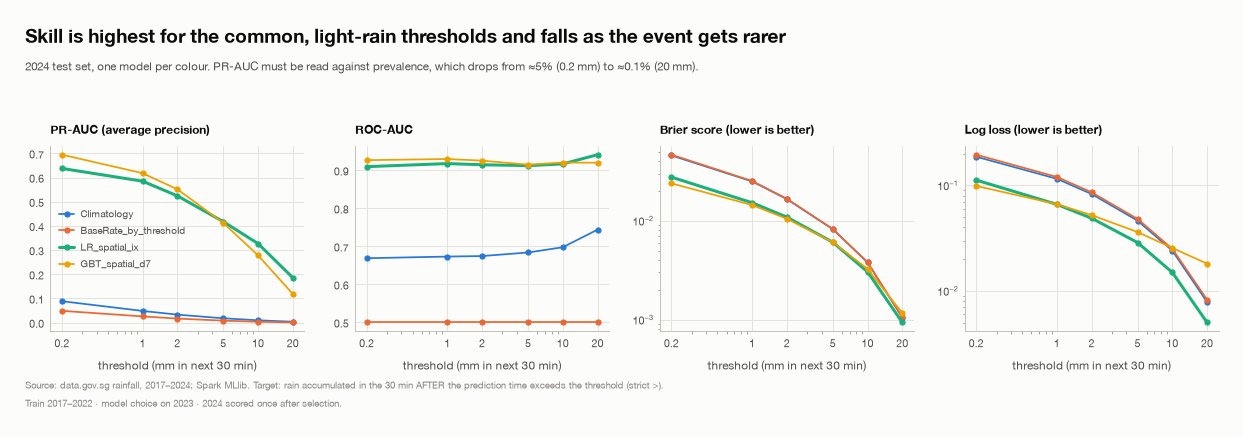

  [figure] outputs/figures/fig11_task2_metrics_by_threshold.png


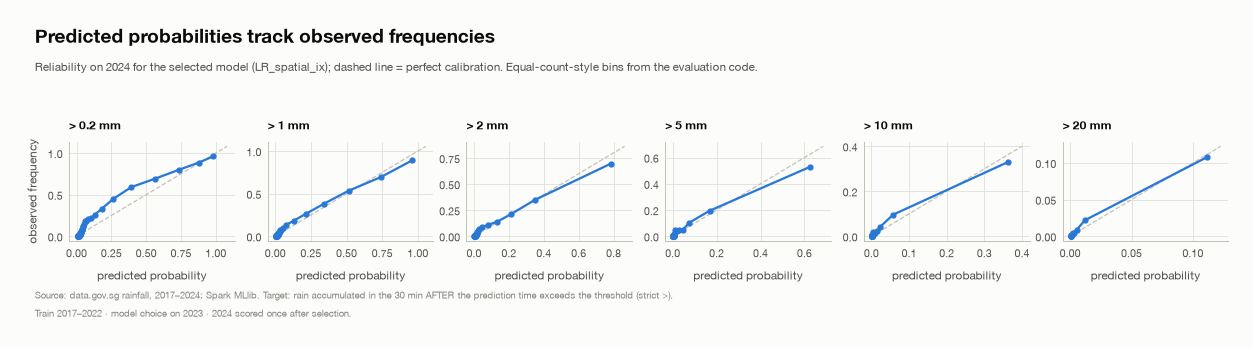

  [figure] outputs/figures/fig12_task2_calibration.png


In [51]:
META = json.loads((MODEL_DIR / "metadata.json").read_text())
SEL = META["selected_model"] + ("+cummin" if META["monotone_postprocess_cummin"] else "")
HEAD = META["headline_thresholds"]
SRC_T2 = ("Source: data.gov.sg rainfall, 2017–2024; Spark MLlib. Target: rain accumulated in the 30 min AFTER the "
          "prediction time exceeds the threshold (strict >).\nTrain 2017–2022 · model choice on 2023 · "
          "2024 scored once after selection.")

def colour_for(models):
    return {m: CAT[i % len(CAT)] for i, m in enumerate(models)}


def fig11_metrics_by_threshold():
    m = T("t30_task2_final_metrics")
    m = m[m["split"] == "test"]
    models = list(dict.fromkeys(m["model"]))
    col = colour_for(models)
    panels = [("pr_auc", "PR-AUC (average precision)", False), ("roc_auc", "ROC-AUC", False),
              ("brier", "Brier score (lower is better)", True), ("logloss", "Log loss (lower is better)", True)]
    fig, axs = plt.subplots(1, 4, figsize=(14, 4.6))
    for ax, (c, lab, logy) in zip(axs, panels):
        for mod in models:
            g = m[m["model"] == mod].sort_values("threshold_mm")
            ax.plot(g["threshold_mm"], g[c], marker="o", ms=4, lw=2.4 if mod == SEL.replace("+cummin", "") else 1.4,
                    color=col[mod], label=mod)
        ax.set_xscale("log")
        if logy:
            ax.set_yscale("log")
        ax.set_xticks(HEAD)
        ax.set_xticklabels([f"{h:g}" for h in HEAD])
        ax.set_xlabel("threshold (mm in next 30 min)")
        ax.set_title(lab, fontsize=9.5, loc="left")
        despine(ax)
    axs[0].legend(frameon=False, fontsize=8)
    layout(fig, header=1.55, footer=1.0, left=0.7)
    titleblock(fig, "Skill is highest for the common, light-rain thresholds and falls as the event gets rarer",
                 "2024 test set, one model per colour. PR-AUC must be read against prevalence, which drops from ≈5% (0.2 mm) to ≈0.1% (20 mm).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig11_task2_metrics_by_threshold.png")


def fig12_calibration():
    r = T("t31_task2_reliability")
    r = r[(r["split"] == "test") & (r["model"] == SEL)]
    fig, axs = plt.subplots(1, len(HEAD), figsize=(14, 3.6), sharex=False, sharey=False)
    for ax, h in zip(np.atleast_1d(axs), HEAD):
        g = r[(r["threshold_mm"] == h) & (r["n_pos"] > 0)]
        hi = max(g["mean_pred"].max(), g["obs_freq"].max()) * 1.1 if len(g) else 1
        ax.plot([0, hi], [0, hi], color=AXIS, lw=1, ls="--")
        ax.plot(g["mean_pred"], g["obs_freq"], marker="o", ms=4, color=CAT[0], lw=1.8)
        ax.set_title(f"> {h:g} mm", fontsize=9.5, loc="left")
        ax.set_xlabel("predicted probability")
        despine(ax)
    np.atleast_1d(axs)[0].set_ylabel("observed frequency")
    layout(fig, header=1.5, footer=1.0, left=0.8)
    titleblock(fig, "Predicted probabilities track observed frequencies",
                 f"Reliability on 2024 for the selected model ({SEL}); dashed line = perfect calibration. Equal-count-style bins from the evaluation code.")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig12_task2_calibration.png")


def fig13_pr_curves():
    p = T("t32_task2_pr_curves")
    p = p[(p["split"] == "test") & (p["model"] == SEL)]
    fig, ax = plt.subplots(figsize=(8.2, 5.4))
    for i, h in enumerate(HEAD):
        g = p[p["threshold_mm"] == h].sort_values("recall")
        ax.plot(g["recall"], g["precision"], lw=2, color=CAT[i % len(CAT)], label=f"> {h:g} mm")
    ax.set_xlabel("recall")
    ax.set_ylabel("precision")
    ax.set_ylim(0, 1.02)
    ax.set_xlim(0, 1)
    ax.legend(frameon=False, title="threshold")
    despine(ax)
    layout(fig, header=1.45, footer=1.0, left=0.95)
    titleblock(fig, "Precision falls quickly as recall is pushed up, most steeply for heavy rain",
                 f"Precision–recall curves on 2024, selected model ({SEL}).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig13_task2_pr_curves.png")


def fig14_models_and_effects():
    s = T("t34_task2_macro_summary")
    s = s[s["split"] == "test"].set_index("model")
    fe = T("t37_task2_feature_effects")
    fe = fe[fe["coefficient"].notna()].copy()
    fe["a"] = fe["std_effect"].abs()
    fe = fe.sort_values("a").tail(12)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
    metric = "macro_pr_auc"
    a1.barh(s.index, s[metric], color=[CAT[0] if i == SEL.replace("+cummin", "") else MUTED for i in s.index])
    a1.set_xlabel("macro-average PR-AUC over thresholds (2024)")
    despine(a1)
    a2.barh(fe["feature"], fe["std_effect"], color=[CAT[0] if v > 0 else RED for v in fe["std_effect"]])
    a2.set_xlabel("logistic effect per 1 SD of the feature (log-odds)")
    despine(a2)
    layout(fig, header=1.55, footer=1.0, left=2.0)
    titleblock(fig, "Recent rain nearby and the threshold itself dominate; model comparison on the left",
                 "Left: macro PR-AUC on the untouched 2024 test set. Right: largest standardized effects of the best logistic model (fit on training years).")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig14_task2_models_and_effects.png")


def fig15_threshold_sweep():
    d = T("t38_task2_threshold_sweep")
    fig, ax = plt.subplots(figsize=(8.6, 5.4))
    for i, (cs, g) in enumerate(d.groupby("case", sort=False)):
        g = g.sort_values("threshold_mm")
        ax.plot(g["threshold_mm"], g["p_final"], lw=2.2, color=CAT[i % len(CAT)], label=cs)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("rainfall threshold (mm in next 30 min)")
    ax.set_ylabel("P(rain > threshold)")
    ax.legend(frameon=False, fontsize=8, title="recent-rain state at prediction time")
    despine(ax)
    st = d["station_id"].iloc[0]
    layout(fig, header=1.45, footer=1.0, left=0.95)
    titleblock(fig, "The model answers for any threshold, and the probability falls as the threshold rises",
                 f"Station {st}, 2024 afternoon prediction times chosen by recent-rain state. Same station, four conditions, 36+ thresholds.")
    sourcenote(fig, SRC_T2)
    save_figure(fig, FIGURES / "fig15_task2_threshold_sweep.png")


open_pdf(FIGURES / "task2_all_figures.pdf", title="Task 2 figures")
fig11_metrics_by_threshold()
fig12_calibration()

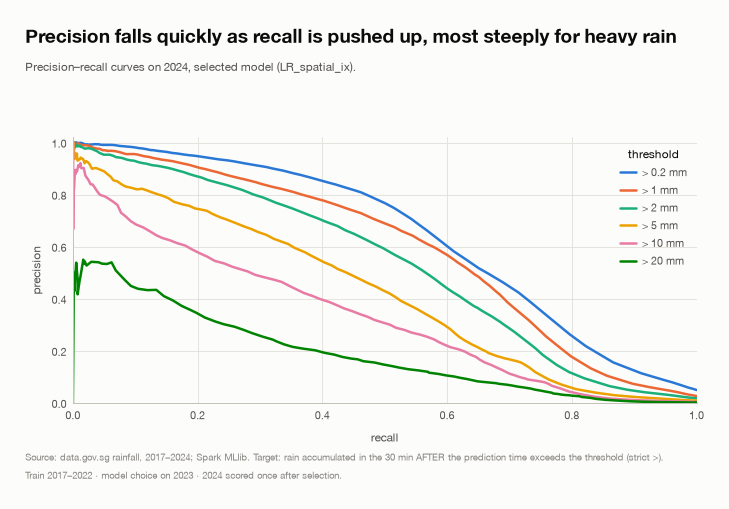

  [figure] outputs/figures/fig13_task2_pr_curves.png


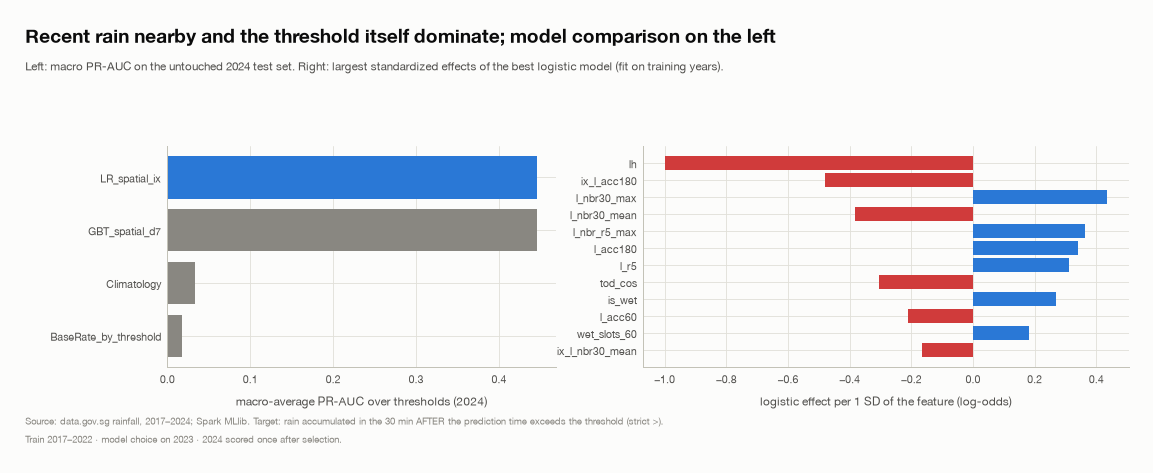

  [figure] outputs/figures/fig14_task2_models_and_effects.png


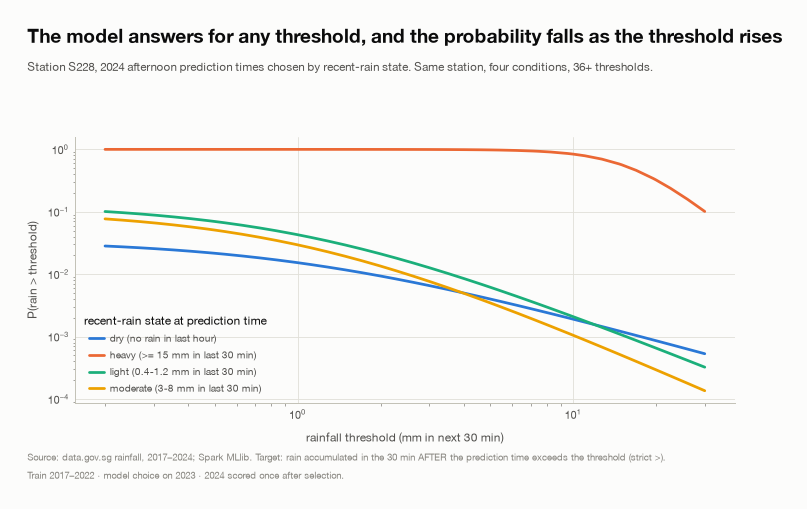

  [figure] outputs/figures/fig15_task2_threshold_sweep.png
Task 2 figures collected in outputs/figures/task2_all_figures.pdf


In [52]:
fig13_pr_curves()
fig14_models_and_effects()
fig15_threshold_sweep()
close_pdf()
print("Task 2 figures collected in outputs/figures/task2_all_figures.pdf")

**Results on the untouched 2024 test year.**

* **The selected logistic model beats both baselines at every threshold.** Averaged over the six thresholds it
  reaches PR-AUC 0.446 and ROC-AUC 0.919 against climatology's 0.034 and 0.690, and removes 39 % of climatology's
  log loss and 28 % of its Brier score. Test performance matches validation (macro PR-AUC 0.458 on 2023), so the
  model did not overfit the selection year.
* **At 5 mm** (0.83 % of half-hours) PR-AUC is 0.418, about 50× the event rate, with ROC-AUC 0.912; at the 2023
  cut-off it catches 44 % of the events with 50 % precision (F1 0.47). Skill falls as events get rarer: PR-AUC 0.64
  at 0.2 mm down to 0.19 at 20 mm, although ROC-AUC stays above 0.9 throughout.
* **Calibration.** The mean forecast is within 0.1 percentage points of the event rate at every threshold from 1 mm
  up (0.82 % vs 0.83 % at 5 mm), and the reliability curves stay close to the diagonal, slightly over-confident in the top bin (0.62
  predicted vs 0.53 observed at 5 mm). At 0.2 mm the model under-forecasts the middle of the range.
* **The probability always falls as the threshold rises:** 0 violations in 25.8 M adjacent threshold pairs. This
  holds for every physically valid input: the threshold's own coefficient (−1.23 on log(1 + *h*)) outweighs the two
  positive interaction terms because a 30-minute total cannot exceed the 180-minute total and a neighbour maximum
  cannot exceed 4× the neighbour mean.
* **What drives it** (Fig 14, `t37`): after the threshold itself (−1.0 log-odds per standard deviation), the
  strongest effects are rain at the neighbouring gauges (their 30-minute maximum and latest 5-minute maximum), the
  station's own rain in the last 5 minutes and the last 3 hours, and the time of day (higher probabilities in the
  daytime, as in Fig 5). The negative threshold × 3-hour-rain interaction means recent rain raises the chance of light
  rain more than of heavy rain. Correlated features (e.g. neighbour mean and maximum) share their effect, so their
  coefficients should be read together.
* **The GBT ranks about as well** (macro PR-AUC 0.446 vs 0.446, ROC-AUC 0.923 vs 0.919) but its log-loss skill is
  only 0.02 (at 20 mm its mean forecast is 1.5 % against a 0.1 % event rate), so the calibrated logistic model is
  the better answer to a question that asks for a probability. The GBT's scores also shift slightly between runs
  (macro PR-AUC 0.446–0.451 over four runs) because Spark's row subsampling for boosting depends on how the data are
  partitioned; the logistic model is deterministic.

## 12. Using the trained model: `predict(station, time, threshold)`

The model is reloaded from disk (the submitted artefact), and the features for the requested time are rebuilt from
the cleaned readings with the **same functions** that built the training table, using only readings at or before
the prediction time. Times are SGT and snapped down to the 5-minute grid; the gauge needs a complete 3-hour history.

**To use the saved model without retraining:** run Section 0, then every cell whose first line is `# definitions`
(in Sections 4, 4.3, 6, 7 and 10; they only define functions and constants), then this section. It needs the silver
layer from Section 3 (`data_parquet/silver/`).

In [53]:
from pyspark.ml import PipelineModel

stations = spark.read.parquet(str(SILVER / "stations")).toPandas()
FIVE = pd.Timedelta(minutes=5)
saved_model = PipelineModel.load(str(MODEL_DIR / "pipeline_model"))
saved_meta = json.loads((MODEL_DIR / "metadata.json").read_text())
FIRST_SLOT, LAST_SLOT = pd.Timestamp("2017-01-01 00:00:00"), pd.Timestamp("2024-12-31 23:55:00")
HISTORY_SLOTS = 36           # 3 h of complete 5-minute history

class PredictionError(ValueError):
    """A request that cannot be answered, with a user-facing reason."""


def check_inputs(station, time_str, threshold, meta, known_stations):
    if station not in known_stations:
        near = [s for s in known_stations if s.lower().startswith(station.lower()[:2])][:8]
        raise PredictionError(f"Unknown station '{station}'. {len(known_stations)} stations are known "
                              f"(e.g. {', '.join(sorted(known_stations)[:8])}...)." + (f" Similar: {near}" if near else ""))
    try:
        t = pd.Timestamp(time_str)
    except Exception:
        raise PredictionError(f"Cannot parse time '{time_str}'. Use e.g. '2024-10-01 15:00:00' (SGT).")
    if t.tzinfo is not None:
        t = t.tz_convert("Asia/Singapore").tz_localize(None)
    if not math.isfinite(threshold):
        raise PredictionError("Threshold must be a finite number of millimetres.")
    if threshold < 0:
        raise PredictionError(f"Threshold must not be negative (got {threshold} mm).")
    lo, hi = min(meta["threshold_grid"]), max(meta["threshold_grid"])
    if not lo <= threshold <= hi:
        raise PredictionError(f"Threshold {threshold} mm is outside the supported range {lo}-{hi} mm "
                              f"(gauge resolution is 0.2 mm; the model was trained on {lo}-{hi} mm).")
    t_snap = t.floor("5min")
    anchor = t_snap - FIVE                      # last fully observed interval
    if anchor > LAST_SLOT or anchor < FIRST_SLOT + (HISTORY_SLOTS - 1) * FIVE:
        raise PredictionError(
            f"Prediction time {t} is outside the available history: the cleaned data run "
            f"{FIRST_SLOT + HISTORY_SLOTS * FIVE} to {LAST_SLOT + FIVE} (3 h of history are needed).")
    return t, t_snap, anchor


def features_at(station, anchor):
    """One-row frame of prediction-time features, built from readings at or before the anchor slot."""
    nbr_s = [e for e in neighbour_map(stations) if e[0] == station]
    ids = [station] + [e[1] for e in nbr_s]
    lo = anchor - 185 * pd.Timedelta(minutes=1)
    rd = (spark.read.parquet(str(SILVER / "readings"))
          .filter(F.col("year").isin(sorted({lo.year, anchor.year})) & F.col("station_id").isin(ids))
          .filter((F.col("ts") >= F.to_timestamp(F.lit(str(lo)))) & (F.col("ts") <= F.to_timestamp(F.lit(str(anchor)))))
          .select("station_id", "ts", "rain_mm"))             # nothing after the anchor is even loaded
    tr_ = add_trailing_features(rd).cache()
    row = tr_.filter((F.col("station_id") == station) & (F.col("ts") == F.to_timestamp(F.lit(str(anchor)))))
    if row.count() == 0:
        raise PredictionError(f"No observation for {station} in the 5-minute interval ending at {anchor + FIVE}: "
                              "the gauge was not reporting.")
    if row.filter(F.col("acc180").isNotNull()).count() == 0:
        n_hist = tr_.filter(F.col("station_id") == station).count()
        raise PredictionError(f"Insufficient recent history for {station} before {anchor + FIVE}: {n_hist} of "
                              f"{HISTORY_SLOTS} five-minute readings in the previous 3 h (a complete record is required).")
    loc = stations[stations["station_id"] == station][["station_id", "lat", "lon"]]
    row = row.join(F.broadcast(spark.createDataFrame(loc)), "station_id")
    lookup_ = tr_.filter(F.col("acc60").isNotNull()).select("station_id", "ts", "r5", "acc30", "acc60")
    return add_time_features(add_neighbour_features(spark, row, lookup_, nbr_s))


def predict(station, time_str, threshold, curve=False):
    """P(rain over the next 30 minutes > threshold mm) at `station` for a prediction time in SGT."""
    threshold = float(threshold)
    t, t_snap, anchor = check_inputs(station, time_str, threshold, saved_meta, set(stations["station_id"]))
    row = features_at(station, anchor)
    grid = sorted(set(saved_meta["threshold_grid"]) | {threshold})
    ths = ([g for g in grid if (g <= threshold or curve)]
           if (saved_meta["monotone_postprocess_cummin"] or curve) else [threshold])
    ths = sorted(set(ths) | {threshold})
    x = row.crossJoin(F.broadcast(spark.createDataFrame([(float(g),) for g in ths], ["threshold_mm"])))
    out = (saved_model.transform(add_model_inputs(x))
           .select("threshold_mm", vector_to_array("probability")[1].alias("p")).toPandas()
           .sort_values("threshold_mm"))
    if saved_meta["monotone_postprocess_cummin"]:
        out["p"] = out["p"].cummin()            # P(R > h) cannot increase with h
    p = float(out.loc[(out["threshold_mm"] - threshold).abs().idxmin(), "p"])
    info = row.select("acc30", "acc60", "r5", "nbr_acc30_max", "n_nbr").first().asDict()
    return {"station": station, "time": t, "time_used": t_snap, "threshold": threshold, "probability": p,
            "curve": out if curve else None, "inputs": info}


r = predict("S77", "2024-10-01 15:00:00", 5, curve=True)
print(f"Station {r['station']}, prediction time {r['time']:%Y-%m-%d %H:%M} SGT, threshold {r['threshold']:g} mm")
print(f"P(> {r['threshold']:g} mm in the next 30 minutes) = {r['probability']:.3f}")
i = r["inputs"]
print(f"(recent rain: last 5 min {i['r5']:.1f} mm, last 30 min {i['acc30']:.1f} mm, last 60 min {i['acc60']:.1f} mm; "
      f"{i['n_nbr']} neighbouring gauges reporting)")
r["curve"].round(4)

Station S77, prediction time 2024-10-01 15:00 SGT, threshold 5 mm
P(> 5 mm in the next 30 minutes) = 0.004
(recent rain: last 5 min 0.0 mm, last 30 min 0.2 mm, last 60 min 0.2 mm; 3 neighbouring gauges reporting)


,threshold_mm,p
0,0.2,0.0335
1,0.5,0.0247
2,1.0,0.0167
3,2.0,0.0096
4,3.0,0.0064
5,5.0,0.0037
6,7.5,0.0023
7,10.0,0.0016
8,15.0,0.0009
9,20.0,0.0006


In [54]:
# the same station during a storm, and requests the model must refuse
storm = (feats.filter((F.col("split") == "test") & (F.col("acc30") >= 10)).orderBy("pred_time")
         .withColumn("when", F.date_format("pred_time", "yyyy-MM-dd HH:mm:ss")).first())
when = storm["when"]
for h in (1, 5, 10, 20):
    r = predict(storm["station_id"], when, h)
    print(f"{storm['station_id']} at {when}: P(> {h:>2} mm) = {r['probability']:.3f}   "
          f"(last 30 min {r['inputs']['acc30']:.1f} mm; actual next 30 min {storm['future_30min_mm']:.1f} mm)")
for bad in [("S999", "2024-10-01 15:00:00", 5), ("S77", "2024-10-01 15:00:00", 45), ("S77", "2016-05-01 12:00", 5)]:
    try:
        predict(*bad)
    except PredictionError as e:
        print(f"refused {bad}: {e}")

S201 at 2024-01-01 13:55:00: P(>  1 mm) = 0.998   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(>  5 mm) = 0.938   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(> 10 mm) = 0.713   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)


S201 at 2024-01-01 13:55:00: P(> 20 mm) = 0.265   (last 30 min 12.2 mm; actual next 30 min 1.4 mm)
refused ('S999', '2024-10-01 15:00:00', 5): Unknown station 'S999'. 91 stations are known (e.g. S06, S07, S08, S100, S101, S102, S103, S104...). Similar: ['S900', 'S92', 'S90', 'S96', 'S91', 'S94', 'S97']
refused ('S77', '2024-10-01 15:00:00', 45): Threshold 45.0 mm is outside the supported range 0.2-30.0 mm (gauge resolution is 0.2 mm; the model was trained on 0.2-30.0 mm).
refused ('S77', '2016-05-01 12:00', 5): Prediction time 2016-05-01 12:00:00 is outside the available history: the cleaned data run 2017-01-01 03:00:00 to 2025-01-01 00:00:00 (3 h of history are needed).


A single forecast can miss: in the storm above, the model gives a high probability of more than 5 mm after
12 mm fell in the previous half-hour, but the storm stopped. Probabilities are judged over many forecasts, which is
what the reliability diagrams in Section 11 do.

## 13. Summary

**Data engineering.** 7.5 GB of CSV (48.5 M readings, 91 gauges) → bronze Parquet → silver after cleaning (99.6 % kept;
timestamp alignment, 86 duplicates, one impossible value, 67 dead-gauge station-months, 4 spike days) → analysis
tables and a 46 M-row feature table, all with Spark DataFrames, window functions and broadcast joins.

**Task 1.** Annual rainfall ranges from 1,787 mm (2019) to 2,900 mm (2021); dry years have fewer rain events, not
lighter rain. Two wet seasons (Nov–Jan, Apr–May) and two diurnal regimes (10:00 in the south-west monsoon, 15:00–16:00
otherwise). Rain is concentrated (10 % of wet slots give 49 % of the rain), 2.1× wetter in the west than the east, and
decorrelates within ~8.5 km. Heavy half-hours were ~23 % more frequent in 2020–24 than 2017–19, but over eight years no
series shows a statistically significant trend. Results are robust to the changing gauge network.

**Task 2.** One Spark MLlib logistic-regression pipeline answers P(rain in the next 30 min > *h*) for any station,
time and threshold in 0.2–30 mm. On the untouched 2024 test year it reaches macro PR-AUC 0.446 and ROC-AUC 0.919
(climatology 0.034 and 0.690), removes 39 % of climatology's log loss, is well calibrated from 1 mm upwards and
monotone in the threshold. Limitations: a single test year; thin data above 20 mm; no radar or satellite inputs;
the GBT was compared uncalibrated (recalibrating it could make its competitive ranking usable).

In [55]:
timings = write_table(pd.DataFrame(TIMINGS), "t40_stage_timings")
print(f"total timed: {timings['seconds'].sum() / 60:.1f} min")
timings

  [table] outputs/tables/t40_stage_timings.csv  (30 rows)
total timed: 9.9 min


,stage,seconds
0,1. ingest: CSV -> bronze Parquet,18.2
1,2. data-quality audit,6.4
2,3a. clean: snap + de-duplicate + station table,11.9
3,3b. clean: dead-gauge station-months,2.8
4,3c. clean: spike station-days,9.1
5,3d. clean: write silver Parquet,14.3
6,4a. station-day + coverage tables,2.5
7,4b. island daily series + gap fill,1.1
8,5.3 fixed-network sensitivity,1.1
9,5.4 diurnal cycle,1.6


In [56]:
spark.stop()